# SmartRetail: All Model Implementations & Results

**An executable Google Colab laboratory for the actual SmartRetail project.**

The notebook embeds the full Python implementations; it does not hide training behind an API or require cloning the repository. Saved outputs in the delivered file come from a full execution on the supplied datasets. Run it again with your copies to reproduce the analysis.

**Models included:** nine merchandise demand forecasters; new-product analogue matching with 5/8/12-neighbour comparison; purchase-intention prevalence/logistic/forest comparison; RFM and wholesale KMeans with PCA; basket rules; and the two Version 1 aggregate forecast baselines. Three inputs match official UCI files byte-for-byte and have CC BY 4.0 licenses. Four unverified files are excluded from every calculation.

**Important:** country ranking is a retrospective catalogue-entry benchmark, not a validated launch-success model. The country baseline was not beaten. Unit/revenue scenarios and similarity scores are not success probabilities. WAPE is an error measure, not “accuracy.” Marketing, store and geography files are excluded; this notebook does not invent campaign, city-demand or location models.

## Run in Colab
1. Select **Runtime → Run all** on a CPU runtime.
2. The notebook defaults to `DATA_MODE = "drive"`. Mount the Google account containing `MyDrive/SmartRetailData`. Alternatively choose `DATA_MODE = "upload"` and select the three verified UCI inputs.
3. Let both training pipelines finish. The million-row workbook is read twice; memory/runtime requirements depend on the selected Colab runtime.
4. Inspect the Model Lab sections, assertions and limitations. The final cell offers a ZIP download of reports and source-fingerprint metadata.

Only upload files you are authorized to place in your Google Colab session. The notebook has no external prediction API, telemetry, or raw-data publishing step. The exported ZIP contains derived public-style artifacts, not raw files.

## 1. Provenance and project reference

Generated from the working copy based on project commit `6b762d8cd73b1f6cc3dc2e90031915c20bee35fc`. The exact script SHA-256 hashes below identify the implementation, including changes made after that base commit; this is not a claim that the base commit already contains those changes. Notebook adaptation removes CLI entry points, renames the two `main` functions, embeds the source allowlist, and adds ROC/precision–recall diagnostics without changing training decisions. The notebook itself has different bytes from the scripts.

Reference results are embedded so the file remains reviewable without an internet connection. They are **previous project-run results**, not newly executed output until the training cells finish.

In [1]:
PROJECT_COMMIT = '6b762d8cd73b1f6cc3dc2e90031915c20bee35fc'
LEGACY_SCRIPT_SHA256 = 'c98105874286b0650a80ed893e8181a855e6acb298024f3b0b80417a5f865457'
MARKET_SCRIPT_SHA256 = 'dfdc34c77f6618612f91797692c8c212f889d3e190bd0889951ad5dd6cc0cee9'
SOURCE_AUDIT = {'checkedAt': '2026-10-21T10:36:54.256938+00:00', 'policy': 'Only exact official UCI copies are accepted by the public benchmark pipelines. No generated or augmented training rows.', 'sources': [{'source': 'retail', 'file': 'transactions/online_retail_II.xlsx', 'status': 'verified-exact', 'sha256': 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980', 'officialMemberSHA256': 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980', 'archiveSHA256': '572e36277c2390fbfde10664750731e0a86f55e33470d91919085f0408e67bfb', 'bytes': 45622278, 'archiveURL': 'https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip', 'sourceURL': 'https://archive.ics.uci.edu/dataset/502/online+retail+ii', 'archiveMember': 'online_retail_II.xlsx', 'license': 'CC BY 4.0', 'attribution': 'Chen, D. (2012)', 'doi': '10.24432/C5CG6D'}, {'source': 'purchase', 'file': 'digital/online_shoppers_intention.csv', 'status': 'verified-exact', 'sha256': 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9', 'officialMemberSHA256': 'b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9', 'archiveSHA256': '2972e6184d3ad7beaaa831d9fc2b059dc3ee29df69d1ec593c466a5cd8485d14', 'bytes': 1072063, 'archiveURL': 'https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip', 'sourceURL': 'https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset', 'archiveMember': 'online_shoppers_intention.csv', 'license': 'CC BY 4.0', 'attribution': 'Sakar, C. & Kastro, Y. (2018)', 'doi': '10.24432/C5F88Q'}, {'source': 'wholesale', 'file': 'Wholesale customers data.csv', 'status': 'verified-exact', 'sha256': 'c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef', 'officialMemberSHA256': 'c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef', 'archiveSHA256': '647e6a61683ed23f48c7b04e1e2be78835eca8758b32267603fc42a1479dbfb8', 'bytes': 15021, 'archiveURL': 'https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip', 'sourceURL': 'https://archive.ics.uci.edu/dataset/292/wholesale+customers', 'archiveMember': 'Wholesale customers data.csv', 'license': 'CC BY 4.0', 'attribution': 'Cardoso, M. (2013)', 'doi': '10.24432/C5030X'}, {'file': 'marketing_campaign.csv', 'status': 'excluded-unverified', 'exists': True, 'sha256': 'cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948f722af81abc6b990ea', 'reason': 'Real-world origin and redistribution license of this exact file are unverified. Excluded from training, descriptive outputs and notebook inputs; this does not prove it is synthetic.'}, {'file': 'store/store_sales_data (2).csv', 'status': 'excluded-unverified', 'exists': True, 'sha256': 'df1dd4a0d6bd486d34499e87b249e875f2a03bc407f5ffdddddf34bea80e727e', 'reason': 'Real-world origin and redistribution license of this exact file are unverified. Excluded from training, descriptive outputs and notebook inputs; this does not prove it is synthetic.'}, {'file': 'geo/geolocations-indian-cities.csv', 'status': 'excluded-unverified', 'exists': True, 'sha256': '9e112742dfda58666fe32a8ec494fa21e604e534c850a18a9193f6ecac27c0e2', 'reason': 'Real-world origin and redistribution license of this exact file are unverified. Excluded from training, descriptive outputs and notebook inputs; this does not prove it is synthetic.'}, {'file': 'geo/Pincode_Dataset.csv', 'status': 'excluded-unverified', 'exists': True, 'sha256': '9ea783f743804131ce8b369a35565f40ce81228788134c014d3faceacaa51957', 'reason': 'Real-world origin and redistribution license of this exact file are unverified. Excluded from training, descriptive outputs and notebook inputs; this does not prove it is synthetic.'}]}
REFERENCE_RESULTS = {'generatedAt': '2026-10-21T10:50:31.374480+00:00', 'sourceSHA256': 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980', 'demand': [{'model': 'Last 28 days', 'validation': {'mae': 108.46361806154731, 'wape': 0.5596475268858692, 'rmse': 260.1670687319478, 'rows': 3477}, 'test': {'mae': 120.23493670886076, 'wape': 0.45536811786521747, 'rmse': 286.9775715666269, 'rows': 1975}}, {'model': '84-day daily mean', 'validation': {'mae': 104.8702904802991, 'wape': 0.5411067762629718, 'rmse': 243.53188194183028, 'rows': 3477}, 'test': {'mae': 131.32725738396624, 'wape': 0.4973782800264121, 'rmse': 351.28018989738945, 'rows': 1975}}, {'model': 'Damped trend', 'validation': {'mae': 132.52811663181097, 'wape': 0.6838148500057233, 'rmse': 328.4086969138733, 'rows': 3477}, 'test': {'mae': 142.19918282061053, 'wape': 0.538553735007883, 'rmse': 348.2485600514186, 'rows': 1975}}, {'model': 'Gradient boosting (log units)', 'validation': {'mae': 100.23733875500392, 'wape': 0.517201802211933, 'rmse': 241.89034949464923, 'rows': 3477}, 'test': {'mae': 118.32735212285125, 'wape': 0.4481434856046023, 'rmse': 357.3353758941388, 'rows': 1975}}, {'model': 'Gradient boosting (Poisson)', 'validation': {'mae': 105.58567634751168, 'wape': 0.5447980041466611, 'rmse': 245.86357680535275, 'rows': 3477}, 'test': {'mae': 132.7625154443533, 'wape': 0.5028140608360442, 'rmse': 394.6555163050121, 'rows': 1975}}, {'model': 'History boosting (absolute error)', 'validation': {'mae': 94.36514487559052, 'wape': 0.4869026213368932, 'rmse': 231.6601006834121, 'rows': 3477}, 'test': {'mae': 129.47463014789986, 'wape': 0.4903617888077561, 'rmse': 386.26743879577884, 'rows': 1975}}, {'model': 'History boosting (log units)', 'validation': {'mae': 94.81690246022231, 'wape': 0.4892335874203559, 'rmse': 233.32551405808297, 'rows': 3477}, 'test': {'mae': 123.11249718666832, 'wape': 0.4662663587150918, 'rmse': 372.81186452966796, 'rows': 1975}}, {'model': 'History boosting (Poisson)', 'validation': {'mae': 110.33725102304354, 'wape': 0.5693150455611009, 'rmse': 234.0007800689258, 'rows': 3477}, 'test': {'mae': 131.6936540183487, 'wape': 0.49876594113688366, 'rmse': 368.3821052749688, 'rows': 1975}}, {'model': 'History extra trees', 'validation': {'mae': 106.15133576952447, 'wape': 0.5477166777281519, 'rmse': 230.16298848796833, 'rows': 3477}, 'test': {'mae': 117.04464378672071, 'wape': 0.44328545933717767, 'rmse': 342.5143513444121, 'rows': 1975}}], 'selectedDemand': 'Gradient boosting (log units)', 'coldStart': {'selectedNeighbors': 8, 'results': [{'neighbors': 5, 'role': 'validation', 'total': 223, 'supported': 199, 'coverage': 0.8923766816143498, 'topCountryHitRate': 0.8894472361809045, 'baselineHitRate': 0.8894472361809045, 'unitMAE': 174.2107518190027, 'baselineUnitMAE': 131.54606365159128}, {'neighbors': 5, 'role': 'test', 'total': 28, 'supported': 26, 'coverage': 0.9285714285714286, 'topCountryHitRate': 0.8461538461538461, 'baselineHitRate': 0.8461538461538461, 'unitMAE': 474.64945914779486, 'baselineUnitMAE': 610.2564102564103}, {'neighbors': 8, 'role': 'validation', 'total': 223, 'supported': 203, 'coverage': 0.9103139013452914, 'topCountryHitRate': 0.8866995073891626, 'baselineHitRate': 0.8916256157635468, 'unitMAE': 169.89586935605988, 'baselineUnitMAE': 130.33825944170772}, {'neighbors': 8, 'role': 'test', 'total': 28, 'supported': 26, 'coverage': 0.9285714285714286, 'topCountryHitRate': 0.8461538461538461, 'baselineHitRate': 0.8461538461538461, 'unitMAE': 434.12123463368175, 'baselineUnitMAE': 610.2564102564103}, {'neighbors': 12, 'role': 'validation', 'total': 223, 'supported': 203, 'coverage': 0.9103139013452914, 'topCountryHitRate': 0.8866995073891626, 'baselineHitRate': 0.8916256157635468, 'unitMAE': 165.44197334887642, 'baselineUnitMAE': 130.33825944170772}, {'neighbors': 12, 'role': 'test', 'total': 28, 'supported': 27, 'coverage': 0.9642857142857143, 'topCountryHitRate': 0.7777777777777778, 'baselineHitRate': 0.8148148148148148, 'unitMAE': 433.05947085963663, 'baselineUnitMAE': 590.1111111111111}], 'folds': [{'cutoff': '2010-06-01', 'lastHistoryDate': '2010-05-30', 'role': 'validation', 'newProducts': 75}, {'cutoff': '2010-10-01', 'lastHistoryDate': '2010-09-30', 'role': 'validation', 'newProducts': 109}, {'cutoff': '2011-03-01', 'lastHistoryDate': '2011-02-28', 'role': 'validation', 'newProducts': 39}, {'cutoff': '2011-07-01', 'lastHistoryDate': '2011-06-30', 'role': 'test', 'newProducts': 28}], 'beatsCountryBaseline': False, 'protocol': 'Historical catalogue-entry simulation. At each cutoff, compare products first observed in the following 28 days with established products known before cutoff. Use only supplied description and first observed price as query metadata. Outcomes cover the first 28 recorded days per target. Three earlier cohorts select neighbor count; July 2011 cohort is final test. Unit estimates use preceding 84-day rates scaled to 28 days. As in the app, each supported country requires three active analogues and ten orders; average only active analogues. Unit MAE compares the sum over supported countries with target total recorded units.', 'limitation': 'First recorded sale is not a verified launch. Products with no sales never enter this dataset. Metadata must represent what was known before launch. No advertising, availability, distribution, competition or market-size features exist. This is not a launch-success probability or a causal expansion forecast.'}, 'purchase': [{'model': 'Prevalence baseline', 'threshold': 0.19999999999999996, 'rocAUC': 0.5, 'averagePrecision': 0.15649324047521507, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.8435067595247849, 'brier': 0.1320031248083381, 'confusionMatrix': [[2059, 0], [382, 0]], 'rocCurve': {'fpr': [0.0, 1.0], 'tpr': [0.0, 1.0]}, 'prCurve': {'precision': [0.15649324047521507, 1.0], 'recall': [1.0, 0.0]}}, {'model': 'Logistic regression', 'threshold': 0.19999999999999996, 'rocAUC': 0.7501710025453315, 'averagePrecision': 0.3295220019146626, 'precision': 0.30544993662864384, 'recall': 0.6308900523560209, 'f1': 0.4116140051238258, 'accuracy': 0.7177386317083163, 'brier': 0.11868871534383078, 'confusionMatrix': [[1511, 548], [141, 241]], 'rocCurve': {'fpr': [0.0, 0.0, 0.0, 0.00048567265662943174, 0.00048567265662943174, 0.0009713453132588635, 0.0009713453132588635, 0.0029140359397765905, 0.0029140359397765905, 0.003399708596406022, 0.003399708596406022, 0.003885381253035454, 0.003885381253035454, 0.004371053909664886, 0.004371053909664886, 0.0048567265662943174, 0.0048567265662943174, 0.005342399222923749, 0.005342399222923749, 0.005828071879553181, 0.005828071879553181, 0.007285089849441476, 0.007285089849441476, 0.007770762506070908, 0.007770762506070908, 0.008742107819329771, 0.008742107819329771, 0.009713453132588635, 0.009713453132588635, 0.010199125789218067, 0.010199125789218067, 0.012141816415735794, 0.012141816415735794, 0.013113161728994658, 0.013113161728994658, 0.015055852355512385, 0.015055852355512385, 0.015541525012141816, 0.015541525012141816, 0.018455560951918408, 0.018455560951918408, 0.01894123360854784, 0.01894123360854784, 0.020398251578436135, 0.020398251578436135, 0.020883924235065566, 0.020883924235065566, 0.021369596891694997, 0.021369596891694997, 0.023312287518212724, 0.023312287518212724, 0.023797960174842158, 0.023797960174842158, 0.02476930548810102, 0.02476930548810102, 0.025740650801359885, 0.025740650801359885, 0.027197668771248178, 0.027197668771248178, 0.027683341427877612, 0.027683341427877612, 0.03011170471102477, 0.03011170471102477, 0.0305973773676542, 0.0305973773676542, 0.03108305002428363, 0.03108305002428363, 0.03205439533754249, 0.03205439533754249, 0.03593977659057795, 0.03593977659057795, 0.036911121903836816, 0.036911121903836816, 0.03788246721709568, 0.03788246721709568, 0.04031083050024284, 0.04031083050024284, 0.04225352112676056, 0.04225352112676056, 0.04419621175327829, 0.04419621175327829, 0.04808159300631375, 0.04808159300631375, 0.04856726566294318, 0.04856726566294318, 0.04953861097620204, 0.04953861097620204, 0.0505099562894609, 0.0505099562894609, 0.0519669742593492, 0.0519669742593492, 0.05245264691597863, 0.05245264691597863, 0.05293831957260806, 0.05293831957260806, 0.054395337542496355, 0.054395337542496355, 0.05730937348227295, 0.05730937348227295, 0.05876639145216124, 0.05876639145216124, 0.06216610004856726, 0.06216610004856726, 0.06362311801845556, 0.06362311801845556, 0.06605148130160272, 0.06605148130160272, 0.06847984458474989, 0.06847984458474989, 0.06945118989800875, 0.06945118989800875, 0.07236522583778533, 0.07236522583778533, 0.0733365711510442, 0.0733365711510442, 0.07430791646430306, 0.07430791646430306, 0.07576493443419136, 0.07576493443419136, 0.0762506070908208, 0.0762506070908208, 0.07770762506070908, 0.07770762506070908, 0.07867897037396794, 0.07867897037396794, 0.0811073336571151, 0.0811073336571151, 0.0825643516270034, 0.0825643516270034, 0.08305002428363283, 0.08305002428363283, 0.08353569694026226, 0.08353569694026226, 0.0840213695968917, 0.0840213695968917, 0.08547838756677999, 0.08547838756677999, 0.08693540553666829, 0.08693540553666829, 0.08742107819329771, 0.08742107819329771, 0.09130645944633317, 0.09130645944633317, 0.09179213210296261, 0.09179213210296261, 0.0932491500728509, 0.0932491500728509, 0.0947061680427392, 0.0947061680427392, 0.09567751335599806, 0.09567751335599806, 0.09713453132588636, 0.09713453132588636, 0.09762020398251578, 0.09762020398251578, 0.09810587663914522, 0.09810587663914522, 0.10004856726566294, 0.10004856726566294, 0.10296260320543954, 0.10296260320543954, 0.10344827586206896, 0.10344827586206896, 0.1039339485186984, 0.1039339485186984, 0.10636231180184555, 0.10636231180184555, 0.11121903836813987, 0.11121903836813987, 0.11364740165128703, 0.11364740165128703, 0.1160757649344342, 0.1160757649344342, 0.11704711024769306, 0.11704711024769306, 0.11801845556095192, 0.11801845556095192, 0.12287518212724624, 0.12287518212724624, 0.12336085478387566, 0.12336085478387566, 0.12433220009713453, 0.12433220009713453, 0.12481787275376396, 0.12481787275376396, 0.12578921806702284, 0.12578921806702284, 0.12627489072365225, 0.12627489072365225, 0.12773190869354056, 0.12773190869354056, 0.12821758135016997, 0.12821758135016997, 0.1287032540067994, 0.1287032540067994, 0.13258863525983486, 0.13258863525983486, 0.1345313258863526, 0.1345313258863526, 0.13501699854298202, 0.13501699854298202, 0.13647401651287033, 0.13647401651287033, 0.13793103448275862, 0.13793103448275862, 0.1389023797960175, 0.1389023797960175, 0.1393880524526469, 0.1393880524526469, 0.13987372510927634, 0.13987372510927634, 0.14473045167557066, 0.14473045167557066, 0.1452161243322001, 0.1452161243322001, 0.1466731423020884, 0.1466731423020884, 0.14813016027197667, 0.14813016027197667, 0.149587178241865, 0.149587178241865, 0.15104419621175327, 0.15104419621175327, 0.15492957746478872, 0.15492957746478872, 0.15832928606119476, 0.15832928606119476, 0.16027197668771248, 0.16027197668771248, 0.16367168528411852, 0.16367168528411852, 0.17338513841670714, 0.17338513841670714, 0.17484215638659542, 0.17484215638659542, 0.17921321029626033, 0.17921321029626033, 0.17969888295288974, 0.17969888295288974, 0.18309859154929578, 0.18309859154929578, 0.18455560951918407, 0.18455560951918407, 0.1850412821758135, 0.1850412821758135, 0.18601262748907235, 0.18601262748907235, 0.1864983001457018, 0.1864983001457018, 0.18892666342884895, 0.18892666342884895, 0.1894123360854784, 0.1894123360854784, 0.18989800874210783, 0.18989800874210783, 0.19038368139873726, 0.19038368139873726, 0.19329771733851384, 0.19329771733851384, 0.19378338999514327, 0.19378338999514327, 0.19621175327829043, 0.19621175327829043, 0.19669742593491987, 0.19669742593491987, 0.1986401165614376, 0.1986401165614376, 0.19912578921806703, 0.19912578921806703, 0.20009713453132588, 0.20009713453132588, 0.20058280718795532, 0.20058280718795532, 0.2015541525012142, 0.2015541525012142, 0.20349684312773192, 0.20349684312773192, 0.20592520641087908, 0.20592520641087908, 0.20738222438076737, 0.20738222438076737, 0.2078678970373968, 0.2078678970373968, 0.2112676056338028, 0.2112676056338028, 0.2122389509470617, 0.2122389509470617, 0.2141816415735794, 0.2141816415735794, 0.21903836813987373, 0.21903836813987373, 0.22000971345313258, 0.22000971345313258, 0.22049538610976202, 0.22049538610976202, 0.2214667314230209, 0.2214667314230209, 0.22340942204953862, 0.22340942204953862, 0.22438076736279747, 0.22438076736279747, 0.22583778533268578, 0.22583778533268578, 0.2263234579893152, 0.2263234579893152, 0.22680913064594463, 0.22680913064594463, 0.22729480330257407, 0.22729480330257407, 0.23069451189898008, 0.23069451189898008, 0.2321515298688684, 0.2321515298688684, 0.23360854783875667, 0.23360854783875667, 0.23457989315201555, 0.23457989315201555, 0.23943661971830985, 0.23943661971830985, 0.241864983001457, 0.241864983001457, 0.24332200097134532, 0.24332200097134532, 0.2447790189412336, 0.2447790189412336, 0.24575036425449248, 0.24575036425449248, 0.24720738222438077, 0.24720738222438077, 0.24817872753763964, 0.24817872753763964, 0.24866440019426905, 0.24866440019426905, 0.24963574550752793, 0.24963574550752793, 0.25012141816415734, 0.25012141816415734, 0.2525497814473045, 0.2525497814473045, 0.25643516270033995, 0.25643516270033995, 0.2569208353569694, 0.2569208353569694, 0.2588635259834871, 0.2588635259834871, 0.259834871296746, 0.259834871296746, 0.26080621661000486, 0.26080621661000486, 0.26129188926663427, 0.26129188926663427, 0.2646915978630403, 0.2646915978630403, 0.26857697911607575, 0.26857697911607575, 0.27003399708596404, 0.27003399708596404, 0.27294803302574067, 0.27294803302574067, 0.2734337056823701, 0.2734337056823701, 0.27489072365225836, 0.27489072365225836, 0.277804759592035, 0.277804759592035, 0.2782904322486644, 0.2782904322486644, 0.2797474502185527, 0.2797474502185527, 0.28703254006799417, 0.28703254006799417, 0.2918892666342885, 0.2918892666342885, 0.2923749392909179, 0.2923749392909179, 0.29286061194754737, 0.29286061194754737, 0.29626032054395335, 0.29626032054395335, 0.2986886838271005, 0.2986886838271005, 0.2996600291403594, 0.2996600291403594, 0.30111704711024767, 0.30111704711024767, 0.30208839242350655, 0.30208839242350655, 0.30354541039339483, 0.30354541039339483, 0.3040310830500243, 0.3040310830500243, 0.3050024283632832, 0.3050024283632832, 0.30791646430305974, 0.30791646430305974, 0.30840213695968915, 0.30840213695968915, 0.3088878096163186, 0.3088878096163186, 0.3113161728994658, 0.3113161728994658, 0.31277319086935407, 0.31277319086935407, 0.31374453618261294, 0.31374453618261294, 0.31471588149587176, 0.31471588149587176, 0.31568722680913064, 0.31568722680913064, 0.3190869354055367, 0.3190869354055367, 0.323943661971831, 0.323943661971831, 0.3254006799417193, 0.3254006799417193, 0.32928606119475473, 0.32928606119475473, 0.3317144244779019, 0.3317144244779019, 0.34094220495386107, 0.34094220495386107, 0.3438562408936377, 0.3438562408936377, 0.3443419135502671, 0.3443419135502671, 0.34822729480330256, 0.34822729480330256, 0.34968431277319084, 0.34968431277319084, 0.35502671199611463, 0.35502671199611463, 0.3559980573093735, 0.3559980573093735, 0.36036911121903836, 0.36036911121903836, 0.3686255463817387, 0.3686255463817387, 0.3705682370082564, 0.3705682370082564, 0.37251092763477417, 0.37251092763477417, 0.37493929091792133, 0.37493929091792133, 0.38465274405051, 0.38465274405051, 0.391452161243322, 0.391452161243322, 0.3963088878096163, 0.3963088878096163, 0.4045653229723167, 0.4045653229723167, 0.4050509956289461, 0.4050509956289461, 0.40699368625546384, 0.40699368625546384, 0.4084507042253521, 0.4084507042253521, 0.4157357940747936, 0.4157357940747936, 0.4220495386109762, 0.4220495386109762, 0.4239922292374939, 0.4239922292374939, 0.4254492472073822, 0.4254492472073822, 0.42884895580378823, 0.42884895580378823, 0.43370568237008256, 0.43370568237008256, 0.43516270033997084, 0.43516270033997084, 0.4390480815930063, 0.4390480815930063, 0.44779018941233606, 0.44779018941233606, 0.4492472073822244, 0.4492472073822244, 0.45361826129188926, 0.45361826129188926, 0.4541039339485187, 0.4541039339485187, 0.455560951918407, 0.455560951918407, 0.462360369111219, 0.462360369111219, 0.4628460417678485, 0.4628460417678485, 0.47450218552695483, 0.47450218552695483, 0.4759592034968431, 0.4759592034968431, 0.476930548810102, 0.476930548810102, 0.47984458474987857, 0.47984458474987857, 0.48033025740650803, 0.48033025740650803, 0.4817872753763963, 0.4817872753763963, 0.48518698397280235, 0.48518698397280235, 0.4890723652258378, 0.4890723652258378, 0.4919864011656144, 0.4919864011656144, 0.4939290917921321, 0.4939290917921321, 0.5046138902379796, 0.5046138902379796, 0.5123846527440505, 0.5123846527440505, 0.5143273433705683, 0.5143273433705683, 0.5157843613404566, 0.5157843613404566, 0.5162700339970859, 0.5162700339970859, 0.5245264691597863, 0.5245264691597863, 0.5288975230694511, 0.5288975230694511, 0.5366682855755222, 0.5366682855755222, 0.5381253035454104, 0.5381253035454104, 0.5424963574550753, 0.5424963574550753, 0.5429820301117048, 0.5429820301117048, 0.5570665371539583, 0.5570665371539583, 0.559009227780476, 0.559009227780476, 0.5628946090335114, 0.5628946090335114, 0.5638659543467702, 0.5638659543467702, 0.5730937348227295, 0.5730937348227295, 0.5789218067022827, 0.5789218067022827, 0.5823215152986887, 0.5823215152986887, 0.5896066051481301, 0.5896066051481301, 0.5915492957746479, 0.5915492957746479, 0.5993200582807188, 0.5993200582807188, 0.6027197668771248, 0.6027197668771248, 0.6066051481301603, 0.6066051481301603, 0.6109762020398252, 0.6109762020398252, 0.6177756192326372, 0.6177756192326372, 0.6274890723652259, 0.6274890723652259, 0.6323457989315202, 0.6323457989315202, 0.6338028169014085, 0.6338028169014085, 0.6386595434677028, 0.6386595434677028, 0.6435162700339971, 0.6435162700339971, 0.6508013598834386, 0.6508013598834386, 0.6542010684798446, 0.6542010684798446, 0.6644001942690626, 0.6644001942690626, 0.6702282661486159, 0.6702282661486159, 0.6823700825643516, 0.6823700825643516, 0.6877124817872754, 0.6877124817872754, 0.6901408450704225, 0.6901408450704225, 0.6915978630403108, 0.6915978630403108, 0.7071393880524527, 0.7071393880524527, 0.7105390966488586, 0.7105390966488586, 0.7129674599320058, 0.7129674599320058, 0.7139388052452647, 0.7139388052452647, 0.7158814958717824, 0.7158814958717824, 0.7285089849441476, 0.7285089849441476, 0.7348227294803302, 0.7348227294803302, 0.7425934919864011, 0.7425934919864011, 0.7498785818358427, 0.7498785818358427, 0.7557066537153958, 0.7557066537153958, 0.7717338513841671, 0.7717338513841671, 0.7809616318601262, 0.7809616318601262, 0.7858183584264206, 0.7858183584264206, 0.8037882467217096, 0.8037882467217096, 0.8309859154929577, 0.8309859154929577, 0.9363768819815445, 0.9363768819815445, 1.0], 'tpr': [0.0, 0.002617801047120419, 0.005235602094240838, 0.005235602094240838, 0.010471204188481676, 0.010471204188481676, 0.013089005235602094, 0.013089005235602094, 0.015706806282722512, 0.015706806282722512, 0.01832460732984293, 0.01832460732984293, 0.020942408376963352, 0.020942408376963352, 0.02356020942408377, 0.02356020942408377, 0.031413612565445025, 0.031413612565445025, 0.034031413612565446, 0.034031413612565446, 0.03664921465968586, 0.03664921465968586, 0.03926701570680628, 0.03926701570680628, 0.041884816753926704, 0.041884816753926704, 0.04712041884816754, 0.04712041884816754, 0.0549738219895288, 0.0549738219895288, 0.060209424083769635, 0.060209424083769635, 0.06544502617801047, 0.06544502617801047, 0.06806282722513089, 0.06806282722513089, 0.07068062827225131, 0.07068062827225131, 0.07329842931937172, 0.07329842931937172, 0.08376963350785341, 0.08376963350785341, 0.08638743455497382, 0.08638743455497382, 0.08900523560209424, 0.08900523560209424, 0.09162303664921466, 0.09162303664921466, 0.09424083769633508, 0.09424083769633508, 0.0968586387434555, 0.0968586387434555, 0.09947643979057591, 0.09947643979057591, 0.10209424083769633, 0.10209424083769633, 0.1099476439790576, 0.1099476439790576, 0.112565445026178, 0.112565445026178, 0.11518324607329843, 0.11518324607329843, 0.11780104712041885, 0.11780104712041885, 0.12041884816753927, 0.12041884816753927, 0.12827225130890052, 0.12827225130890052, 0.13612565445026178, 0.13612565445026178, 0.1387434554973822, 0.1387434554973822, 0.14397905759162305, 0.14397905759162305, 0.14659685863874344, 0.14659685863874344, 0.14921465968586387, 0.14921465968586387, 0.1544502617801047, 0.1544502617801047, 0.15706806282722513, 0.15706806282722513, 0.15968586387434555, 0.15968586387434555, 0.16230366492146597, 0.16230366492146597, 0.1649214659685864, 0.1649214659685864, 0.16753926701570682, 0.16753926701570682, 0.17801047120418848, 0.17801047120418848, 0.18324607329842932, 0.18324607329842932, 0.18586387434554974, 0.18586387434554974, 0.18848167539267016, 0.18848167539267016, 0.193717277486911, 0.193717277486911, 0.19895287958115182, 0.19895287958115182, 0.20157068062827224, 0.20157068062827224, 0.20418848167539266, 0.20418848167539266, 0.2094240837696335, 0.2094240837696335, 0.21204188481675393, 0.21204188481675393, 0.21465968586387435, 0.21465968586387435, 0.2198952879581152, 0.2198952879581152, 0.225130890052356, 0.225130890052356, 0.22774869109947643, 0.22774869109947643, 0.23036649214659685, 0.23036649214659685, 0.23298429319371727, 0.23298429319371727, 0.2356020942408377, 0.2356020942408377, 0.23821989528795812, 0.23821989528795812, 0.24083769633507854, 0.24083769633507854, 0.24345549738219896, 0.24345549738219896, 0.24607329842931938, 0.24607329842931938, 0.2486910994764398, 0.2486910994764398, 0.2513089005235602, 0.2513089005235602, 0.25392670157068065, 0.25392670157068065, 0.25654450261780104, 0.25654450261780104, 0.2591623036649215, 0.2591623036649215, 0.2643979057591623, 0.2643979057591623, 0.2670157068062827, 0.2670157068062827, 0.27486910994764396, 0.27486910994764396, 0.2774869109947644, 0.2774869109947644, 0.2801047120418848, 0.2801047120418848, 0.28272251308900526, 0.28272251308900526, 0.28534031413612565, 0.28534031413612565, 0.2905759162303665, 0.2905759162303665, 0.29581151832460734, 0.29581151832460734, 0.29842931937172773, 0.29842931937172773, 0.3010471204188482, 0.3010471204188482, 0.3036649214659686, 0.3036649214659686, 0.3089005235602094, 0.3089005235602094, 0.31151832460732987, 0.31151832460732987, 0.31413612565445026, 0.31413612565445026, 0.31675392670157065, 0.31675392670157065, 0.3193717277486911, 0.3193717277486911, 0.3219895287958115, 0.3219895287958115, 0.32460732984293195, 0.32460732984293195, 0.3324607329842932, 0.3324607329842932, 0.33507853403141363, 0.33507853403141363, 0.337696335078534, 0.337696335078534, 0.3403141361256545, 0.3403141361256545, 0.34293193717277487, 0.34293193717277487, 0.34554973821989526, 0.34554973821989526, 0.3507853403141361, 0.3507853403141361, 0.35340314136125656, 0.35340314136125656, 0.3586387434554974, 0.3586387434554974, 0.36387434554973824, 0.36387434554973824, 0.36649214659685864, 0.36649214659685864, 0.3743455497382199, 0.3743455497382199, 0.3795811518324607, 0.3795811518324607, 0.38481675392670156, 0.38481675392670156, 0.387434554973822, 0.387434554973822, 0.3900523560209424, 0.3900523560209424, 0.39267015706806285, 0.39267015706806285, 0.39528795811518325, 0.39528795811518325, 0.39790575916230364, 0.39790575916230364, 0.4005235602094241, 0.4005235602094241, 0.4031413612565445, 0.4031413612565445, 0.4109947643979058, 0.4109947643979058, 0.418848167539267, 0.418848167539267, 0.4214659685863874, 0.4214659685863874, 0.42408376963350786, 0.42408376963350786, 0.4293193717277487, 0.4293193717277487, 0.4319371727748691, 0.4319371727748691, 0.43455497382198954, 0.43455497382198954, 0.4424083769633508, 0.4424083769633508, 0.4476439790575916, 0.4476439790575916, 0.450261780104712, 0.450261780104712, 0.45287958115183247, 0.45287958115183247, 0.4607329842931937, 0.4607329842931937, 0.46335078534031415, 0.46335078534031415, 0.468586387434555, 0.468586387434555, 0.4712041884816754, 0.4712041884816754, 0.47643979057591623, 0.47643979057591623, 0.4790575916230366, 0.4790575916230366, 0.4816753926701571, 0.4816753926701571, 0.4869109947643979, 0.4869109947643979, 0.4895287958115183, 0.4895287958115183, 0.49214659685863876, 0.49214659685863876, 0.49476439790575916, 0.49476439790575916, 0.4973821989528796, 0.4973821989528796, 0.5026178010471204, 0.5026178010471204, 0.5052356020942408, 0.5052356020942408, 0.5104712041884817, 0.5104712041884817, 0.5130890052356021, 0.5130890052356021, 0.5157068062827225, 0.5157068062827225, 0.5235602094240838, 0.5235602094240838, 0.5261780104712042, 0.5261780104712042, 0.5287958115183246, 0.5287958115183246, 0.5314136125654451, 0.5314136125654451, 0.5340314136125655, 0.5340314136125655, 0.5366492146596858, 0.5366492146596858, 0.5392670157068062, 0.5392670157068062, 0.5418848167539267, 0.5418848167539267, 0.5445026178010471, 0.5445026178010471, 0.5471204188481675, 0.5471204188481675, 0.5497382198952879, 0.5497382198952879, 0.5523560209424084, 0.5523560209424084, 0.5549738219895288, 0.5549738219895288, 0.5602094240837696, 0.5602094240837696, 0.5654450261780105, 0.5654450261780105, 0.5680628272251309, 0.5680628272251309, 0.5706806282722513, 0.5706806282722513, 0.5732984293193717, 0.5732984293193717, 0.5759162303664922, 0.5759162303664922, 0.5785340314136126, 0.5785340314136126, 0.581151832460733, 0.581151832460733, 0.5863874345549738, 0.5863874345549738, 0.5890052356020943, 0.5890052356020943, 0.5916230366492147, 0.5916230366492147, 0.5942408376963351, 0.5942408376963351, 0.5968586387434555, 0.5968586387434555, 0.599476439790576, 0.599476439790576, 0.6047120418848168, 0.6047120418848168, 0.6073298429319371, 0.6073298429319371, 0.6099476439790575, 0.6099476439790575, 0.612565445026178, 0.612565445026178, 0.6151832460732984, 0.6151832460732984, 0.6178010471204188, 0.6178010471204188, 0.6204188481675392, 0.6204188481675392, 0.6230366492146597, 0.6230366492146597, 0.6256544502617801, 0.6256544502617801, 0.6282722513089005, 0.6282722513089005, 0.6308900523560209, 0.6308900523560209, 0.6335078534031413, 0.6335078534031413, 0.6361256544502618, 0.6361256544502618, 0.6387434554973822, 0.6387434554973822, 0.6413612565445026, 0.6413612565445026, 0.643979057591623, 0.643979057591623, 0.6465968586387435, 0.6465968586387435, 0.6492146596858639, 0.6492146596858639, 0.6518324607329843, 0.6518324607329843, 0.6544502617801047, 0.6544502617801047, 0.6570680628272252, 0.6570680628272252, 0.662303664921466, 0.662303664921466, 0.6649214659685864, 0.6649214659685864, 0.6675392670157068, 0.6675392670157068, 0.6701570680628273, 0.6701570680628273, 0.6727748691099477, 0.6727748691099477, 0.675392670157068, 0.675392670157068, 0.6780104712041884, 0.6780104712041884, 0.680628272251309, 0.680628272251309, 0.6832460732984293, 0.6832460732984293, 0.6884816753926701, 0.6884816753926701, 0.6910994764397905, 0.6910994764397905, 0.693717277486911, 0.693717277486911, 0.6963350785340314, 0.6963350785340314, 0.6989528795811518, 0.6989528795811518, 0.7041884816753927, 0.7041884816753927, 0.7068062827225131, 0.7068062827225131, 0.7094240837696335, 0.7094240837696335, 0.7120418848167539, 0.7120418848167539, 0.7146596858638743, 0.7146596858638743, 0.7172774869109948, 0.7172774869109948, 0.7225130890052356, 0.7225130890052356, 0.7277486910994765, 0.7277486910994765, 0.7303664921465969, 0.7303664921465969, 0.7329842931937173, 0.7329842931937173, 0.7356020942408377, 0.7356020942408377, 0.7382198952879581, 0.7382198952879581, 0.7408376963350786, 0.7408376963350786, 0.743455497382199, 0.743455497382199, 0.7460732984293194, 0.7460732984293194, 0.7486910994764397, 0.7486910994764397, 0.7513089005235603, 0.7513089005235603, 0.756544502617801, 0.756544502617801, 0.7591623036649214, 0.7591623036649214, 0.7617801047120419, 0.7617801047120419, 0.7643979057591623, 0.7643979057591623, 0.7670157068062827, 0.7670157068062827, 0.7696335078534031, 0.7696335078534031, 0.7722513089005235, 0.7722513089005235, 0.7774869109947644, 0.7774869109947644, 0.7801047120418848, 0.7801047120418848, 0.7827225130890052, 0.7827225130890052, 0.7853403141361257, 0.7853403141361257, 0.7879581151832461, 0.7879581151832461, 0.7905759162303665, 0.7905759162303665, 0.7931937172774869, 0.7931937172774869, 0.7958115183246073, 0.7958115183246073, 0.7984293193717278, 0.7984293193717278, 0.8010471204188482, 0.8010471204188482, 0.8036649214659686, 0.8036649214659686, 0.806282722513089, 0.806282722513089, 0.8089005235602095, 0.8089005235602095, 0.8115183246073299, 0.8115183246073299, 0.819371727748691, 0.819371727748691, 0.8219895287958116, 0.8219895287958116, 0.824607329842932, 0.824607329842932, 0.8272251308900523, 0.8272251308900523, 0.8298429319371727, 0.8298429319371727, 0.8324607329842932, 0.8324607329842932, 0.8350785340314136, 0.8350785340314136, 0.837696335078534, 0.837696335078534, 0.8403141361256544, 0.8403141361256544, 0.8429319371727748, 0.8429319371727748, 0.8455497382198953, 0.8455497382198953, 0.8481675392670157, 0.8481675392670157, 0.8507853403141361, 0.8507853403141361, 0.8534031413612565, 0.8534031413612565, 0.856020942408377, 0.856020942408377, 0.8586387434554974, 0.8586387434554974, 0.8612565445026178, 0.8612565445026178, 0.8638743455497382, 0.8638743455497382, 0.8664921465968587, 0.8664921465968587, 0.8691099476439791, 0.8691099476439791, 0.8717277486910995, 0.8717277486910995, 0.8743455497382199, 0.8743455497382199, 0.8769633507853403, 0.8769633507853403, 0.8795811518324608, 0.8795811518324608, 0.8821989528795812, 0.8821989528795812, 0.8848167539267016, 0.8848167539267016, 0.887434554973822, 0.887434554973822, 0.8900523560209425, 0.8900523560209425, 0.8926701570680629, 0.8926701570680629, 0.8952879581151832, 0.8952879581151832, 0.8979057591623036, 0.8979057591623036, 0.900523560209424, 0.900523560209424, 0.9031413612565445, 0.9031413612565445, 0.9057591623036649, 0.9057591623036649, 0.9083769633507853, 0.9083769633507853, 0.9109947643979057, 0.9109947643979057, 0.9136125654450262, 0.9136125654450262, 0.9162303664921466, 0.9162303664921466, 0.918848167539267, 0.918848167539267, 0.9214659685863874, 0.9214659685863874, 0.9267015706806283, 0.9267015706806283, 0.9293193717277487, 0.9293193717277487, 0.9319371727748691, 0.9319371727748691, 0.9345549738219895, 0.9345549738219895, 0.93717277486911, 0.93717277486911, 0.9397905759162304, 0.9397905759162304, 0.9424083769633508, 0.9424083769633508, 0.9450261780104712, 0.9450261780104712, 0.9476439790575916, 0.9476439790575916, 0.9502617801047121, 0.9502617801047121, 0.9528795811518325, 0.9528795811518325, 0.9554973821989529, 0.9554973821989529, 0.9581151832460733, 0.9581151832460733, 0.9607329842931938, 0.9607329842931938, 0.9633507853403142, 0.9633507853403142, 0.9659685863874345, 0.9659685863874345, 0.9685863874345549, 0.9685863874345549, 0.9712041884816754, 0.9712041884816754, 0.9738219895287958, 0.9738219895287958, 0.9764397905759162, 0.9764397905759162, 0.9790575916230366, 0.9790575916230366, 0.981675392670157, 0.981675392670157, 0.9842931937172775, 0.9842931937172775, 0.9869109947643979, 0.9869109947643979, 0.9895287958115183, 0.9895287958115183, 0.9921465968586387, 0.9921465968586387, 0.9947643979057592, 0.9947643979057592, 0.9973821989528796, 0.9973821989528796, 1.0, 1.0]}, 'prCurve': {'precision': [0.15649324047521507, 0.15655737704918032, 0.15662156621566214, 0.15668580803937654, 0.15675010258514568, 0.1568144499178982, 0.15687885010266941, 0.15694330320460148, 0.1570078092889437, 0.15707236842105263, 0.15713698066639242, 0.15720164609053497, 0.15726636475916014, 0.15733113673805602, 0.15739596209311907, 0.1574608408903545, 0.1575257731958763, 0.15759075907590758, 0.15765579859678086, 0.15772089182493806, 0.157786038826931, 0.1578512396694215, 0.15791649441918149, 0.15798180314309346, 0.1580471659081506, 0.15811258278145696, 0.15817805383022773, 0.15824357912178957, 0.15830915872358062, 0.1583747927031509, 0.15844048112816259, 0.15850622406639003, 0.1585720215857202, 0.15863787375415284, 0.1587037806398006, 0.15876974231088944, 0.15883575883575884, 0.1589018302828619, 0.15896795672076572, 0.15903413821815154, 0.1591003748438151, 0.15916666666666668, 0.15923301375573157, 0.15929941618015012, 0.15936587400917815, 0.15943238731218698, 0.15949895615866388, 0.1595655806182122, 0.15963226076055162, 0.1596989966555184, 0.15976578837306565, 0.1598326359832636, 0.1598995395562997, 0.15996649916247907, 0.16003351487222456, 0.1601005867560771, 0.16016771488469603, 0.16023489932885907, 0.16030214015946287, 0.16036943744752308, 0.1604367912641747, 0.16050420168067228, 0.16057166876839007, 0.16063919259882253, 0.16070677324358434, 0.16077441077441076, 0.1608421052631579, 0.16090985678180286, 0.16097766540244415, 0.16104553119730186, 0.16111345423871784, 0.16118143459915613, 0.16124947235120304, 0.16131756756756757, 0.16138572032108153, 0.1614539306846999, 0.16152219873150106, 0.16159052453468697, 0.16165890816758358, 0.16172734970364097, 0.16179584921643372, 0.16186440677966102, 0.1619330224671471, 0.1620016963528414, 0.16207042851081885, 0.16213921901528014, 0.162208067940552, 0.1622769753610875, 0.1623459413514662, 0.16241496598639457, 0.1624840493407061, 0.1625531914893617, 0.16262239250744998, 0.16269165247018738, 0.16276097145291862, 0.1628303495311168, 0.1628997867803838, 0.16296928327645052, 0.16303883909517713, 0.16310845431255339, 0.16317812900469886, 0.16324786324786325, 0.1633176571184267, 0.16338751069289992, 0.16345742404792468, 0.16352739726027396, 0.16359743040685226, 0.1636675235646958, 0.163737676810973, 0.16380789022298456, 0.16387816387816387, 0.16394849785407725, 0.16401889222842422, 0.1640893470790378, 0.16415986248388484, 0.1642304385210662, 0.1643010752688172, 0.16437177280550774, 0.1644425312096427, 0.1645133505598622, 0.16458423093494184, 0.1646551724137931, 0.16472617507546355, 0.16479723899913717, 0.16486836426413465, 0.16493955094991364, 0.16501079913606911, 0.16508210890233363, 0.1651534803285776, 0.1652249134948097, 0.165296408481177, 0.16536796536796536, 0.1650064963187527, 0.16507798960138648, 0.16514954486345904, 0.1652211621856028, 0.16529284164859, 0.16536458333333334, 0.1654363873208858, 0.16550825369244135, 0.16558018252933507, 0.1656521739130435, 0.16572422792518487, 0.16579634464751958, 0.16586852416195036, 0.16594076655052264, 0.16601307189542483, 0.16608544027898867, 0.1661578717836895, 0.1662303664921466, 0.16630292448712353, 0.1663755458515284, 0.16644823066841416, 0.166520979020979, 0.1665937909925667, 0.16666666666666666, 0.16673960612691466, 0.1668126094570928, 0.16688567674113008, 0.16695880806310254, 0.16703200350723366, 0.16710526315789473, 0.1671785870996051, 0.1672519754170325, 0.1673254281949934, 0.16739894551845344, 0.16747252747252747, 0.16754617414248021, 0.16761988561372634, 0.167693661971831, 0.16776750330250992, 0.16784140969162994, 0.16791538122520935, 0.167989417989418, 0.16806352007057784, 0.16813768755516328, 0.16821192052980133, 0.1682862190812721, 0.16836058329650905, 0.16843501326259946, 0.1685095090667846, 0.16858407079646018, 0.16865869853917662, 0.1687333923826395, 0.16880815241470978, 0.16888297872340424, 0.16895787139689578, 0.16903283052351376, 0.16910785619174434, 0.1691829484902309, 0.1692581075077743, 0.16933333333333334, 0.1694086260560249, 0.16948398576512455, 0.16955941255006676, 0.16963490650044524, 0.16971046770601336, 0.1697860962566845, 0.1698617922425323, 0.16993755575379127, 0.17001338688085676, 0.17008928571428572, 0.1701652523447968, 0.17024128686327078, 0.170317389360751, 0.17039355992844366, 0.1704697986577181, 0.17054610564010744, 0.17062248096730856, 0.17069892473118278, 0.17077543702375617, 0.17085201793721974, 0.17092866756393002, 0.17100538599640933, 0.1710821733273462, 0.1711590296495957, 0.17123595505617978, 0.17131294964028776, 0.17139001349527666, 0.17146714671467148, 0.1715443493921657, 0.17162162162162162, 0.17169896349707076, 0.17177637511271415, 0.17185385656292287, 0.17193140794223827, 0.17200902934537246, 0.17208672086720866, 0.17216448260280162, 0.17224231464737794, 0.1723202170963365, 0.17239819004524887, 0.17247623358985967, 0.17255434782608695, 0.17263253285002267, 0.17271078875793291, 0.1727891156462585, 0.17286751361161526, 0.17294598275079437, 0.17302452316076294, 0.17310313493866425, 0.1731818181818182, 0.17326057298772168, 0.17333939945404914, 0.17341829767865272, 0.17349726775956284, 0.17357630979498861, 0.17365542388331814, 0.17373461012311903, 0.1738138686131387, 0.1738931994523049, 0.17397260273972603, 0.17405207857469163, 0.17413162705667276, 0.17421124828532236, 0.17429094236047576, 0.17437070938215102, 0.17445054945054944, 0.17453046266605587, 0.17461044912923923, 0.1746905089408528, 0.17477064220183486, 0.17485084901330886, 0.174931129476584, 0.17501148369315572, 0.17509191176470587, 0.17517241379310344, 0.17525298988040477, 0.1753336401288541, 0.17541436464088397, 0.17549516351911562, 0.17557603686635945, 0.17565698478561548, 0.1757380073800738, 0.1758191047531149, 0.17590027700831026, 0.17598152424942262, 0.17606284658040666, 0.17614424410540916, 0.17622571692876965, 0.17630726515502082, 0.1763888888888889, 0.17647058823529413, 0.17655236329935126, 0.17663421418636996, 0.1767161410018553, 0.17679814385150813, 0.17688022284122562, 0.17696237807710172, 0.1770446096654275, 0.17712691771269176, 0.1772093023255814, 0.17729176361098184, 0.17737430167597765, 0.17745691662785282, 0.17753960857409135, 0.17762237762237762, 0.177705223880597, 0.17778814745683622, 0.17787114845938376, 0.1779542269967305, 0.1780373831775701, 0.17812061711079943, 0.17820392890551917, 0.17828731867103417, 0.17837078651685392, 0.17845433255269322, 0.17853795688847235, 0.17862165963431786, 0.17870544090056284, 0.17878930079774755, 0.17887323943661973, 0.17895725692813527, 0.17904135338345864, 0.17912552891396333, 0.17920978363123236, 0.17929411764705883, 0.17937853107344634, 0.17946302402260952, 0.17954759660697456, 0.17963224893917965, 0.17971698113207546, 0.1798017932987258, 0.17988668555240794, 0.17997165800661313, 0.18005671077504726, 0.18014184397163122, 0.18022705771050143, 0.1803123521060104, 0.18039772727272727, 0.18048318332543817, 0.18056872037914692, 0.1806543385490754, 0.18074003795066412, 0.18082581869957284, 0.18091168091168092, 0.1809976247030879, 0.18108365019011408, 0.181169757489301, 0.181255946717412, 0.18134221799143266, 0.18142857142857144, 0.18151500714626012, 0.18160152526215442, 0.18168812589413447, 0.18177480916030533, 0.18186157517899762, 0.1819484240687679, 0.18203535594839942, 0.18212237093690248, 0.18173122907699665, 0.18181818181818182, 0.18190521780756344, 0.18199233716475097, 0.18207954000958312, 0.18216682646212848, 0.18225419664268586, 0.18234165067178504, 0.18242918867018723, 0.18251681075888568, 0.1826045170591062, 0.18269230769230768, 0.1827801827801828, 0.18286814244465832, 0.182956186807896, 0.18304431599229287, 0.18313253012048192, 0.18322082931533268, 0.18330921369995176, 0.1833976833976834, 0.1834862385321101, 0.18357487922705315, 0.18366360560657322, 0.18375241779497098, 0.18384131591678762, 0.18393030009680542, 0.18401937046004843, 0.18410852713178294, 0.18419777023751818, 0.1842870999030068, 0.1843765162542455, 0.18446601941747573, 0.18455560951918407, 0.184645286686103, 0.18473505104521148, 0.18482490272373542, 0.18491484184914841, 0.18500486854917234, 0.1850949829517779, 0.18518518518518517, 0.18527547537786446, 0.18536585365853658, 0.18545632015617375, 0.185546875, 0.18563751831949193, 0.18572825024437928, 0.18581907090464547, 0.18590998043052837, 0.1860009789525208, 0.1860920666013712, 0.18618324350808427, 0.18627450980392157, 0.18636586562040217, 0.18645731108930325, 0.18654884634266078, 0.18664047151277013, 0.18673218673218672, 0.1863323500491642, 0.18642400393507133, 0.18651574803149606, 0.18660758247168882, 0.18669950738916255, 0.18679152291769344, 0.1868836291913215, 0.18697582634435125, 0.1870681145113524, 0.1871604938271605, 0.18725296442687747, 0.18734552644587246, 0.18743818001978238, 0.18753092528451262, 0.18762376237623762, 0.18771669143140168, 0.18780971258671952, 0.18790282597917699, 0.18799603174603174, 0.1880893300248139, 0.18818272095332672, 0.18827620466964728, 0.18836978131212723, 0.18846345101939332, 0.18855721393034827, 0.18865107018417124, 0.18874501992031872, 0.18883906327852515, 0.1889332003988036, 0.18902743142144637, 0.18912175648702595, 0.1892161757363954, 0.1893106893106893, 0.18940529735132433, 0.1895, 0.18959479739869936, 0.1896896896896897, 0.1897846770155233, 0.18937875751503006, 0.18947368421052632, 0.18956870611835505, 0.18966382338183643, 0.1897590361445783, 0.18985434455047714, 0.1899497487437186, 0.19004524886877827, 0.19014084507042253, 0.1902365374937091, 0.1903323262839879, 0.18992443324937028, 0.1900201612903226, 0.19011598587997983, 0.19021190716448033, 0.19030792529025745, 0.1904040404040404, 0.19050025265285497, 0.19059656218402427, 0.19069296914516945, 0.19078947368421054, 0.1908860759493671, 0.19098277608915906, 0.1910795742524075, 0.19117647058823528, 0.19127346524606798, 0.19137055837563452, 0.191467750126968, 0.1915650406504065, 0.1916624300965938, 0.19175991861648017, 0.19134860050890584, 0.19144602851323828, 0.19154355578196638, 0.19164118246687054, 0.1917389087200408, 0.19183673469387755, 0.1919346605410924, 0.1920326864147089, 0.19213081246806335, 0.19222903885480572, 0.19232736572890025, 0.19242579324462641, 0.19252432155657961, 0.19262295081967212, 0.19272168118913377, 0.19282051282051282, 0.19291944586967677, 0.19301848049281314, 0.19311761684643042, 0.1932168550873587, 0.19331619537275063, 0.1934156378600823, 0.1935151827071539, 0.19361483007209063, 0.19371458011334364, 0.19381443298969073, 0.19391438886023724, 0.19401444788441694, 0.19411461022199278, 0.19421487603305784, 0.19431524547803616, 0.19441571871768357, 0.19451629591308847, 0.19461697722567287, 0.19419989642672192, 0.19430051813471502, 0.19440124416796267, 0.19450207468879668, 0.19460300985988582, 0.19470404984423675, 0.19480519480519481, 0.1949064449064449, 0.19500780031201248, 0.19510926118626432, 0.19521082769390943, 0.1953125, 0.19541427826993227, 0.19499478623566216, 0.1950965049556599, 0.1951983298538622, 0.19530026109660575, 0.19540229885057472, 0.1955044432828019, 0.19560669456066945, 0.19570905285190998, 0.19581151832460733, 0.1959140911471975, 0.1960167714884696, 0.19611955951756685, 0.19622245540398742, 0.1963254593175853, 0.19642857142857142, 0.19653179190751446, 0.1961093585699264, 0.19621251972645976, 0.19631578947368422, 0.196419167983149, 0.196522655426765, 0.19662625197680547, 0.19672995780590719, 0.19683377308707123, 0.1969376979936642, 0.1970417326994189, 0.19714587737843553, 0.19725013220518245, 0.19735449735449737, 0.19745897300158813, 0.1975635593220339, 0.1976682564917859, 0.1977730646871686, 0.1973474801061008, 0.19745222929936307, 0.1975570897503983, 0.19766206163655686, 0.19776714513556617, 0.19787234042553192, 0.1979776476849388, 0.19808306709265175, 0.1981885988279169, 0.19829424307036247, 0.1984, 0.19850586979722518, 0.198611852642819, 0.1987179487179487, 0.1982896846606093, 0.1983957219251337, 0.19850187265917604, 0.19860813704496788, 0.19871451526513123, 0.19882100750267953, 0.19892761394101877, 0.1990343347639485, 0.1991411701556629, 0.19924812030075187, 0.19935518538420205, 0.19946236559139785, 0.19956966110812266, 0.19967707212055974, 0.19978459881529348, 0.19989224137931033, 0.2, 0.2001078748651564, 0.20021586616297896, 0.20032397408207345, 0.20043219881145327, 0.20054054054054055, 0.20064899945916712, 0.20075757575757575, 0.20086626962642123, 0.2009750812567714, 0.2010840108401084, 0.20065075921908893, 0.20075963103635378, 0.2008686210640608, 0.20097772949483977, 0.20108695652173914, 0.200652528548124, 0.20076169749727965, 0.20087098530212302, 0.20043572984749455, 0.2005449591280654, 0.20065430752453653, 0.20076377523186034, 0.20087336244541484, 0.2009830693610049, 0.2005464480874317, 0.20065609622744668, 0.20076586433260393, 0.20087575259989054, 0.2009857612267251, 0.2010958904109589, 0.2012061403508772, 0.20131651124520022, 0.20087815587266739, 0.20098846787479407, 0.2010989010989011, 0.20120945574491478, 0.20132013201320131, 0.20143093010456797, 0.20154185022026433, 0.20165289256198346, 0.20176405733186328, 0.20187534473248758, 0.20198675496688742, 0.20209828823854223, 0.2022099447513812, 0.2023217247097844, 0.20243362831858408, 0.20254565578306585, 0.2026578073089701, 0.2027700831024931, 0.20288248337028825, 0.20299500831946754, 0.20310765815760268, 0.20322043309272628, 0.20333333333333334, 0.20344635908838243, 0.203559510567297, 0.2036727879799666, 0.20378619153674832, 0.20389972144846796, 0.2040133779264214, 0.2041271611823759, 0.20424107142857142, 0.20435510887772193, 0.20446927374301677, 0.20402459474566798, 0.2041387024608501, 0.204252937884723, 0.2043673012318029, 0.20392156862745098, 0.2040358744394619, 0.2041503084688727, 0.20426487093153758, 0.20437956204379562, 0.20449438202247192, 0.20404721753794267, 0.20416197975253092, 0.20427687113111986, 0.20439189189189189, 0.20450704225352112, 0.20462232243517475, 0.20473773265651438, 0.20485327313769752, 0.20496894409937888, 0.20508474576271185, 0.2052006783493499, 0.20531674208144796, 0.2048670062252405, 0.20498301245753114, 0.20509915014164307, 0.20521541950113378, 0.20533182076006806, 0.2054483541430193, 0.20556501987507098, 0.2056818181818182, 0.20579874928936895, 0.20591581342434584, 0.2060330108138873, 0.2061503416856492, 0.20626780626780628, 0.2063854047890536, 0.2065031374786081, 0.20662100456621005, 0.2067390062821245, 0.20685714285714285, 0.20697541452258433, 0.20709382151029748, 0.20721236405266172, 0.2073310423825888, 0.20744985673352437, 0.20756880733944955, 0.2076878944348824, 0.20780711825487944, 0.2073520964962665, 0.2074712643678161, 0.20759056929269695, 0.20771001150747986, 0.20782959124928038, 0.20794930875576037, 0.2080691642651297, 0.20818915801614762, 0.20830929024812464, 0.2084295612009238, 0.20854997111496246, 0.20867052023121388, 0.2087912087912088, 0.20833333333333334, 0.20845396641574984, 0.2085747392815759, 0.20869565217391303, 0.2088167053364269, 0.2089378990133488, 0.20905923344947736, 0.20918070889018012, 0.20930232558139536, 0.2094240837696335, 0.20954598370197905, 0.20966802562609202, 0.2097902097902098, 0.2099125364431487, 0.2100350058343057, 0.21015761821366025, 0.2102803738317757, 0.2104032729398013, 0.21052631578947367, 0.2106495026331188, 0.2107728337236534, 0.210896309314587, 0.2104337631887456, 0.21055718475073315, 0.2106807511737089, 0.21080446271285966, 0.2109283196239718, 0.21105232216343328, 0.2111764705882353, 0.2113007651559741, 0.21083627797408716, 0.21096051856216852, 0.21108490566037735, 0.2112094395280236, 0.21133412042502953, 0.21145894861193149, 0.2115839243498818, 0.2117090479006505, 0.2118343195266272, 0.21195973949082297, 0.21208530805687204, 0.21221102548903378, 0.21233689205219455, 0.21246290801186943, 0.21258907363420426, 0.21271538918597743, 0.2122473246135553, 0.21237358715050564, 0.2125, 0.21262656343061345, 0.21275327771156138, 0.21288014311270126, 0.21300715990453462, 0.21313432835820895, 0.2132616487455197, 0.21338912133891214, 0.21351674641148324, 0.2130460801915021, 0.21317365269461078, 0.21330137807070101, 0.21342925659472423, 0.21355728854229153, 0.21368547418967587, 0.2138138138138138, 0.21394230769230768, 0.21407095610342755, 0.21419975932611313, 0.2143287176399759, 0.21385542168674698, 0.21398432790837854, 0.2141133896260555, 0.21424260712130355, 0.213768115942029, 0.21389728096676738, 0.2140266021765417, 0.21415607985480944, 0.21428571428571427, 0.21441550575408844, 0.21454545454545454, 0.21467556094602788, 0.21480582524271843, 0.21493624772313297, 0.21506682867557717, 0.21458966565349544, 0.2141119221411192, 0.21424223980523432, 0.2143727161997564, 0.21450335161486897, 0.2146341463414634, 0.21476510067114093, 0.2148962148962149, 0.21502748930971288, 0.21515892420537897, 0.21529051987767583, 0.21542227662178703, 0.21555419473361911, 0.21568627450980393, 0.2158185162477008, 0.21595092024539878, 0.21608348680171885, 0.21621621621621623, 0.21634910878918254, 0.21648216482164823, 0.21661538461538463, 0.21674876847290642, 0.21626617375231053, 0.21639950678175093, 0.21653300431832204, 0.21666666666666667, 0.21680049413218036, 0.2169344870210136, 0.21706864564007422, 0.2172029702970297, 0.2173374613003096, 0.2174721189591078, 0.217606943583385, 0.21774193548387097, 0.21787709497206703, 0.21801242236024845, 0.21814791796146674, 0.21766169154228857, 0.2177971375233354, 0.21793275217932753, 0.21806853582554517, 0.21820448877805487, 0.2183406113537118, 0.2184769038701623, 0.21861336664584635, 0.21875, 0.2188868042526579, 0.21839799749687108, 0.2185347526612398, 0.218671679197995, 0.21880877742946708, 0.2189460476787955, 0.21908349026993096, 0.21922110552763818, 0.21935889377749843, 0.21949685534591196, 0.21900566393958465, 0.21914357682619648, 0.21928166351606806, 0.21941992433795712, 0.2195583596214511, 0.2196969696969697, 0.21983575489576754, 0.21997471554993678, 0.21948134092346616, 0.21962025316455697, 0.21975934135528816, 0.21989860583016477, 0.22003804692454026, 0.2201776649746193, 0.22031746031746033, 0.2204574332909784, 0.22059758423394787, 0.22073791348600508, 0.22087842138765118, 0.22101910828025478, 0.22115997450605482, 0.22130102040816327, 0.22144224633056797, 0.22158365261813537, 0.22172523961661342, 0.22122762148337596, 0.22136916186820219, 0.22151088348271447, 0.2216527866752082, 0.22179487179487178, 0.22129570237331622, 0.2214377406931964, 0.22157996146435452, 0.2217223650385604, 0.22186495176848875, 0.222007722007722, 0.22215067611075337, 0.22229381443298968, 0.22243713733075435, 0.22258064516129034, 0.22272433828276308, 0.22286821705426357, 0.22301228183581126, 0.22315653298835705, 0.22330097087378642, 0.22344559585492227, 0.22294232015554116, 0.2230869001297017, 0.22323166774821546, 0.22337662337662337, 0.2235217673814165, 0.22366710013003901, 0.22381262199089136, 0.22395833333333334, 0.2234527687296417, 0.22359843546284225, 0.2237442922374429, 0.22389033942558748, 0.2240365774003919, 0.22418300653594772, 0.22432962720732505, 0.2244764397905759, 0.2246234446627374, 0.22477064220183487, 0.22491803278688524, 0.22506561679790027, 0.22521339461588968, 0.22470433639947437, 0.22485207100591717, 0.225, 0.22514812376563528, 0.22529644268774704, 0.22544495715227422, 0.22559366754617413, 0.22574257425742575, 0.22589167767503301, 0.2260409781890284, 0.2261904761904762, 0.22634017207147583, 0.22649006622516557, 0.22664015904572565, 0.22679045092838196, 0.22694094226940942, 0.22709163346613545, 0.22724252491694352, 0.22739361702127658, 0.2275449101796407, 0.2270306258322237, 0.22718187874750168, 0.22733333333333333, 0.2268178785857238, 0.22696929238985314, 0.22712090848363392, 0.22727272727272727, 0.22742474916387959, 0.22757697456492637, 0.2277294038847957, 0.22788203753351208, 0.22803487592219987, 0.22751677852348992, 0.22766957689724648, 0.22782258064516128, 0.22797579018157363, 0.22812920592193808, 0.22760942760942762, 0.22776280323450135, 0.22791638570465272, 0.22807017543859648, 0.22822417285617827, 0.22837837837837838, 0.22853279242731575, 0.22868741542625168, 0.22884224779959378, 0.22899728997289973, 0.22915254237288135, 0.22930800542740842, 0.22946367956551256, 0.2296195652173913, 0.22977566281441197, 0.22993197278911565, 0.23008849557522124, 0.23024523160762944, 0.2304021813224267, 0.2305593451568895, 0.23071672354948805, 0.23087431693989072, 0.23103212576896787, 0.23119015047879618, 0.23134839151266257, 0.23150684931506849, 0.23166552433173407, 0.23182441700960219, 0.23198352779684284, 0.23214285714285715, 0.2316151202749141, 0.23177441540577717, 0.23124569855471439, 0.23140495867768596, 0.2315644383184011, 0.2317241379310345, 0.2318840579710145, 0.23204419889502761, 0.2322045611610228, 0.23236514522821577, 0.23252595155709344, 0.23268698060941828, 0.23215523215523215, 0.23231622746185854, 0.23247744621790423, 0.2326388888888889, 0.23210562890896455, 0.23226703755215578, 0.232428670842032, 0.23259052924791088, 0.23275261324041813, 0.23291492329149233, 0.23307745987438938, 0.23324022346368714, 0.23340321453529, 0.23356643356643356, 0.23372988103568929, 0.2338935574229692, 0.23405746320953047, 0.23422159887798036, 0.2343859649122807, 0.2345505617977528, 0.23471539002108222, 0.23417721518987342, 0.2343420126671358, 0.23450704225352112, 0.2346723044397463, 0.23483779971791255, 0.23500352858151025, 0.23516949152542374, 0.2353356890459364, 0.2355021216407355, 0.2356687898089172, 0.23512747875354106, 0.23529411764705882, 0.23546099290780143, 0.23562810503903478, 0.23579545454545456, 0.23596304193319118, 0.2361308677098151, 0.23629893238434163, 0.23646723646723647, 0.23663578047042053, 0.23680456490727533, 0.2369735902926481, 0.23714285714285716, 0.23731236597569694, 0.2374821173104435, 0.2376521116678597, 0.23782234957020057, 0.23799283154121864, 0.2374461979913917, 0.23761665470208185, 0.23706896551724138, 0.2372393961179008, 0.23741007194244604, 0.23758099352051837, 0.23703170028818443, 0.23720259552992068, 0.23737373737373738, 0.2375451263537906, 0.23771676300578035, 0.23716558206796817, 0.23733719247467439, 0.23750905141202028, 0.23768115942028986, 0.2378535170413343, 0.23802612481857766, 0.23819898329702252, 0.23837209302325582, 0.23854545454545453, 0.23871906841339155, 0.23889293517844137, 0.239067055393586, 0.23924142961342085, 0.23941605839416058, 0.239590942293645, 0.23976608187134502, 0.23994147768836868, 0.23938506588579794, 0.23956043956043957, 0.23973607038123168, 0.23991195891415995, 0.24008810572687225, 0.2402645113886848, 0.24044117647058824, 0.24061810154525387, 0.24079528718703977, 0.24097273397199706, 0.2411504424778761, 0.24132841328413285, 0.241506646971935, 0.24168514412416853, 0.24186390532544377, 0.24204293116210215, 0.24222222222222223, 0.24240177909562638, 0.24258160237388723, 0.24276169265033407, 0.24294205052005943, 0.24312267657992565, 0.24330357142857142, 0.24274013402829486, 0.2429210134128167, 0.2431021625652498, 0.24328358208955222, 0.24346527259148618, 0.2428998505231689, 0.24308152580403888, 0.2432634730538922, 0.24344569288389514, 0.2436281859070465, 0.24381095273818454, 0.243993993993994, 0.2434259954921112, 0.24360902255639097, 0.24379232505643342, 0.24397590361445784, 0.24415975885455915, 0.24434389140271492, 0.24452830188679245, 0.24471299093655588, 0.24489795918367346, 0.2443267776096823, 0.24451173353520061, 0.2446969696969697, 0.244882486732373, 0.24506828528072838, 0.24525436598329536, 0.2454407294832827, 0.24562737642585553, 0.2450532724505327, 0.24523990860624523, 0.24542682926829268, 0.24561403508771928, 0.2450381679389313, 0.2452253628724217, 0.24464831804281345, 0.24483550114766642, 0.2450229709035222, 0.24521072796934865, 0.24539877300613497, 0.24558710667689945, 0.2457757296466974, 0.24519600307455802, 0.2453846153846154, 0.2455735180908391, 0.24499229583975346, 0.24518118735543562, 0.24537037037037038, 0.24555984555984556, 0.24497681607418856, 0.2451662799690642, 0.2453560371517028, 0.24554608830364058, 0.24573643410852714, 0.24592707525213345, 0.24611801242236025, 0.2463092463092463, 0.24650077760497668, 0.24669260700389106, 0.2468847352024922, 0.24707716289945442, 0.24726989079563183, 0.24746291959406713, 0.24765625, 0.24784988272087569, 0.24804381846635368, 0.24823805794831635, 0.24843260188087773, 0.24862745098039216, 0.2488226059654631, 0.24901806755695208, 0.24921383647798742, 0.24940991345397326, 0.24960629921259841, 0.24901497241922774, 0.24921135646687698, 0.24861878453038674, 0.24881516587677724, 0.2490118577075099, 0.24920886075949367, 0.2494061757719715, 0.24960380348652933, 0.24980174464710547, 0.25, 0.25019857029388404, 0.2503974562798092, 0.25059665871121717, 0.25079617834394907, 0.250996015936255, 0.2511961722488038, 0.25139664804469275, 0.2507987220447284, 0.2509992006394884, 0.2512, 0.2514011208967174, 0.25080128205128205, 0.25100240577385724, 0.2504012841091493, 0.2497991967871486, 0.2491961414790997, 0.249396621078037, 0.249597423510467, 0.24979854955680902, 0.25, 0.25020177562550444, 0.25040387722132473, 0.25060630557801133, 0.25080906148867316, 0.25101214574898784, 0.25040518638573744, 0.25060827250608275, 0.2508116883116883, 0.2510154346060114, 0.25040650406504067, 0.25061025223759154, 0.250814332247557, 0.25101874490627546, 0.25122349102773245, 0.25142857142857145, 0.25163398692810457, 0.2518397383483238, 0.2520458265139116, 0.25225225225225223, 0.25245901639344265, 0.2526661197703035, 0.25287356321839083, 0.2530813475760066, 0.2532894736842105, 0.25349794238683127, 0.25370675453047775, 0.2539159109645507, 0.25412541254125415, 0.2535094962840628, 0.2537190082644628, 0.25392886683209265, 0.2541390728476821, 0.2543496271748136, 0.25456053067993367, 0.25477178423236513, 0.2549833887043189, 0.25519534497090607, 0.2545757071547421, 0.2547876769358868, 0.255, 0.25521267723102586, 0.25459098497495825, 0.2548036758563074, 0.25501672240802675, 0.25523012552301255, 0.2554438860971524, 0.25565800502933783, 0.2558724832214765, 0.25608732157850544, 0.25630252100840334, 0.25651808242220353, 0.25673400673400676, 0.2561078348778433, 0.2563237774030354, 0.25654008438818565, 0.25675675675675674, 0.2569737954353339, 0.2571912013536379, 0.2574089754445385, 0.2576271186440678, 0.25699745547073793, 0.25721561969439727, 0.2574341546304163, 0.2576530612244898, 0.2570212765957447, 0.2572402044293015, 0.257459505541347, 0.257679180887372, 0.2578992314261315, 0.25726495726495724, 0.25748502994011974, 0.2577054794520548, 0.2579263067694944, 0.258147512864494, 0.25836909871244634, 0.25859106529209624, 0.2588134135855546, 0.25903614457831325, 0.25925925925925924, 0.25948275862068965, 0.25970664365832613, 0.2599309153713299, 0.2601555747623163, 0.25951557093425603, 0.2597402597402597, 0.25996533795493937, 0.26019080659150046, 0.2604166666666667, 0.26064291920069504, 0.2608695652173913, 0.26109660574412535, 0.2613240418118467, 0.26155187445510025, 0.2617801047120419, 0.26200873362445415, 0.26223776223776224, 0.26246719160104987, 0.2626970227670753, 0.26292725679228746, 0.26228070175438595, 0.26251097453906935, 0.2627416520210896, 0.26297273526824977, 0.2623239436619718, 0.26255506607929513, 0.26278659611992944, 0.26301853486319504, 0.26325088339222613, 0.2625994694960212, 0.2628318584070796, 0.26217891939769705, 0.26152482269503546, 0.26175687666370895, 0.2619893428063943, 0.26222222222222225, 0.2624555160142349, 0.26268922528940336, 0.2629233511586453, 0.2631578947368421, 0.26339285714285715, 0.26362823949955316, 0.2638640429338104, 0.26410026857654434, 0.26433691756272404, 0.2645739910313901, 0.26481149012567323, 0.26504941599281223, 0.2652877697841727, 0.26552655265526554, 0.2648648648648649, 0.2651036970243463, 0.26534296028880866, 0.26558265582655827, 0.26582278481012656, 0.2660633484162896, 0.266304347826087, 0.2665457842248413, 0.26678765880217786, 0.2670299727520436, 0.2672727272727273, 0.26660600545950863, 0.2668488160291439, 0.2670920692798541, 0.26733576642335766, 0.26757990867579906, 0.26782449725776963, 0.26806953339432754, 0.2683150183150183, 0.2685609532538955, 0.26880733944954127, 0.26905417814508725, 0.2693014705882353, 0.26954921803127874, 0.26979742173112337, 0.27004608294930876, 0.2693726937269373, 0.2696214219759926, 0.2698706099815157, 0.27012025901942643, 0.27037037037037037, 0.2706209453197405, 0.27087198515769945, 0.2711234911792015, 0.27137546468401486, 0.27162790697674416, 0.2718808193668529, 0.2721342031686859, 0.27238805970149255, 0.2726423902894491, 0.27289719626168224, 0.2731524789522919, 0.27340823970037453, 0.2736644798500469, 0.27392120075046905, 0.27417840375586855, 0.2744360902255639, 0.2737535277516463, 0.2740112994350282, 0.27426955702167766, 0.27452830188679245, 0.2747875354107649, 0.27504725897920607, 0.27436140018921473, 0.2746212121212121, 0.27488151658767773, 0.27514231499051234, 0.2754036087369421, 0.2747148288973384, 0.27497621313035203, 0.2752380952380952, 0.2755004766444233, 0.27576335877862596, 0.27507163323782235, 0.27437858508604207, 0.27464114832535885, 0.27490421455938696, 0.2751677852348993, 0.27543186180422263, 0.2756964457252642, 0.2759615384615385, 0.2762271414821944, 0.2764932562620424, 0.2767598842815815, 0.27702702702702703, 0.2772946859903382, 0.2775628626692456, 0.27783155856727976, 0.27810077519379844, 0.27837051406401553, 0.27864077669902915, 0.2789115646258503, 0.2782101167315175, 0.27848101265822783, 0.2787524366471735, 0.27902439024390246, 0.279296875, 0.27956989247311825, 0.27984344422700586, 0.2801175318315377, 0.2803921568627451, 0.2806673209028459, 0.27996070726915523, 0.28023598820059, 0.28051181102362205, 0.2798029556650246, 0.28007889546351084, 0.28035538005923, 0.28063241106719367, 0.2809099901088032, 0.2811881188118812, 0.2814667988107037, 0.28174603174603174, 0.282025819265144, 0.2823061630218688, 0.28258706467661693, 0.28286852589641437, 0.28215353938185445, 0.282435129740519, 0.2827172827172827, 0.283, 0.2822822822822823, 0.28256513026052105, 0.28284854563691075, 0.28313253012048195, 0.2834170854271357, 0.2837022132796781, 0.283987915407855, 0.2842741935483871, 0.28456104944500504, 0.28383838383838383, 0.28412537917087965, 0.2834008097165992, 0.28368794326241137, 0.2839756592292089, 0.28426395939086296, 0.2845528455284553, 0.28484231943031535, 0.285132382892057, 0.28440366972477066, 0.28469387755102044, 0.2849846782431052, 0.2852760736196319, 0.28556806550665303, 0.2858606557377049, 0.28615384615384615, 0.2864476386036961, 0.2867420349434738, 0.28703703703703703, 0.28733264675592174, 0.2876288659793814, 0.28792569659442724, 0.2882231404958678, 0.28852119958634953, 0.2888198757763975, 0.28911917098445594, 0.2894190871369295, 0.2897196261682243, 0.29002079002079, 0.2892819979188345, 0.28958333333333336, 0.28988529718456724, 0.29018789144050106, 0.290491118077325, 0.2907949790794979, 0.2900523560209424, 0.2893081761006289, 0.28961175236096537, 0.28991596638655465, 0.2902208201892745, 0.2905263157894737, 0.29083245521601686, 0.2911392405063291, 0.2914466737064414, 0.2917547568710359, 0.291005291005291, 0.2902542372881356, 0.29056203605514314, 0.2908704883227176, 0.2911795961742827, 0.2904255319148936, 0.29073482428115016, 0.291044776119403, 0.2913553895410886, 0.2916666666666667, 0.29197860962566846, 0.29229122055674517, 0.29260450160771706, 0.2929184549356223, 0.2932330827067669, 0.29354838709677417, 0.29278794402583425, 0.29310344827586204, 0.29341963322545844, 0.2937365010799136, 0.29405405405405405, 0.2943722943722944, 0.29469122426868904, 0.2950108459869848, 0.2942453854505972, 0.29456521739130437, 0.29488574537540807, 0.29411764705882354, 0.29443838604143946, 0.29475982532751094, 0.2939890710382514, 0.29431072210065645, 0.2946330777656079, 0.29385964912280704, 0.29308452250274425, 0.2934065934065934, 0.29372937293729373, 0.29405286343612336, 0.2932745314222712, 0.293598233995585, 0.29392265193370165, 0.2942477876106195, 0.29457364341085274, 0.29490022172949004, 0.29411764705882354, 0.29444444444444445, 0.2936596218020022, 0.29398663697104677, 0.2931995540691193, 0.2935267857142857, 0.293854748603352, 0.2941834451901566, 0.2945128779395297, 0.2948430493273543, 0.2951739618406285, 0.2943820224719101, 0.29358830146231724, 0.2939189189189189, 0.294250281848929, 0.29345372460496616, 0.2937853107344633, 0.29298642533936653, 0.29331823329558326, 0.29365079365079366, 0.2939841089670829, 0.29318181818181815, 0.2935153583617747, 0.2938496583143508, 0.29304446978335236, 0.29337899543379, 0.2937142857142857, 0.2940503432494279, 0.293241695303551, 0.29357798165137616, 0.2939150401836969, 0.29310344827586204, 0.29344073647871116, 0.29377880184331795, 0.29411764705882354, 0.29445727482678985, 0.2947976878612717, 0.29398148148148145, 0.2943221320973349, 0.29466357308584684, 0.29500580720092917, 0.29534883720930233, 0.2956926658905704, 0.29603729603729606, 0.29638273045507585, 0.2955607476635514, 0.295906432748538, 0.29508196721311475, 0.29425556858147717, 0.29460093896713613, 0.2937720329024677, 0.29411764705882354, 0.2944640753828033, 0.294811320754717, 0.29515938606847697, 0.29550827423167847, 0.2958579881656805, 0.2962085308056872, 0.29655990510083036, 0.29691211401425177, 0.2972651605231867, 0.29642857142857143, 0.2967818831942789, 0.2971360381861575, 0.2974910394265233, 0.29784688995215314, 0.29820359281437125, 0.29856115107913667, 0.29891956782713086, 0.29927884615384615, 0.2996389891696751, 0.3, 0.30036188178528345, 0.3007246376811594, 0.3010882708585248, 0.30145278450363194, 0.3018181818181818, 0.30097087378640774, 0.30133657351154314, 0.30170316301703165, 0.3020706455542022, 0.30121951219512194, 0.30158730158730157, 0.30073349633251834, 0.3011015911872705, 0.3014705882352941, 0.301840490797546, 0.3022113022113022, 0.3025830258302583, 0.30295566502463056, 0.30209617755856966, 0.30246913580246915, 0.30284301606922126, 0.3032178217821782, 0.3023543990086741, 0.3027295285359802, 0.3018633540372671, 0.30223880597014924, 0.3026151930261519, 0.3029925187032419, 0.30337078651685395, 0.30375, 0.3041301627033792, 0.3032581453634085, 0.30363864491844417, 0.30402010050251255, 0.30440251572327043, 0.3035264483627204, 0.30390920554854983, 0.3042929292929293, 0.30467762326169406, 0.3050632911392405, 0.30544993662864384, 0.30583756345177665, 0.3062261753494282, 0.30661577608142493, 0.3057324840764331, 0.30612244897959184, 0.3065134099616858, 0.3069053708439898, 0.3072983354673495, 0.3076923076923077, 0.3080872913992298, 0.30848329048843187, 0.3075933075933076, 0.3079896907216495, 0.30709677419354836, 0.30749354005167956, 0.3078913324708926, 0.3069948186528497, 0.30739299610894943, 0.3077922077922078, 0.3068920676202861, 0.3072916666666667, 0.3076923076923077, 0.30809399477806787, 0.3084967320261438, 0.3075916230366492, 0.30799475753604194, 0.30708661417322836, 0.30749014454664914, 0.3078947368421053, 0.308300395256917, 0.3087071240105541, 0.309114927344782, 0.30952380952380953, 0.30993377483443707, 0.3103448275862069, 0.3094289508632138, 0.3098404255319149, 0.31025299600532624, 0.31066666666666665, 0.31108144192256343, 0.3114973262032086, 0.31057563587684067, 0.3109919571045576, 0.3100671140939597, 0.31048387096774194, 0.31090174966352624, 0.30997304582210244, 0.3090418353576248, 0.30945945945945946, 0.3085250338294993, 0.3089430894308943, 0.3093622795115332, 0.30842391304347827, 0.308843537414966, 0.30926430517711173, 0.3096862210095498, 0.3087431693989071, 0.3091655266757866, 0.3095890410958904, 0.30864197530864196, 0.3090659340659341, 0.30949105914718017, 0.30991735537190085, 0.30896551724137933, 0.30939226519337015, 0.30982019363762103, 0.31024930747922436, 0.3092926490984743, 0.30833333333333335, 0.3087621696801113, 0.30919220055710306, 0.30962343096234307, 0.3100558659217877, 0.3104895104895105, 0.30952380952380953, 0.30995792426367463, 0.3103932584269663, 0.3108298171589311, 0.3112676056338028, 0.31170662905500707, 0.3121468926553672, 0.3125884016973126, 0.3130311614730878, 0.31347517730496455, 0.31392045454545453, 0.3129445234708393, 0.31339031339031337, 0.31383737517831667, 0.31285714285714283, 0.3133047210300429, 0.3137535816618911, 0.31420373027259685, 0.3132183908045977, 0.31366906474820144, 0.31412103746397696, 0.31457431457431456, 0.31358381502890176, 0.3140376266280753, 0.3144927536231884, 0.3149492017416546, 0.31540697674418605, 0.3158660844250364, 0.3163265306122449, 0.3167883211678832, 0.3157894736842105, 0.3162518301610542, 0.3152492668621701, 0.3142437591776799, 0.31470588235294117, 0.3136966126656848, 0.31268436578171094, 0.31314623338257014, 0.3121301775147929, 0.3125925925925926, 0.31305637982195844, 0.3135215453194651, 0.3125, 0.31296572280178836, 0.31343283582089554, 0.312406576980568, 0.312874251497006, 0.31334332833583206, 0.3138138138138138, 0.3142857142857143, 0.3132530120481928, 0.3137254901960784, 0.31419939577039274, 0.31316187594553707, 0.31363636363636366, 0.3125948406676783, 0.3130699088145897, 0.3135464231354642, 0.3125, 0.31297709923664124, 0.31345565749235477, 0.31393568147013784, 0.31441717791411045, 0.31490015360983103, 0.3153846153846154, 0.31587057010785824, 0.31635802469135804, 0.3168469860896445, 0.3173374613003096, 0.31627906976744186, 0.3167701863354037, 0.31726283048211507, 0.3177570093457944, 0.31825273010920435, 0.3171875, 0.31768388106416273, 0.3181818181818182, 0.31711145996860285, 0.31761006289308175, 0.31811023622047246, 0.3186119873817035, 0.31911532385466035, 0.31962025316455694, 0.3201267828843106, 0.32063492063492066, 0.3195548489666137, 0.3200636942675159, 0.3189792663476874, 0.3194888178913738, 0.32, 0.32051282051282054, 0.31942215088282505, 0.3183279742765273, 0.3172302737520129, 0.317741935483871, 0.3182552504038772, 0.3187702265372168, 0.3192868719611021, 0.3198051948051948, 0.31869918699186994, 0.31921824104234525, 0.3197389885807504, 0.3202614379084967, 0.32078559738134205, 0.319672131147541, 0.32019704433497537, 0.3207236842105263, 0.31960461285008235, 0.3184818481848185, 0.31900826446280994, 0.31788079470198677, 0.31840796019900497, 0.31893687707641194, 0.3178036605657238, 0.31666666666666665, 0.31719532554257096, 0.31605351170568563, 0.3165829145728643, 0.31711409395973156, 0.3176470588235294, 0.3181818181818182, 0.31703204047217537, 0.31756756756756754, 0.3164128595600677, 0.3169491525423729, 0.3174872665534805, 0.31802721088435376, 0.3185689948892675, 0.3191126279863481, 0.31794871794871793, 0.3184931506849315, 0.31732418524871353, 0.3161512027491409, 0.31669535283993117, 0.31724137931034485, 0.3177892918825561, 0.31833910034602075, 0.3188908145580589, 0.3194444444444444, 0.3182608695652174, 0.31881533101045295, 0.31762652705061084, 0.3181818181818182, 0.3169877408056042, 0.3157894736842105, 0.3163444639718805, 0.31514084507042256, 0.31569664902998235, 0.31625441696113077, 0.3168141592920354, 0.3173758865248227, 0.31793960923623443, 0.3167259786476868, 0.3155080213903743, 0.31607142857142856, 0.3148479427549195, 0.3154121863799283, 0.31597845601436264, 0.3147482014388489, 0.31351351351351353, 0.31227436823104693, 0.3128390596745027, 0.3115942028985507, 0.3121597096188748, 0.31272727272727274, 0.3132969034608379, 0.31204379562043794, 0.3126142595978062, 0.3131868131868132, 0.3137614678899083, 0.31433823529411764, 0.3149171270718232, 0.3154981549815498, 0.31608133086876156, 0.3148148148148148, 0.313543599257885, 0.3141263940520446, 0.3128491620111732, 0.31156716417910446, 0.3102803738317757, 0.31086142322097376, 0.31144465290806755, 0.31203007518796994, 0.3126177024482109, 0.3132075471698113, 0.31379962192816635, 0.3143939393939394, 0.31499051233396586, 0.3155893536121673, 0.3142857142857143, 0.3148854961832061, 0.3154875717017208, 0.3160919540229885, 0.31477927063339733, 0.3153846153846154, 0.3159922928709056, 0.3166023166023166, 0.31721470019342357, 0.3178294573643411, 0.31844660194174756, 0.31906614785992216, 0.31968810916179335, 0.3203125, 0.32093933463796476, 0.3215686274509804, 0.32220039292730845, 0.3228346456692913, 0.3234714003944773, 0.3241106719367589, 0.32475247524752476, 0.3253968253968254, 0.3260437375745527, 0.32669322709163345, 0.3273453093812375, 0.326, 0.3246492985971944, 0.3253012048192771, 0.32595573440643866, 0.32661290322580644, 0.32727272727272727, 0.32793522267206476, 0.3286004056795132, 0.32926829268292684, 0.32790224032586557, 0.32857142857142857, 0.3292433537832311, 0.32991803278688525, 0.33059548254620125, 0.3292181069958848, 0.32989690721649484, 0.3305785123966942, 0.33126293995859213, 0.33195020746887965, 0.33264033264033266, 0.3333333333333333, 0.33402922755741127, 0.33263598326359833, 0.3312368972746331, 0.32983193277310924, 0.33052631578947367, 0.33122362869198313, 0.33192389006342493, 0.3326271186440678, 0.3333333333333333, 0.33404255319148934, 0.3347547974413646, 0.33547008547008544, 0.3340471092077088, 0.33261802575107297, 0.3311827956989247, 0.33189655172413796, 0.3326133909287257, 0.3333333333333333, 0.3318872017353579, 0.33260869565217394, 0.3333333333333333, 0.33406113537117904, 0.33260393873085337, 0.3333333333333333, 0.33406593406593404, 0.33480176211453744, 0.3333333333333333, 0.334070796460177, 0.3348115299334812, 0.33555555555555555, 0.33407572383073497, 0.33482142857142855, 0.3333333333333333, 0.33408071748878926, 0.3348314606741573, 0.3355855855855856, 0.3363431151241535, 0.33710407239819007, 0.3378684807256236, 0.3386363636363636, 0.33940774487471526, 0.3401826484018265, 0.34096109839816935, 0.3394495412844037, 0.34022988505747126, 0.3387096774193548, 0.3394919168591224, 0.33796296296296297, 0.33642691415313225, 0.3372093023255814, 0.337995337995338, 0.3364485981308411, 0.33489461358313816, 0.33568075117370894, 0.33647058823529413, 0.33726415094339623, 0.33569739952718675, 0.3341232227488152, 0.332541567695962, 0.3333333333333333, 0.3341288782816229, 0.3349282296650718, 0.3333333333333333, 0.33413461538461536, 0.3325301204819277, 0.3309178743961353, 0.33171912832929784, 0.3325242718446602, 0.3333333333333333, 0.33414634146341465, 0.33251833740831294, 0.33088235294117646, 0.3316953316953317, 0.33251231527093594, 0.3333333333333333, 0.3341584158415842, 0.3349875930521092, 0.3358208955223881, 0.33665835411471323, 0.3375, 0.3358395989974937, 0.33668341708542715, 0.3350125944584383, 0.3333333333333333, 0.3341772151898734, 0.33248730964467005, 0.3333333333333333, 0.33418367346938777, 0.3350383631713555, 0.3333333333333333, 0.3341902313624679, 0.3324742268041237, 0.3333333333333333, 0.33419689119170987, 0.33246753246753247, 0.3333333333333333, 0.33159268929503916, 0.3324607329842932, 0.3333333333333333, 0.33157894736842103, 0.32981530343007914, 0.328042328042328, 0.32891246684350134, 0.3271276595744681, 0.328, 0.32887700534759357, 0.3297587131367292, 0.33064516129032256, 0.33153638814016173, 0.3324324324324324, 0.3333333333333333, 0.3342391304347826, 0.335149863760218, 0.3360655737704918, 0.33424657534246577, 0.33516483516483514, 0.33608815426997246, 0.3342541436464088, 0.33518005540166207, 0.33611111111111114, 0.3342618384401114, 0.33519553072625696, 0.33613445378151263, 0.33707865168539325, 0.3380281690140845, 0.3389830508474576, 0.3371104815864023, 0.3380681818181818, 0.33903133903133903, 0.34, 0.34097421203438394, 0.34195402298850575, 0.3400576368876081, 0.34104046242774566, 0.34202898550724636, 0.3430232558139535, 0.34402332361516036, 0.34502923976608185, 0.3460410557184751, 0.34705882352941175, 0.3480825958702065, 0.34911242603550297, 0.35014836795252224, 0.3482142857142857, 0.34626865671641793, 0.3473053892215569, 0.3483483483483483, 0.3493975903614458, 0.3504531722054381, 0.3515151515151515, 0.3495440729483283, 0.35060975609756095, 0.3486238532110092, 0.3496932515337423, 0.3476923076923077, 0.3487654320987654, 0.3498452012383901, 0.35093167701863354, 0.35202492211838005, 0.353125, 0.3542319749216301, 0.3522012578616352, 0.3501577287066246, 0.3512658227848101, 0.3523809523809524, 0.3535031847133758, 0.3546325878594249, 0.3525641025641026, 0.3504823151125402, 0.35161290322580646, 0.34951456310679613, 0.35064935064935066, 0.3485342019543974, 0.34967320261437906, 0.35081967213114756, 0.3519736842105263, 0.34983498349834985, 0.3509933774834437, 0.3521594684385382, 0.35, 0.3511705685618729, 0.3523489932885906, 0.35353535353535354, 0.35135135135135137, 0.34915254237288135, 0.3469387755102041, 0.34812286689419797, 0.3493150684931507, 0.35051546391752575, 0.3482758620689655, 0.3494809688581315, 0.3472222222222222, 0.34494773519163763, 0.34615384615384615, 0.3473684210526316, 0.3485915492957746, 0.3498233215547703, 0.35106382978723405, 0.35231316725978645, 0.3535714285714286, 0.3548387096774194, 0.35251798561151076, 0.35379061371841153, 0.35144927536231885, 0.3527272727272727, 0.354014598540146, 0.3553113553113553, 0.35294117647058826, 0.35424354243542433, 0.35555555555555557, 0.35687732342007433, 0.35447761194029853, 0.35580524344569286, 0.3533834586466165, 0.35471698113207545, 0.3522727272727273, 0.35361216730038025, 0.3511450381679389, 0.3524904214559387, 0.35384615384615387, 0.3552123552123552, 0.35271317829457366, 0.3540856031128405, 0.35546875, 0.3568627450980392, 0.35826771653543305, 0.35968379446640314, 0.35714285714285715, 0.35856573705179284, 0.36, 0.357429718875502, 0.3588709677419355, 0.3603238866396761, 0.3617886178861789, 0.35918367346938773, 0.36065573770491804, 0.35802469135802467, 0.359504132231405, 0.36099585062240663, 0.3625, 0.3598326359832636, 0.36134453781512604, 0.3628691983122363, 0.3601694915254237, 0.3574468085106383, 0.358974358974359, 0.3605150214592275, 0.3577586206896552, 0.354978354978355, 0.3565217391304348, 0.35807860262008734, 0.35964912280701755, 0.36123348017621143, 0.36283185840707965, 0.36444444444444446, 0.36160714285714285, 0.3632286995515695, 0.36486486486486486, 0.36199095022624433, 0.36363636363636365, 0.365296803652968, 0.3669724770642202, 0.3686635944700461, 0.37037037037037035, 0.3674418604651163, 0.3644859813084112, 0.36619718309859156, 0.36792452830188677, 0.3696682464454976, 0.37142857142857144, 0.37320574162679426, 0.3701923076923077, 0.3719806763285024, 0.3737864077669903, 0.375609756097561, 0.37254901960784315, 0.37438423645320196, 0.37623762376237624, 0.3781094527363184, 0.38, 0.38190954773869346, 0.3838383838383838, 0.38578680203045684, 0.3826530612244898, 0.37948717948717947, 0.38144329896907214, 0.38341968911917096, 0.3854166666666667, 0.38219895287958117, 0.37894736842105264, 0.38095238095238093, 0.3829787234042553, 0.3850267379679144, 0.3870967741935484, 0.3891891891891892, 0.391304347826087, 0.3879781420765027, 0.3901098901098901, 0.39226519337016574, 0.39444444444444443, 0.39106145251396646, 0.39325842696629215, 0.3898305084745763, 0.38636363636363635, 0.38857142857142857, 0.3850574712643678, 0.3815028901734104, 0.37790697674418605, 0.3742690058479532, 0.3764705882352941, 0.378698224852071, 0.38095238095238093, 0.3772455089820359, 0.3795180722891566, 0.38181818181818183, 0.3780487804878049, 0.3803680981595092, 0.38271604938271603, 0.37888198757763975, 0.38125, 0.37735849056603776, 0.379746835443038, 0.3821656050955414, 0.38461538461538464, 0.3870967741935484, 0.38961038961038963, 0.39215686274509803, 0.39473684210526316, 0.3973509933774834, 0.3933333333333333, 0.3959731543624161, 0.39864864864864863, 0.4013605442176871, 0.4041095890410959, 0.4, 0.3958333333333333, 0.3986013986013986, 0.4014084507042254, 0.40425531914893614, 0.40714285714285714, 0.4028776978417266, 0.4057971014492754, 0.40875912408759124, 0.4117647058823529, 0.4148148148148148, 0.417910447761194, 0.41353383458646614, 0.4166666666666667, 0.4198473282442748, 0.4153846153846154, 0.4108527131782946, 0.4140625, 0.41732283464566927, 0.4126984126984127, 0.416, 0.41935483870967744, 0.42276422764227645, 0.4262295081967213, 0.4297520661157025, 0.43333333333333335, 0.4369747899159664, 0.4406779661016949, 0.4358974358974359, 0.43103448275862066, 0.4260869565217391, 0.4298245614035088, 0.4336283185840708, 0.42857142857142855, 0.42342342342342343, 0.41818181818181815, 0.42201834862385323, 0.4166666666666667, 0.4205607476635514, 0.41509433962264153, 0.41904761904761906, 0.4230769230769231, 0.42718446601941745, 0.43137254901960786, 0.43564356435643564, 0.43, 0.43434343434343436, 0.42857142857142855, 0.4329896907216495, 0.4375, 0.4421052631578947, 0.43617021276595747, 0.43010752688172044, 0.42391304347826086, 0.42857142857142855, 0.43333333333333335, 0.42696629213483145, 0.4318181818181818, 0.4367816091954023, 0.43023255813953487, 0.43529411764705883, 0.42857142857142855, 0.43373493975903615, 0.43902439024390244, 0.4444444444444444, 0.45, 0.4430379746835443, 0.44871794871794873, 0.44155844155844154, 0.4473684210526316, 0.44, 0.44594594594594594, 0.4520547945205479, 0.4583333333333333, 0.4507042253521127, 0.45714285714285713, 0.4492753623188406, 0.4411764705882353, 0.43283582089552236, 0.42424242424242425, 0.4307692307692308, 0.4375, 0.4444444444444444, 0.45161290322580644, 0.45901639344262296, 0.4666666666666667, 0.4576271186440678, 0.46551724137931033, 0.45614035087719296, 0.4642857142857143, 0.4727272727272727, 0.48148148148148145, 0.49056603773584906, 0.4807692307692308, 0.49019607843137253, 0.5, 0.4897959183673469, 0.4791666666666667, 0.48936170212765956, 0.5, 0.5111111111111111, 0.5227272727272727, 0.5116279069767442, 0.5, 0.5121951219512195, 0.5, 0.48717948717948717, 0.47368421052631576, 0.4864864864864865, 0.5, 0.4857142857142857, 0.47058823529411764, 0.48484848484848486, 0.5, 0.4838709677419355, 0.5, 0.4827586206896552, 0.5, 0.5185185185185185, 0.5384615384615384, 0.52, 0.5416666666666666, 0.5217391304347826, 0.5454545454545454, 0.5238095238095238, 0.5, 0.47368421052631576, 0.5, 0.47058823529411764, 0.5, 0.4666666666666667, 0.5, 0.46153846153846156, 0.5, 0.45454545454545453, 0.5, 0.5555555555555556, 0.625, 0.7142857142857143, 0.6666666666666666, 0.8, 0.75, 0.6666666666666666, 1.0, 1.0, 1.0], 'recall': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9581151832460733, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9528795811518325, 0.9528795811518325, 0.9528795811518325, 0.9528795811518325, 0.9528795811518325, 0.9528795811518325, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9450261780104712, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9240837696335078, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8821989528795812, 0.8821989528795812, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8691099476439791, 0.8664921465968587, 0.8664921465968587, 0.8638743455497382, 0.8638743455497382, 0.8638743455497382, 0.8638743455497382, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.8534031413612565, 0.8534031413612565, 0.8534031413612565, 0.8534031413612565, 0.8534031413612565, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8429319371727748, 0.8429319371727748, 0.8429319371727748, 0.8429319371727748, 0.8403141361256544, 0.8403141361256544, 0.837696335078534, 0.837696335078534, 0.837696335078534, 0.837696335078534, 0.837696335078534, 0.837696335078534, 0.837696335078534, 0.8350785340314136, 0.8350785340314136, 0.8350785340314136, 0.8324607329842932, 0.8324607329842932, 0.8324607329842932, 0.8324607329842932, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8298429319371727, 0.8272251308900523, 0.8272251308900523, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.8219895287958116, 0.8219895287958116, 0.8219895287958116, 0.8219895287958116, 0.819371727748691, 0.819371727748691, 0.8167539267015707, 0.8141361256544503, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7931937172774869, 0.7931937172774869, 0.7931937172774869, 0.7931937172774869, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7827225130890052, 0.7827225130890052, 0.7827225130890052, 0.7827225130890052, 0.7801047120418848, 0.7801047120418848, 0.7801047120418848, 0.7801047120418848, 0.7801047120418848, 0.7774869109947644, 0.7774869109947644, 0.774869109947644, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.7539267015706806, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7460732984293194, 0.7460732984293194, 0.7460732984293194, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.7408376963350786, 0.7408376963350786, 0.7408376963350786, 0.7408376963350786, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7356020942408377, 0.7356020942408377, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7303664921465969, 0.7277486910994765, 0.7277486910994765, 0.7277486910994765, 0.7277486910994765, 0.7277486910994765, 0.7277486910994765, 0.725130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7225130890052356, 0.7198952879581152, 0.7172774869109948, 0.7172774869109948, 0.7172774869109948, 0.7172774869109948, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7146596858638743, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7094240837696335, 0.7094240837696335, 0.7094240837696335, 0.7068062827225131, 0.7068062827225131, 0.7068062827225131, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7015706806282722, 0.6989528795811518, 0.6989528795811518, 0.6989528795811518, 0.6989528795811518, 0.6963350785340314, 0.6963350785340314, 0.6963350785340314, 0.6963350785340314, 0.6963350785340314, 0.6963350785340314, 0.693717277486911, 0.693717277486911, 0.6910994764397905, 0.6910994764397905, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6858638743455497, 0.6832460732984293, 0.6832460732984293, 0.6832460732984293, 0.680628272251309, 0.680628272251309, 0.6780104712041884, 0.6780104712041884, 0.6780104712041884, 0.6780104712041884, 0.675392670157068, 0.675392670157068, 0.675392670157068, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6675392670157068, 0.6675392670157068, 0.6675392670157068, 0.6675392670157068, 0.6675392670157068, 0.6675392670157068, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.662303664921466, 0.662303664921466, 0.6596858638743456, 0.6570680628272252, 0.6570680628272252, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6492146596858639, 0.6492146596858639, 0.6492146596858639, 0.6492146596858639, 0.6465968586387435, 0.6465968586387435, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6387434554973822, 0.6387434554973822, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6256544502617801, 0.6256544502617801, 0.6230366492146597, 0.6230366492146597, 0.6230366492146597, 0.6204188481675392, 0.6204188481675392, 0.6204188481675392, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6151832460732984, 0.6151832460732984, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6073298429319371, 0.6073298429319371, 0.6047120418848168, 0.6047120418848168, 0.6047120418848168, 0.6020942408376964, 0.599476439790576, 0.599476439790576, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5863874345549738, 0.5863874345549738, 0.5863874345549738, 0.5863874345549738, 0.5837696335078534, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5732984293193717, 0.5732984293193717, 0.5732984293193717, 0.5732984293193717, 0.5706806282722513, 0.5706806282722513, 0.5706806282722513, 0.5706806282722513, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5654450261780105, 0.5654450261780105, 0.56282722513089, 0.5602094240837696, 0.5602094240837696, 0.5575916230366492, 0.5549738219895288, 0.5549738219895288, 0.5523560209424084, 0.5523560209424084, 0.5523560209424084, 0.5523560209424084, 0.5497382198952879, 0.5497382198952879, 0.5497382198952879, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5445026178010471, 0.5445026178010471, 0.5445026178010471, 0.5418848167539267, 0.5418848167539267, 0.5392670157068062, 0.5392670157068062, 0.5392670157068062, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5366492146596858, 0.5340314136125655, 0.5340314136125655, 0.5340314136125655, 0.5340314136125655, 0.5340314136125655, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5287958115183246, 0.5261780104712042, 0.5261780104712042, 0.5235602094240838, 0.5235602094240838, 0.5235602094240838, 0.5235602094240838, 0.5209424083769634, 0.518324607329843, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5130890052356021, 0.5130890052356021, 0.5130890052356021, 0.5130890052356021, 0.5130890052356021, 0.5104712041884817, 0.5104712041884817, 0.5104712041884817, 0.5078534031413613, 0.5052356020942408, 0.5052356020942408, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5, 0.4973821989528796, 0.4973821989528796, 0.49476439790575916, 0.49476439790575916, 0.49476439790575916, 0.49476439790575916, 0.49476439790575916, 0.49214659685863876, 0.49214659685863876, 0.4895287958115183, 0.4895287958115183, 0.4895287958115183, 0.4895287958115183, 0.4895287958115183, 0.4895287958115183, 0.4869109947643979, 0.4869109947643979, 0.48429319371727747, 0.4816753926701571, 0.4816753926701571, 0.4816753926701571, 0.4816753926701571, 0.4816753926701571, 0.4816753926701571, 0.4816753926701571, 0.4790575916230366, 0.4790575916230366, 0.47643979057591623, 0.47643979057591623, 0.4738219895287958, 0.4712041884816754, 0.4712041884816754, 0.468586387434555, 0.468586387434555, 0.468586387434555, 0.468586387434555, 0.468586387434555, 0.468586387434555, 0.46596858638743455, 0.46335078534031415, 0.46335078534031415, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4581151832460733, 0.45549738219895286, 0.45287958115183247, 0.45287958115183247, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.44502617801047123, 0.4424083769633508, 0.4424083769633508, 0.4397905759162304, 0.43717277486910994, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.4319371727748691, 0.4319371727748691, 0.4319371727748691, 0.4319371727748691, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.4293193717277487, 0.42670157068062825, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.418848167539267, 0.4162303664921466, 0.41361256544502617, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4109947643979058, 0.4083769633507853, 0.40575916230366493, 0.4031413612565445, 0.4031413612565445, 0.4031413612565445, 0.4031413612565445, 0.4005235602094241, 0.4005235602094241, 0.4005235602094241, 0.4005235602094241, 0.39790575916230364, 0.39790575916230364, 0.39790575916230364, 0.39790575916230364, 0.39528795811518325, 0.39528795811518325, 0.39528795811518325, 0.39528795811518325, 0.39267015706806285, 0.39267015706806285, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.3900523560209424, 0.387434554973822, 0.387434554973822, 0.38481675392670156, 0.38481675392670156, 0.38219895287958117, 0.3795811518324607, 0.3795811518324607, 0.3795811518324607, 0.3769633507853403, 0.3743455497382199, 0.3743455497382199, 0.3743455497382199, 0.3743455497382199, 0.3717277486910995, 0.36910994764397903, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36387434554973824, 0.36387434554973824, 0.3612565445026178, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.35602094240837695, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.35340314136125656, 0.3507853403141361, 0.3507853403141361, 0.3481675392670157, 0.34554973821989526, 0.34554973821989526, 0.34293193717277487, 0.34293193717277487, 0.34293193717277487, 0.34293193717277487, 0.3403141361256545, 0.3403141361256545, 0.337696335078534, 0.337696335078534, 0.337696335078534, 0.33507853403141363, 0.33507853403141363, 0.3324607329842932, 0.3324607329842932, 0.3324607329842932, 0.3298429319371728, 0.32722513089005234, 0.32460732984293195, 0.32460732984293195, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3193717277486911, 0.3193717277486911, 0.3193717277486911, 0.31675392670157065, 0.31675392670157065, 0.31675392670157065, 0.31413612565445026, 0.31413612565445026, 0.31413612565445026, 0.31413612565445026, 0.31413612565445026, 0.31413612565445026, 0.31151832460732987, 0.31151832460732987, 0.31151832460732987, 0.31151832460732987, 0.31151832460732987, 0.31151832460732987, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.3089005235602094, 0.306282722513089, 0.3036649214659686, 0.3036649214659686, 0.3036649214659686, 0.3036649214659686, 0.3036649214659686, 0.3036649214659686, 0.3010471204188482, 0.3010471204188482, 0.29842931937172773, 0.29842931937172773, 0.29581151832460734, 0.29581151832460734, 0.29581151832460734, 0.29581151832460734, 0.29581151832460734, 0.29581151832460734, 0.29581151832460734, 0.2931937172774869, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2879581151832461, 0.28534031413612565, 0.28534031413612565, 0.28272251308900526, 0.28272251308900526, 0.2801047120418848, 0.2801047120418848, 0.2801047120418848, 0.2801047120418848, 0.2774869109947644, 0.2774869109947644, 0.2774869109947644, 0.27486910994764396, 0.27486910994764396, 0.27486910994764396, 0.27486910994764396, 0.27225130890052357, 0.2696335078534031, 0.2670157068062827, 0.2670157068062827, 0.2670157068062827, 0.2670157068062827, 0.2643979057591623, 0.2643979057591623, 0.2617801047120419, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.25654450261780104, 0.25654450261780104, 0.25392670157068065, 0.25392670157068065, 0.25392670157068065, 0.25392670157068065, 0.2513089005235602, 0.2513089005235602, 0.2513089005235602, 0.2513089005235602, 0.2486910994764398, 0.2486910994764398, 0.24607329842931938, 0.24607329842931938, 0.24345549738219896, 0.24345549738219896, 0.24083769633507854, 0.24083769633507854, 0.24083769633507854, 0.24083769633507854, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.2356020942408377, 0.2356020942408377, 0.2356020942408377, 0.23298429319371727, 0.23298429319371727, 0.23298429319371727, 0.23298429319371727, 0.23036649214659685, 0.23036649214659685, 0.22774869109947643, 0.22774869109947643, 0.22774869109947643, 0.22774869109947643, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.22251308900523561, 0.2198952879581152, 0.2198952879581152, 0.2198952879581152, 0.21727748691099477, 0.21465968586387435, 0.21465968586387435, 0.21465968586387435, 0.21465968586387435, 0.21465968586387435, 0.21465968586387435, 0.21465968586387435, 0.21204188481675393, 0.21204188481675393, 0.21204188481675393, 0.2094240837696335, 0.2094240837696335, 0.2094240837696335, 0.2094240837696335, 0.2094240837696335, 0.2094240837696335, 0.20680628272251309, 0.20418848167539266, 0.20418848167539266, 0.20418848167539266, 0.20418848167539266, 0.20418848167539266, 0.20418848167539266, 0.20157068062827224, 0.20157068062827224, 0.20157068062827224, 0.20157068062827224, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19895287958115182, 0.19633507853403143, 0.193717277486911, 0.193717277486911, 0.193717277486911, 0.193717277486911, 0.19109947643979058, 0.18848167539267016, 0.18848167539267016, 0.18848167539267016, 0.18848167539267016, 0.18848167539267016, 0.18848167539267016, 0.18848167539267016, 0.18586387434554974, 0.18586387434554974, 0.18586387434554974, 0.18586387434554974, 0.18324607329842932, 0.18324607329842932, 0.1806282722513089, 0.17801047120418848, 0.17801047120418848, 0.17539267015706805, 0.17277486910994763, 0.17015706806282724, 0.16753926701570682, 0.16753926701570682, 0.16753926701570682, 0.16753926701570682, 0.1649214659685864, 0.1649214659685864, 0.1649214659685864, 0.16230366492146597, 0.16230366492146597, 0.16230366492146597, 0.15968586387434555, 0.15968586387434555, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.1544502617801047, 0.1544502617801047, 0.1544502617801047, 0.1544502617801047, 0.1544502617801047, 0.1518324607329843, 0.14921465968586387, 0.14921465968586387, 0.14921465968586387, 0.14921465968586387, 0.14921465968586387, 0.14659685863874344, 0.14659685863874344, 0.14659685863874344, 0.14659685863874344, 0.14659685863874344, 0.14659685863874344, 0.14397905759162305, 0.14397905759162305, 0.14397905759162305, 0.14136125654450263, 0.1387434554973822, 0.1387434554973822, 0.1387434554973822, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13612565445026178, 0.13350785340314136, 0.13089005235602094, 0.12827225130890052, 0.12827225130890052, 0.12827225130890052, 0.1256544502617801, 0.12303664921465969, 0.12041884816753927, 0.12041884816753927, 0.11780104712041885, 0.11780104712041885, 0.11518324607329843, 0.11518324607329843, 0.11518324607329843, 0.11518324607329843, 0.11518324607329843, 0.11518324607329843, 0.112565445026178, 0.112565445026178, 0.1099476439790576, 0.1099476439790576, 0.1099476439790576, 0.1099476439790576, 0.10732984293193717, 0.10471204188481675, 0.10209424083769633, 0.10209424083769633, 0.10209424083769633, 0.09947643979057591, 0.09947643979057591, 0.09947643979057591, 0.0968586387434555, 0.0968586387434555, 0.09424083769633508, 0.09424083769633508, 0.09424083769633508, 0.09424083769633508, 0.09424083769633508, 0.09162303664921466, 0.09162303664921466, 0.08900523560209424, 0.08900523560209424, 0.08638743455497382, 0.08638743455497382, 0.08638743455497382, 0.08638743455497382, 0.08376963350785341, 0.08376963350785341, 0.08115183246073299, 0.07853403141361257, 0.07591623036649214, 0.07329842931937172, 0.07329842931937172, 0.07329842931937172, 0.07329842931937172, 0.07329842931937172, 0.07329842931937172, 0.07329842931937172, 0.07068062827225131, 0.07068062827225131, 0.06806282722513089, 0.06806282722513089, 0.06806282722513089, 0.06806282722513089, 0.06806282722513089, 0.06544502617801047, 0.06544502617801047, 0.06544502617801047, 0.06282722513089005, 0.060209424083769635, 0.060209424083769635, 0.060209424083769635, 0.060209424083769635, 0.060209424083769635, 0.05759162303664921, 0.0549738219895288, 0.0549738219895288, 0.05235602094240838, 0.049738219895287955, 0.04712041884816754, 0.04712041884816754, 0.04712041884816754, 0.04450261780104712, 0.041884816753926704, 0.041884816753926704, 0.041884816753926704, 0.03926701570680628, 0.03926701570680628, 0.03664921465968586, 0.03664921465968586, 0.03664921465968586, 0.03664921465968586, 0.034031413612565446, 0.034031413612565446, 0.031413612565445025, 0.031413612565445025, 0.028795811518324606, 0.02617801047120419, 0.02356020942408377, 0.02356020942408377, 0.020942408376963352, 0.020942408376963352, 0.01832460732984293, 0.01832460732984293, 0.015706806282722512, 0.015706806282722512, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.010471204188481676, 0.010471204188481676, 0.007853403141361256, 0.005235602094240838, 0.005235602094240838, 0.002617801047120419, 0.0]}}, {'model': 'Random forest', 'threshold': 0.19999999999999996, 'rocAUC': 0.7835412910755742, 'averagePrecision': 0.37722733867449315, 'precision': 0.3153153153153153, 'recall': 0.6413612565445026, 'f1': 0.4227782571182053, 'accuracy': 0.725931995083982, 'brier': 0.114429104763683, 'confusionMatrix': [[1527, 532], [137, 245]], 'rocCurve': {'fpr': [0.0, 0.0, 0.0, 0.001942690626517727, 0.001942690626517727, 0.0029140359397765905, 0.0029140359397765905, 0.003399708596406022, 0.003399708596406022, 0.004371053909664886, 0.004371053909664886, 0.006313744536182613, 0.006313744536182613, 0.007285089849441476, 0.007285089849441476, 0.009227780475959204, 0.009227780475959204, 0.010199125789218067, 0.010199125789218067, 0.011656143759106362, 0.011656143759106362, 0.014084507042253521, 0.014084507042253521, 0.015541525012141816, 0.015541525012141816, 0.016027197668771247, 0.016027197668771247, 0.017484215638659543, 0.017484215638659543, 0.017969888295288974, 0.017969888295288974, 0.01894123360854784, 0.01894123360854784, 0.01942690626517727, 0.01942690626517727, 0.020883924235065566, 0.020883924235065566, 0.022340942204953862, 0.022340942204953862, 0.023312287518212724, 0.023312287518212724, 0.026226323457989316, 0.026226323457989316, 0.026711996114618747, 0.026711996114618747, 0.028654686741136474, 0.028654686741136474, 0.029140359397765905, 0.029140359397765905, 0.02962603205439534, 0.02962603205439534, 0.03011170471102477, 0.03011170471102477, 0.03108305002428363, 0.03108305002428363, 0.03205439533754249, 0.03205439533754249, 0.03254006799417193, 0.03254006799417193, 0.03351141330743079, 0.03351141330743079, 0.033997085964060224, 0.033997085964060224, 0.034482758620689655, 0.034482758620689655, 0.035454103933948516, 0.035454103933948516, 0.03593977659057795, 0.03593977659057795, 0.036425449247207385, 0.036425449247207385, 0.03739679456046625, 0.03739679456046625, 0.03788246721709568, 0.03788246721709568, 0.03836813987372511, 0.03836813987372511, 0.03885381253035454, 0.03885381253035454, 0.043710539096648855, 0.043710539096648855, 0.044681884409907724, 0.044681884409907724, 0.045167557066537155, 0.045167557066537155, 0.04662457503642545, 0.04662457503642545, 0.04711024769305488, 0.04711024769305488, 0.047595920349684316, 0.047595920349684316, 0.04905293831957261, 0.04905293831957261, 0.04953861097620204, 0.04953861097620204, 0.05002428363283147, 0.05002428363283147, 0.05245264691597863, 0.05245264691597863, 0.05293831957260806, 0.05293831957260806, 0.053423992229237494, 0.053423992229237494, 0.054395337542496355, 0.054395337542496355, 0.05682370082564352, 0.05682370082564352, 0.05730937348227295, 0.05730937348227295, 0.05779504613890238, 0.05779504613890238, 0.0626517727051967, 0.0626517727051967, 0.06313744536182612, 0.06313744536182612, 0.06362311801845556, 0.06362311801845556, 0.06508013598834386, 0.06508013598834386, 0.06605148130160272, 0.06605148130160272, 0.06653715395823215, 0.06653715395823215, 0.06750849927149101, 0.06750849927149101, 0.06799417192812045, 0.06799417192812045, 0.06993686255463817, 0.06993686255463817, 0.07090820786789703, 0.07090820786789703, 0.0718795531811559, 0.0718795531811559, 0.07576493443419136, 0.07576493443419136, 0.07770762506070908, 0.07770762506070908, 0.0796503156872268, 0.0796503156872268, 0.08013598834385624, 0.08013598834385624, 0.08207867897037396, 0.08207867897037396, 0.08305002428363283, 0.08305002428363283, 0.08790675084992715, 0.08790675084992715, 0.08984944147644487, 0.08984944147644487, 0.09082078678970373, 0.09082078678970373, 0.0947061680427392, 0.0947061680427392, 0.09519184069936863, 0.09519184069936863, 0.09664885866925692, 0.09664885866925692, 0.09762020398251578, 0.09762020398251578, 0.09907722195240408, 0.09907722195240408, 0.10150558523555124, 0.10150558523555124, 0.10490529383195726, 0.10490529383195726, 0.10636231180184555, 0.10636231180184555, 0.10684798445847499, 0.10684798445847499, 0.10830500242836329, 0.10830500242836329, 0.10976202039825157, 0.10976202039825157, 0.1146187469645459, 0.1146187469645459, 0.11510441962117533, 0.11510441962117533, 0.11656143759106362, 0.11656143759106362, 0.11753278290432248, 0.11753278290432248, 0.11801845556095192, 0.11801845556095192, 0.12190383681398738, 0.12190383681398738, 0.12287518212724624, 0.12287518212724624, 0.12336085478387566, 0.12336085478387566, 0.1238465274405051, 0.1238465274405051, 0.13210296260320545, 0.13210296260320545, 0.13258863525983486, 0.13258863525983486, 0.1345313258863526, 0.1345313258863526, 0.13501699854298202, 0.13501699854298202, 0.1389023797960175, 0.1389023797960175, 0.14035939776590578, 0.14035939776590578, 0.1437591063623118, 0.1437591063623118, 0.1452161243322001, 0.1452161243322001, 0.14813016027197667, 0.14813016027197667, 0.149587178241865, 0.149587178241865, 0.15055852355512384, 0.15055852355512384, 0.15104419621175327, 0.15104419621175327, 0.152986886838271, 0.152986886838271, 0.1588149587178242, 0.1588149587178242, 0.1593006313744536, 0.1593006313744536, 0.16027197668771248, 0.16027197668771248, 0.16075764934434192, 0.16075764934434192, 0.16172899465760077, 0.16172899465760077, 0.1622146673142302, 0.1622146673142302, 0.16270033997085964, 0.16270033997085964, 0.16561437591063624, 0.16561437591063624, 0.1685284118504128, 0.1685284118504128, 0.1694997571636717, 0.1694997571636717, 0.1714424477901894, 0.1714424477901894, 0.1728994657600777, 0.1728994657600777, 0.174356483729966, 0.174356483729966, 0.17629917435648373, 0.17629917435648373, 0.17921321029626033, 0.17921321029626033, 0.18067022826614862, 0.18067022826614862, 0.18164157357940747, 0.18164157357940747, 0.18406993686255463, 0.18406993686255463, 0.1864983001457018, 0.1864983001457018, 0.18698397280233123, 0.18698397280233123, 0.1879553181155901, 0.1879553181155901, 0.18892666342884895, 0.18892666342884895, 0.19329771733851384, 0.19329771733851384, 0.1942690626517727, 0.1942690626517727, 0.195726080621661, 0.195726080621661, 0.19621175327829043, 0.19621175327829043, 0.20349684312773192, 0.20349684312773192, 0.20446818844099077, 0.20446818844099077, 0.20738222438076737, 0.20738222438076737, 0.2078678970373968, 0.2078678970373968, 0.20883924235065565, 0.20883924235065565, 0.2141816415735794, 0.2141816415735794, 0.21758135016998542, 0.21758135016998542, 0.22049538610976202, 0.22049538610976202, 0.22389509470616803, 0.22389509470616803, 0.2263234579893152, 0.2263234579893152, 0.22680913064594463, 0.22680913064594463, 0.22729480330257407, 0.22729480330257407, 0.23069451189898008, 0.23069451189898008, 0.23457989315201555, 0.23457989315201555, 0.2355512384652744, 0.2355512384652744, 0.238465274405051, 0.238465274405051, 0.24283632831471588, 0.24283632831471588, 0.24332200097134532, 0.24332200097134532, 0.24429334628460417, 0.24429334628460417, 0.2462360369111219, 0.2462360369111219, 0.24720738222438077, 0.24720738222438077, 0.2535211267605634, 0.2535211267605634, 0.2554638173870811, 0.2554638173870811, 0.25594949004371054, 0.25594949004371054, 0.26129188926663427, 0.26129188926663427, 0.2651772705196697, 0.2651772705196697, 0.26809130645944634, 0.26809130645944634, 0.26954832442933463, 0.26954832442933463, 0.2714910150558524, 0.2714910150558524, 0.27586206896551724, 0.27586206896551724, 0.27634774162214665, 0.27634774162214665, 0.2773190869354055, 0.2773190869354055, 0.277804759592035, 0.277804759592035, 0.28071879553181156, 0.28071879553181156, 0.28169014084507044, 0.28169014084507044, 0.2855755220981059, 0.2855755220981059, 0.28848955803788245, 0.28848955803788245, 0.2889752306945119, 0.2889752306945119, 0.28946090335114133, 0.28946090335114133, 0.2904322486644002, 0.2904322486644002, 0.2914035939776591, 0.2914035939776591, 0.29286061194754737, 0.29286061194754737, 0.29480330257406506, 0.29480330257406506, 0.29577464788732394, 0.29577464788732394, 0.2972316658572122, 0.2972316658572122, 0.30014570179698885, 0.30014570179698885, 0.30063137445361826, 0.30063137445361826, 0.3030597377367654, 0.3030597377367654, 0.30937348227294803, 0.30937348227294803, 0.30985915492957744, 0.30985915492957744, 0.32151529868868384, 0.32151529868868384, 0.3229723166585721, 0.3229723166585721, 0.3254006799417193, 0.3254006799417193, 0.32637202525497816, 0.32637202525497816, 0.32685769791160757, 0.32685769791160757, 0.3317144244779019, 0.3317144244779019, 0.33268576979116077, 0.33268576979116077, 0.3360854783875668, 0.3360854783875668, 0.34191355026711995, 0.34191355026711995, 0.34774162214667315, 0.34774162214667315, 0.3506556580864497, 0.3506556580864497, 0.35259834871296747, 0.35259834871296747, 0.3569694026226323, 0.3569694026226323, 0.3579407479358912, 0.3579407479358912, 0.3589120932491501, 0.3589120932491501, 0.3627974745021855, 0.3627974745021855, 0.3637688198154444, 0.3637688198154444, 0.3657115104419621, 0.3657115104419621, 0.370082564351627, 0.370082564351627, 0.3715395823215153, 0.3715395823215153, 0.37493929091792133, 0.37493929091792133, 0.3759106362311802, 0.3759106362311802, 0.3778533268576979, 0.3778533268576979, 0.3793103448275862, 0.3793103448275862, 0.3841670713938805, 0.3841670713938805, 0.38708110733365714, 0.38708110733365714, 0.3895094706168043, 0.3895094706168043, 0.3977659057795046, 0.3977659057795046, 0.4040796503156872, 0.4040796503156872, 0.4055366682855755, 0.4055366682855755, 0.40796503156872266, 0.40796503156872266, 0.409422049538611, 0.409422049538611, 0.4108790675084993, 0.4108790675084993, 0.412821758135017, 0.412821758135017, 0.41525012141816414, 0.41525012141816414, 0.4167071393880524, 0.4167071393880524, 0.4176784847013113, 0.4176784847013113, 0.41816415735794077, 0.41816415735794077, 0.4186498300145702, 0.4186498300145702, 0.4264205925206411, 0.4264205925206411, 0.42884895580378823, 0.42884895580378823, 0.43322000971345315, 0.43322000971345315, 0.434191355026712, 0.434191355026712, 0.437591063623118, 0.437591063623118, 0.44050509956289463, 0.44050509956289463, 0.44876153472559493, 0.44876153472559493, 0.4507042253521127, 0.4507042253521127, 0.4511898980087421, 0.4511898980087421, 0.45167557066537156, 0.45167557066537156, 0.455560951918407, 0.455560951918407, 0.458960660514813, 0.458960660514813, 0.46527440505099565, 0.46527440505099565, 0.4662457503642545, 0.4662457503642545, 0.47304516755706655, 0.47304516755706655, 0.4754735308402137, 0.4754735308402137, 0.4783875667799903, 0.4783875667799903, 0.48081593006313744, 0.48081593006313744, 0.48567265662943176, 0.48567265662943176, 0.48712967459932005, 0.48712967459932005, 0.4958717824186498, 0.4958717824186498, 0.49878581835842645, 0.49878581835842645, 0.5065565808644973, 0.5065565808644973, 0.5109276347741623, 0.5109276347741623, 0.5138416707139388, 0.5138416707139388, 0.5162700339970859, 0.5162700339970859, 0.5279261777561923, 0.5279261777561923, 0.5337542496357455, 0.5337542496357455, 0.5356969402622632, 0.5356969402622632, 0.5366682855755222, 0.5366682855755222, 0.537639630888781, 0.537639630888781, 0.5395823215152987, 0.5395823215152987, 0.5483244293346284, 0.5483244293346284, 0.5522098105876639, 0.5522098105876639, 0.5560951918406993, 0.5560951918406993, 0.5575522098105876, 0.5575522098105876, 0.5730937348227295, 0.5730937348227295, 0.5750364254492472, 0.5750364254492472, 0.5755220981058766, 0.5755220981058766, 0.5988343856240894, 0.5988343856240894, 0.6080621661000486, 0.6080621661000486, 0.6090335114133074, 0.6090335114133074, 0.616318601262749, 0.616318601262749, 0.6192326372025255, 0.6192326372025255, 0.626517727051967, 0.626517727051967, 0.6338028169014085, 0.6338028169014085, 0.6571151044196212, 0.6571151044196212, 0.6653715395823215, 0.6653715395823215, 0.6838271005342399, 0.6838271005342399, 0.7066537153958232, 0.7066537153958232, 0.7158814958717824, 0.7158814958717824, 0.722195240407965, 0.722195240407965, 0.7416221466731423, 0.7416221466731423, 0.8091306459446334, 0.8091306459446334, 0.8169014084507042, 0.8169014084507042, 0.8610976202039825, 0.8610976202039825, 0.907722195240408, 0.907722195240408, 0.9106362311801846, 0.9106362311801846, 1.0], 'tpr': [0.0, 0.002617801047120419, 0.013089005235602094, 0.013089005235602094, 0.015706806282722512, 0.015706806282722512, 0.01832460732984293, 0.01832460732984293, 0.02617801047120419, 0.02617801047120419, 0.028795811518324606, 0.028795811518324606, 0.034031413612565446, 0.034031413612565446, 0.04712041884816754, 0.04712041884816754, 0.049738219895287955, 0.049738219895287955, 0.05235602094240838, 0.05235602094240838, 0.0549738219895288, 0.0549738219895288, 0.06282722513089005, 0.06282722513089005, 0.06544502617801047, 0.06544502617801047, 0.06806282722513089, 0.06806282722513089, 0.07591623036649214, 0.07591623036649214, 0.07853403141361257, 0.07853403141361257, 0.08115183246073299, 0.08115183246073299, 0.08638743455497382, 0.08638743455497382, 0.09947643979057591, 0.09947643979057591, 0.10471204188481675, 0.10471204188481675, 0.10732984293193717, 0.10732984293193717, 0.112565445026178, 0.112565445026178, 0.12041884816753927, 0.12041884816753927, 0.1256544502617801, 0.1256544502617801, 0.13350785340314136, 0.13350785340314136, 0.13612565445026178, 0.13612565445026178, 0.1387434554973822, 0.1387434554973822, 0.14921465968586387, 0.14921465968586387, 0.1518324607329843, 0.1518324607329843, 0.15706806282722513, 0.15706806282722513, 0.15968586387434555, 0.15968586387434555, 0.1649214659685864, 0.1649214659685864, 0.16753926701570682, 0.16753926701570682, 0.17801047120418848, 0.17801047120418848, 0.18324607329842932, 0.18324607329842932, 0.18586387434554974, 0.18586387434554974, 0.18848167539267016, 0.18848167539267016, 0.20680628272251309, 0.20680628272251309, 0.21727748691099477, 0.21727748691099477, 0.225130890052356, 0.225130890052356, 0.23298429319371727, 0.23298429319371727, 0.2356020942408377, 0.2356020942408377, 0.23821989528795812, 0.23821989528795812, 0.24083769633507854, 0.24083769633507854, 0.24345549738219896, 0.24345549738219896, 0.24607329842931938, 0.24607329842931938, 0.2486910994764398, 0.2486910994764398, 0.25392670157068065, 0.25392670157068065, 0.2591623036649215, 0.2591623036649215, 0.2643979057591623, 0.2643979057591623, 0.2670157068062827, 0.2670157068062827, 0.2696335078534031, 0.2696335078534031, 0.27225130890052357, 0.27225130890052357, 0.28534031413612565, 0.28534031413612565, 0.2879581151832461, 0.2879581151832461, 0.2905759162303665, 0.2905759162303665, 0.2931937172774869, 0.2931937172774869, 0.29581151832460734, 0.29581151832460734, 0.3010471204188482, 0.3010471204188482, 0.306282722513089, 0.306282722513089, 0.3089005235602094, 0.3089005235602094, 0.31151832460732987, 0.31151832460732987, 0.31413612565445026, 0.31413612565445026, 0.31675392670157065, 0.31675392670157065, 0.3193717277486911, 0.3193717277486911, 0.3219895287958115, 0.3219895287958115, 0.32460732984293195, 0.32460732984293195, 0.32722513089005234, 0.32722513089005234, 0.3298429319371728, 0.3298429319371728, 0.3324607329842932, 0.3324607329842932, 0.337696335078534, 0.337696335078534, 0.34554973821989526, 0.34554973821989526, 0.3507853403141361, 0.3507853403141361, 0.3586387434554974, 0.3586387434554974, 0.36387434554973824, 0.36387434554973824, 0.36649214659685864, 0.36649214659685864, 0.3717277486910995, 0.3717277486910995, 0.3743455497382199, 0.3743455497382199, 0.3769633507853403, 0.3769633507853403, 0.3795811518324607, 0.3795811518324607, 0.38481675392670156, 0.38481675392670156, 0.387434554973822, 0.387434554973822, 0.39267015706806285, 0.39267015706806285, 0.39528795811518325, 0.39528795811518325, 0.4005235602094241, 0.4005235602094241, 0.40575916230366493, 0.40575916230366493, 0.4083769633507853, 0.4083769633507853, 0.4109947643979058, 0.4109947643979058, 0.41361256544502617, 0.41361256544502617, 0.4162303664921466, 0.4162303664921466, 0.418848167539267, 0.418848167539267, 0.4214659685863874, 0.4214659685863874, 0.42408376963350786, 0.42408376963350786, 0.4293193717277487, 0.4293193717277487, 0.4319371727748691, 0.4319371727748691, 0.43455497382198954, 0.43455497382198954, 0.43717277486910994, 0.43717277486910994, 0.4397905759162304, 0.4397905759162304, 0.4424083769633508, 0.4424083769633508, 0.44502617801047123, 0.44502617801047123, 0.4476439790575916, 0.4476439790575916, 0.450261780104712, 0.450261780104712, 0.45549738219895286, 0.45549738219895286, 0.4607329842931937, 0.4607329842931937, 0.46596858638743455, 0.46596858638743455, 0.468586387434555, 0.468586387434555, 0.4712041884816754, 0.4712041884816754, 0.4738219895287958, 0.4738219895287958, 0.47643979057591623, 0.47643979057591623, 0.4816753926701571, 0.4816753926701571, 0.48429319371727747, 0.48429319371727747, 0.4869109947643979, 0.4869109947643979, 0.4895287958115183, 0.4895287958115183, 0.49476439790575916, 0.49476439790575916, 0.4973821989528796, 0.4973821989528796, 0.5, 0.5, 0.5026178010471204, 0.5026178010471204, 0.5052356020942408, 0.5052356020942408, 0.5157068062827225, 0.5157068062827225, 0.518324607329843, 0.518324607329843, 0.5209424083769634, 0.5209424083769634, 0.5235602094240838, 0.5235602094240838, 0.5314136125654451, 0.5314136125654451, 0.5340314136125655, 0.5340314136125655, 0.5392670157068062, 0.5392670157068062, 0.5418848167539267, 0.5418848167539267, 0.5471204188481675, 0.5471204188481675, 0.5497382198952879, 0.5497382198952879, 0.5523560209424084, 0.5523560209424084, 0.5575916230366492, 0.5575916230366492, 0.5654450261780105, 0.5654450261780105, 0.5680628272251309, 0.5680628272251309, 0.5706806282722513, 0.5706806282722513, 0.5732984293193717, 0.5732984293193717, 0.5759162303664922, 0.5759162303664922, 0.5785340314136126, 0.5785340314136126, 0.581151832460733, 0.581151832460733, 0.5837696335078534, 0.5837696335078534, 0.5863874345549738, 0.5863874345549738, 0.5890052356020943, 0.5890052356020943, 0.5916230366492147, 0.5916230366492147, 0.5942408376963351, 0.5942408376963351, 0.5968586387434555, 0.5968586387434555, 0.599476439790576, 0.599476439790576, 0.6020942408376964, 0.6020942408376964, 0.6047120418848168, 0.6047120418848168, 0.6073298429319371, 0.6073298429319371, 0.6099476439790575, 0.6099476439790575, 0.612565445026178, 0.612565445026178, 0.6151832460732984, 0.6151832460732984, 0.6178010471204188, 0.6178010471204188, 0.6204188481675392, 0.6204188481675392, 0.6230366492146597, 0.6230366492146597, 0.6282722513089005, 0.6282722513089005, 0.6308900523560209, 0.6308900523560209, 0.6335078534031413, 0.6335078534031413, 0.6361256544502618, 0.6361256544502618, 0.6387434554973822, 0.6387434554973822, 0.6413612565445026, 0.6413612565445026, 0.643979057591623, 0.643979057591623, 0.6465968586387435, 0.6465968586387435, 0.6492146596858639, 0.6492146596858639, 0.6518324607329843, 0.6518324607329843, 0.6544502617801047, 0.6544502617801047, 0.6570680628272252, 0.6570680628272252, 0.6596858638743456, 0.6596858638743456, 0.662303664921466, 0.662303664921466, 0.6649214659685864, 0.6649214659685864, 0.6675392670157068, 0.6675392670157068, 0.6701570680628273, 0.6701570680628273, 0.6727748691099477, 0.6727748691099477, 0.675392670157068, 0.675392670157068, 0.680628272251309, 0.680628272251309, 0.6858638743455497, 0.6858638743455497, 0.6884816753926701, 0.6884816753926701, 0.6910994764397905, 0.6910994764397905, 0.693717277486911, 0.693717277486911, 0.6989528795811518, 0.6989528795811518, 0.7015706806282722, 0.7015706806282722, 0.7041884816753927, 0.7041884816753927, 0.7068062827225131, 0.7068062827225131, 0.7094240837696335, 0.7094240837696335, 0.7120418848167539, 0.7120418848167539, 0.7303664921465969, 0.7303664921465969, 0.7329842931937173, 0.7329842931937173, 0.7356020942408377, 0.7356020942408377, 0.7382198952879581, 0.7382198952879581, 0.743455497382199, 0.743455497382199, 0.7460732984293194, 0.7460732984293194, 0.7486910994764397, 0.7486910994764397, 0.7513089005235603, 0.7513089005235603, 0.756544502617801, 0.756544502617801, 0.7591623036649214, 0.7591623036649214, 0.7617801047120419, 0.7617801047120419, 0.7643979057591623, 0.7643979057591623, 0.7670157068062827, 0.7670157068062827, 0.7696335078534031, 0.7696335078534031, 0.7722513089005235, 0.7722513089005235, 0.774869109947644, 0.774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7801047120418848, 0.7801047120418848, 0.7827225130890052, 0.7827225130890052, 0.7853403141361257, 0.7853403141361257, 0.7879581151832461, 0.7879581151832461, 0.7905759162303665, 0.7905759162303665, 0.7931937172774869, 0.7931937172774869, 0.7958115183246073, 0.7958115183246073, 0.7984293193717278, 0.7984293193717278, 0.8010471204188482, 0.8010471204188482, 0.8036649214659686, 0.8036649214659686, 0.806282722513089, 0.806282722513089, 0.8089005235602095, 0.8089005235602095, 0.8115183246073299, 0.8115183246073299, 0.8141361256544503, 0.8141361256544503, 0.8167539267015707, 0.8167539267015707, 0.819371727748691, 0.819371727748691, 0.8219895287958116, 0.8219895287958116, 0.824607329842932, 0.824607329842932, 0.8272251308900523, 0.8272251308900523, 0.8324607329842932, 0.8324607329842932, 0.8350785340314136, 0.8350785340314136, 0.837696335078534, 0.837696335078534, 0.8403141361256544, 0.8403141361256544, 0.8455497382198953, 0.8455497382198953, 0.8481675392670157, 0.8481675392670157, 0.8507853403141361, 0.8507853403141361, 0.8534031413612565, 0.8534031413612565, 0.856020942408377, 0.856020942408377, 0.8586387434554974, 0.8586387434554974, 0.8612565445026178, 0.8612565445026178, 0.8638743455497382, 0.8638743455497382, 0.8664921465968587, 0.8664921465968587, 0.8691099476439791, 0.8691099476439791, 0.8717277486910995, 0.8717277486910995, 0.8743455497382199, 0.8743455497382199, 0.8769633507853403, 0.8769633507853403, 0.8795811518324608, 0.8795811518324608, 0.8821989528795812, 0.8821989528795812, 0.8848167539267016, 0.8848167539267016, 0.887434554973822, 0.887434554973822, 0.8900523560209425, 0.8900523560209425, 0.8926701570680629, 0.8926701570680629, 0.8952879581151832, 0.8952879581151832, 0.8979057591623036, 0.8979057591623036, 0.900523560209424, 0.900523560209424, 0.9031413612565445, 0.9031413612565445, 0.9057591623036649, 0.9057591623036649, 0.9083769633507853, 0.9083769633507853, 0.9109947643979057, 0.9109947643979057, 0.9136125654450262, 0.9136125654450262, 0.9162303664921466, 0.9162303664921466, 0.918848167539267, 0.918848167539267, 0.9214659685863874, 0.9214659685863874, 0.9240837696335078, 0.9240837696335078, 0.9267015706806283, 0.9267015706806283, 0.9293193717277487, 0.9293193717277487, 0.9319371727748691, 0.9319371727748691, 0.9345549738219895, 0.9345549738219895, 0.93717277486911, 0.93717277486911, 0.9397905759162304, 0.9397905759162304, 0.9424083769633508, 0.9424083769633508, 0.9450261780104712, 0.9450261780104712, 0.9476439790575916, 0.9476439790575916, 0.9502617801047121, 0.9502617801047121, 0.9528795811518325, 0.9528795811518325, 0.9554973821989529, 0.9554973821989529, 0.9607329842931938, 0.9607329842931938, 0.9633507853403142, 0.9633507853403142, 0.9659685863874345, 0.9659685863874345, 0.9685863874345549, 0.9685863874345549, 0.9712041884816754, 0.9712041884816754, 0.9738219895287958, 0.9738219895287958, 0.9764397905759162, 0.9764397905759162, 0.9790575916230366, 0.9790575916230366, 0.981675392670157, 0.981675392670157, 0.9842931937172775, 0.9842931937172775, 0.9869109947643979, 0.9869109947643979, 0.9895287958115183, 0.9895287958115183, 0.9921465968586387, 0.9921465968586387, 0.9947643979057592, 0.9947643979057592, 0.9973821989528796, 0.9973821989528796, 1.0, 1.0]}, 'prCurve': {'precision': [0.15649324047521507, 0.15655737704918032, 0.15662156621566214, 0.15668580803937654, 0.15675010258514568, 0.1568144499178982, 0.15687885010266941, 0.15694330320460148, 0.1570078092889437, 0.15707236842105263, 0.15713698066639242, 0.15720164609053497, 0.15726636475916014, 0.15733113673805602, 0.15739596209311907, 0.1574608408903545, 0.1575257731958763, 0.15759075907590758, 0.15765579859678086, 0.15772089182493806, 0.157786038826931, 0.1578512396694215, 0.15791649441918149, 0.15798180314309346, 0.1580471659081506, 0.15811258278145696, 0.15817805383022773, 0.15824357912178957, 0.15830915872358062, 0.1583747927031509, 0.15844048112816259, 0.15850622406639003, 0.1585720215857202, 0.15863787375415284, 0.1587037806398006, 0.15876974231088944, 0.15883575883575884, 0.1589018302828619, 0.15896795672076572, 0.15903413821815154, 0.1591003748438151, 0.15916666666666668, 0.15923301375573157, 0.15929941618015012, 0.15936587400917815, 0.15943238731218698, 0.15949895615866388, 0.1595655806182122, 0.15963226076055162, 0.1596989966555184, 0.15976578837306565, 0.1598326359832636, 0.1598995395562997, 0.15996649916247907, 0.16003351487222456, 0.1601005867560771, 0.16016771488469603, 0.16023489932885907, 0.16030214015946287, 0.16036943744752308, 0.1604367912641747, 0.16050420168067228, 0.16057166876839007, 0.16063919259882253, 0.16070677324358434, 0.16077441077441076, 0.1608421052631579, 0.16090985678180286, 0.16097766540244415, 0.16104553119730186, 0.16111345423871784, 0.16118143459915613, 0.16124947235120304, 0.16131756756756757, 0.16138572032108153, 0.1614539306846999, 0.16152219873150106, 0.16159052453468697, 0.16165890816758358, 0.16172734970364097, 0.16179584921643372, 0.16186440677966102, 0.1619330224671471, 0.1620016963528414, 0.16207042851081885, 0.16213921901528014, 0.162208067940552, 0.1622769753610875, 0.1623459413514662, 0.16241496598639457, 0.1624840493407061, 0.1625531914893617, 0.16262239250744998, 0.16269165247018738, 0.16276097145291862, 0.1628303495311168, 0.1628997867803838, 0.16296928327645052, 0.16303883909517713, 0.16310845431255339, 0.16317812900469886, 0.16324786324786325, 0.1633176571184267, 0.16338751069289992, 0.16345742404792468, 0.16352739726027396, 0.16359743040685226, 0.1636675235646958, 0.163737676810973, 0.16380789022298456, 0.16387816387816387, 0.16394849785407725, 0.16401889222842422, 0.1640893470790378, 0.16415986248388484, 0.1642304385210662, 0.1643010752688172, 0.16437177280550774, 0.1644425312096427, 0.1645133505598622, 0.16458423093494184, 0.1646551724137931, 0.16472617507546355, 0.16479723899913717, 0.16486836426413465, 0.16493955094991364, 0.16501079913606911, 0.16508210890233363, 0.1651534803285776, 0.1652249134948097, 0.165296408481177, 0.16536796536796536, 0.16543958423559982, 0.1655112651646447, 0.16558300823580407, 0.16565481352992195, 0.16572668112798264, 0.1657986111111111, 0.16587060356057318, 0.16594265855777585, 0.16601477618426771, 0.16608695652173913, 0.1661591996520226, 0.16623150565709313, 0.16630387461906834, 0.16637630662020905, 0.1664488017429194, 0.16652136006974716, 0.1665939816833842, 0.16666666666666666, 0.16673941510257528, 0.16681222707423582, 0.16688510266491918, 0.16695804195804195, 0.1670310450371666, 0.16710411198600175, 0.16717724288840263, 0.1672504378283713, 0.16732369689005694, 0.16739702015775634, 0.16747040771591407, 0.1675438596491228, 0.16761737604212373, 0.16769095697980685, 0.16776460254721123, 0.1678383128295255, 0.16791208791208792, 0.167985927880387, 0.1680598328200616, 0.1681338028169014, 0.1682078379568472, 0.1682819383259912, 0.16835610401057735, 0.16843033509700175, 0.16850463167181298, 0.16857899382171226, 0.1686534216335541, 0.1687279151943463, 0.16880247459125056, 0.16887709991158267, 0.16895179124281293, 0.16902654867256636, 0.1691013722886233, 0.1691762621789194, 0.1692512184315463, 0.16888297872340424, 0.16895787139689578, 0.16903283052351376, 0.16910785619174434, 0.1691829484902309, 0.1692581075077743, 0.16933333333333334, 0.16896398399288573, 0.16903914590747332, 0.16911437472185137, 0.16918967052537845, 0.16926503340757237, 0.16934046345811052, 0.16941596076683013, 0.1694915254237288, 0.16956715751896476, 0.16964285714285715, 0.16971862438588656, 0.16979445933869527, 0.1698703620920876, 0.16994633273703041, 0.17002237136465326, 0.1700984780662489, 0.17017465293327363, 0.17025089605734767, 0.1703272075302555, 0.17040358744394618, 0.17048003589053387, 0.17055655296229802, 0.17063313875168387, 0.1707097933513028, 0.1707865168539326, 0.17086330935251798, 0.17094017094017094, 0.171017101710171, 0.1710941017559658, 0.17117117117117117, 0.1712483100495719, 0.17132551848512173, 0.17140279657194407, 0.17148014440433212, 0.17155756207674944, 0.17163504968383017, 0.17171260732037957, 0.1717902350813743, 0.1718679330619629, 0.17194570135746606, 0.17202354006337708, 0.1721014492753623, 0.17217942908926145, 0.17225747960108795, 0.17233560090702948, 0.1724137931034483, 0.17249205628688152, 0.17257039055404177, 0.17264879600181735, 0.17272727272727273, 0.17280582082764892, 0.17288444040036396, 0.1729631315430132, 0.17304189435336975, 0.17312072892938496, 0.1731996353691887, 0.17327861377108983, 0.17335766423357665, 0.17343678685531722, 0.1735159817351598, 0.17359524897213338, 0.1736745886654479, 0.17375400091449475, 0.17383348581884722, 0.17391304347826086, 0.17399267399267399, 0.17407237746220797, 0.17415215398716774, 0.17423200366804217, 0.1743119266055046, 0.17439192290041303, 0.17447199265381083, 0.17455213596692695, 0.17463235294117646, 0.17471264367816092, 0.17479300827966882, 0.17487344684767603, 0.17495395948434622, 0.17503454629203133, 0.17511520737327188, 0.1751959428307976, 0.1752767527675277, 0.1753576372865713, 0.17543859649122806, 0.17551963048498845, 0.1756007393715342, 0.17568192325473878, 0.1757631822386679, 0.1758445164275798, 0.17592592592592593, 0.17600741083835109, 0.17608897126969417, 0.1761706073249884, 0.17625231910946196, 0.17633410672853828, 0.1764159702878366, 0.17649790989317232, 0.17611524163568773, 0.17619711761971177, 0.17627906976744187, 0.17636109818520243, 0.17644320297951582, 0.17652538425710293, 0.1766076421248835, 0.17668997668997669, 0.1767723880597015, 0.17685487634157723, 0.176937441643324, 0.17702008407286315, 0.17710280373831774, 0.1771856007480131, 0.1772684752104771, 0.1773514272344408, 0.17743445692883894, 0.1775175644028103, 0.17760074976569823, 0.1776840131270511, 0.17776735459662288, 0.17785077428437354, 0.1779342723004695, 0.17801784875528417, 0.17810150375939848, 0.17818523742360132, 0.17826904985888994, 0.17835294117647058, 0.17843691148775895, 0.1785209609043806, 0.17860508953817153, 0.17868929750117868, 0.17877358490566037, 0.17885795186408684, 0.1789423984891407, 0.17902692489371752, 0.17911153119092627, 0.17919621749408984, 0.17928098391674552, 0.17936583057264552, 0.17945075757575757, 0.17953576504026528, 0.17962085308056872, 0.17970602181128498, 0.17979127134724857, 0.17987660180351212, 0.17996201329534664, 0.18004750593824229, 0.18013307984790874, 0.1802187351402758, 0.18030447193149382, 0.18039029033793433, 0.18047619047619048, 0.18056217246307765, 0.18064823641563393, 0.18073438245112064, 0.1808206106870229, 0.18090692124105012, 0.18099331423113657, 0.18107978977544195, 0.18116634799235182, 0.18125298900047823, 0.1813397129186603, 0.1814265198659646, 0.18151340996168583, 0.1816003833253474, 0.18168744007670182, 0.1817745803357314, 0.18186180422264875, 0.18194911185789725, 0.18203650336215177, 0.1821239788563191, 0.18221153846153845, 0.1822991822991823, 0.1823869104908566, 0.18247472315840155, 0.1825626204238921, 0.18265060240963854, 0.18273866923818707, 0.1828268210323203, 0.1829150579150579, 0.18300338000965716, 0.18309178743961352, 0.18318028032866118, 0.1832688588007737, 0.1833575229801645, 0.18344627299128752, 0.18353510895883776, 0.18362403100775193, 0.18371303926320892, 0.18380213385063046, 0.1838913148956817, 0.18349514563106797, 0.18358426420592522, 0.1836734693877551, 0.18376276130286825, 0.18385214007782102, 0.18394160583941604, 0.18403115871470302, 0.18412079883097907, 0.18421052631578946, 0.18430034129692832, 0.18439024390243902, 0.18448023426061494, 0.1845703125, 0.18466047874938935, 0.18475073313782991, 0.18484107579462103, 0.18493150684931506, 0.1845325501713167, 0.18462291870714986, 0.18471337579617833, 0.18480392156862746, 0.18489455615497793, 0.18498527968596665, 0.18507609229258715, 0.18516699410609036, 0.18525798525798526, 0.18534906588003933, 0.1854402361042794, 0.18553149606299213, 0.18562284588872477, 0.18571428571428572, 0.1858058156727452, 0.1858974358974359, 0.1859891465219536, 0.18608094768015795, 0.18617283950617283, 0.18626482213438736, 0.18635689569945627, 0.18644906033630068, 0.18654131618010886, 0.18663366336633663, 0.18672610203070827, 0.18681863230921705, 0.18691125433812594, 0.18700396825396826, 0.1870967741935484, 0.1871896722939424, 0.18728266269249877, 0.18737574552683897, 0.18746892093485829, 0.18756218905472638, 0.187655550024888, 0.18774900398406374, 0.1878425510712506, 0.18793619142572282, 0.18802992518703243, 0.18812375249500998, 0.18821767348976534, 0.18831168831168832, 0.18840579710144928, 0.1885, 0.18859429714857429, 0.18868868868868868, 0.1887831747621432, 0.18887775551102204, 0.18897243107769424, 0.18906720160481444, 0.18916206723532364, 0.1892570281124498, 0.18935208437970869, 0.18944723618090453, 0.1895424836601307, 0.18963782696177062, 0.18973326623049824, 0.18982880161127896, 0.18992443324937028, 0.1900201612903226, 0.19011598587997983, 0.19021190716448033, 0.19030792529025745, 0.1904040404040404, 0.19050025265285497, 0.19059656218402427, 0.19069296914516945, 0.19078947368421054, 0.1908860759493671, 0.19098277608915906, 0.1910795742524075, 0.19117647058823528, 0.19127346524606798, 0.19137055837563452, 0.191467750126968, 0.1915650406504065, 0.1916624300965938, 0.19175991861648017, 0.19185750636132315, 0.19195519348268839, 0.19205298013245034, 0.19215086646279306, 0.1922488526262111, 0.1923469387755102, 0.19244512506380806, 0.19254341164453523, 0.19264179867143588, 0.19274028629856851, 0.19283887468030692, 0.19293756397134085, 0.1930363543266769, 0.19313524590163936, 0.19323423885187083, 0.19333333333333333, 0.19343252950230888, 0.1935318275154004, 0.1936312275295326, 0.19373072970195274, 0.19383033419023135, 0.19393004115226337, 0.19402985074626866, 0.194129763130793, 0.1942297784647089, 0.1943298969072165, 0.19443011861784426, 0.19453044375644996, 0.19463087248322147, 0.1947314049586777, 0.19483204134366924, 0.19493278179937953, 0.1950336264873254, 0.19513457556935818, 0.19523562920766444, 0.19533678756476683, 0.19543805080352514, 0.19553941908713693, 0.19564089257913855, 0.19574247144340604, 0.19584415584415585, 0.19594594594594594, 0.19604784191367655, 0.19614984391259105, 0.19625195210827695, 0.19635416666666666, 0.19645648775403857, 0.19655891553701774, 0.19666145018257694, 0.1967640918580376, 0.1968668407310705, 0.19696969696969696, 0.1970726607422896, 0.19717573221757323, 0.19727891156462585, 0.1973821989528796, 0.19748559455212153, 0.19758909853249476, 0.1976927110644992, 0.19779643231899266, 0.1979002624671916, 0.19800420168067226, 0.19758276405675249, 0.19768664563617244, 0.19779063650710152, 0.19789473684210526, 0.1979989468141127, 0.19810326659641728, 0.1982076963626779, 0.19831223628691982, 0.19841688654353562, 0.19852164730728616, 0.19862651875330165, 0.19873150105708245, 0.19883659439450027, 0.19894179894179895, 0.19904711487559557, 0.19915254237288135, 0.1992580816110228, 0.19936373276776245, 0.19946949602122016, 0.19957537154989385, 0.19968135953266064, 0.1997874601487779, 0.1998936735778841, 0.2, 0.20010643959552954, 0.20021299254526093, 0.2003196590303676, 0.20042643923240938, 0.20053333333333334, 0.2006403415154749, 0.200747463961559, 0.20085470085470086, 0.20096205237840728, 0.20106951871657755, 0.20117710005350456, 0.2012847965738758, 0.20139260846277451, 0.2015005359056806, 0.20160857908847185, 0.2017167381974249, 0.20182501341921633, 0.20139634801288936, 0.2015045674368619, 0.20161290322580644, 0.20172135556750942, 0.20182992465016147, 0.20193861066235863, 0.20204741379310345, 0.20215633423180593, 0.2022653721682848, 0.2023745277927685, 0.20248380129589633, 0.2025931928687196, 0.20270270270270271, 0.20281233098972418, 0.20238095238095238, 0.20249052517596103, 0.20260021668472372, 0.202710027100271, 0.20281995661605207, 0.20293000542593598, 0.20304017372421282, 0.20315046170559478, 0.20326086956521738, 0.20337139749864055, 0.20348204570184983, 0.20359281437125748, 0.2037037037037037, 0.20381471389645778, 0.2039258451472192, 0.20403709765411893, 0.20414847161572053, 0.2042599672310213, 0.20437158469945355, 0.20448332422088572, 0.20404814004376368, 0.20415982484948003, 0.20427163198247536, 0.20438356164383562, 0.20449561403508773, 0.20460778935820076, 0.20472008781558726, 0.20483250961010435, 0.20494505494505494, 0.20505772402418912, 0.20517051705170516, 0.20528343423225096, 0.2053964757709251, 0.20550964187327825, 0.20562293274531424, 0.20573634859349146, 0.20584988962472406, 0.20596355604638322, 0.20607734806629835, 0.20619126589275844, 0.20630530973451328, 0.20641947980077477, 0.20653377630121816, 0.20664819944598337, 0.20676274944567627, 0.20687742651136995, 0.206992230854606, 0.2071071626873959, 0.20722222222222222, 0.20733740967204004, 0.20745272525027808, 0.20756816917084028, 0.2076837416481069, 0.20779944289693594, 0.20791527313266445, 0.20803123257110986, 0.20814732142857142, 0.2082635399218314, 0.20837988826815643, 0.20849636668529906, 0.2086129753914989, 0.20872971460548406, 0.20884658454647256, 0.20896358543417368, 0.20908071748878923, 0.20919798093101513, 0.20931537598204264, 0.2094329028635598, 0.20898876404494382, 0.209106239460371, 0.2092238470191226, 0.20934158694428812, 0.20945945945945946, 0.2095774647887324, 0.20969560315670802, 0.2098138747884941, 0.20993227990970656, 0.2100508187464709, 0.21016949152542372, 0.21028829847371397, 0.21040723981900453, 0.21052631578947367, 0.21064552661381652, 0.21076487252124645, 0.2108843537414966, 0.21100397050482134, 0.21112372304199772, 0.21124361158432708, 0.21136363636363636, 0.2114837976122797, 0.21160409556313994, 0.21172453044963005, 0.21184510250569477, 0.21196581196581196, 0.2120866590649943, 0.21220764403879064, 0.21232876712328766, 0.21245002855511136, 0.21257142857142858, 0.21269296740994853, 0.2128146453089245, 0.21293646250715512, 0.21305841924398625, 0.21318051575931232, 0.21330275229357798, 0.2134251290877797, 0.21354764638346727, 0.21309592188397472, 0.2132183908045977, 0.21334100057504313, 0.213463751438435, 0.2135866436384571, 0.21370967741935484, 0.2138328530259366, 0.21395617070357556, 0.2140796306982112, 0.21420323325635104, 0.21432697862507222, 0.21445086705202313, 0.2145748987854251, 0.21469907407407407, 0.21482339316734222, 0.2149478563151796, 0.21507246376811595, 0.21519721577726217, 0.2147417295414974, 0.2148664343786295, 0.21499128413712956, 0.21511627906976744, 0.2152414194299011, 0.21536670547147846, 0.21549213744903903, 0.21561771561771562, 0.21574344023323616, 0.21586931155192532, 0.21599532983070635, 0.2161214953271028, 0.2162478082992402, 0.21637426900584794, 0.21650087770626097, 0.21662763466042154, 0.21675454012888107, 0.21688159437280188, 0.21700879765395895, 0.21713615023474178, 0.2172636523781562, 0.21739130434782608, 0.2175191064079953, 0.21764705882352942, 0.2177751618599176, 0.21790341578327443, 0.21803182086034179, 0.21816037735849056, 0.2182890855457227, 0.21841794569067297, 0.21854695806261076, 0.2186761229314421, 0.21880544056771142, 0.21893491124260356, 0.21906453522794553, 0.21919431279620852, 0.21932424422050978, 0.21945432977461446, 0.2195845697329377, 0.21971496437054633, 0.21984551396316102, 0.21997621878715815, 0.2201070791195717, 0.22023809523809523, 0.22036926742108398, 0.2205005959475566, 0.22063208109719737, 0.220763723150358, 0.2208955223880597, 0.22043010752688172, 0.22056186491332935, 0.22069377990430622, 0.22082585278276481, 0.22095808383233534, 0.22109047333732773, 0.22122302158273383, 0.22135572885422916, 0.22148859543817526, 0.22162162162162163, 0.22175480769230768, 0.22188815393866507, 0.22202166064981949, 0.22215532811559302, 0.22228915662650603, 0.2224231464737794, 0.22195416164053075, 0.22208811104405551, 0.2222222222222222, 0.22235649546827796, 0.22249093107617895, 0.22262552934059285, 0.22276029055690072, 0.22289521502119927, 0.22303030303030302, 0.22316555488174653, 0.22330097087378642, 0.22343655130540377, 0.2235722964763062, 0.2237082066869301, 0.22384428223844283, 0.22398052343274497, 0.22350791717417784, 0.22364411943936624, 0.22378048780487805, 0.2239170225747407, 0.22405372405372406, 0.2241905925473427, 0.22432762836185818, 0.22385321100917432, 0.2233782129742962, 0.22351500306184935, 0.22365196078431374, 0.22378908645003065, 0.22392638036809817, 0.22406384284837325, 0.2242014742014742, 0.22433927473878304, 0.22447724477244774, 0.2246153846153846, 0.22475369458128078, 0.22489217498459643, 0.22503082614056721, 0.22516964836520667, 0.22530864197530864, 0.22544780728844965, 0.2249690976514215, 0.22510822510822512, 0.22524752475247525, 0.22476780185758513, 0.22490706319702602, 0.2250464972101674, 0.22518610421836227, 0.22532588454376165, 0.22546583850931676, 0.22560596643878186, 0.22574626865671643, 0.22588674548848786, 0.22602739726027396, 0.2261682242990654, 0.22630922693266833, 0.2264504054897068, 0.22659176029962547, 0.22673329169269207, 0.226875, 0.2270168855534709, 0.22715894868585731, 0.22730118973074515, 0.2274436090225564, 0.22695924764890282, 0.22710163111668757, 0.22724419334588827, 0.22738693467336685, 0.22752985543683218, 0.22767295597484277, 0.2278162366268093, 0.22795969773299748, 0.22810333963453056, 0.22824716267339218, 0.22839116719242902, 0.22853535353535354, 0.2286797220467467, 0.22882427307206069, 0.22896900695762176, 0.2291139240506329, 0.2292590246991767, 0.229404309252218, 0.22954977805960686, 0.2296954314720812, 0.22984126984126985, 0.22998729351969505, 0.23013350286077558, 0.23027989821882952, 0.23042647994907703, 0.23057324840764332, 0.2307202039515615, 0.2308673469387755, 0.23101467772814294, 0.23116219667943805, 0.23130990415335465, 0.23145780051150894, 0.23160588611644273, 0.23175416133162613, 0.2319026265214606, 0.23205128205128206, 0.2322001282873637, 0.23234916559691912, 0.23249839434810532, 0.2326478149100257, 0.23279742765273312, 0.23294723294723294, 0.23309723116548617, 0.23324742268041238, 0.23339780786589298, 0.2335483870967742, 0.23369916074887023, 0.23385012919896642, 0.23400129282482224, 0.2335058214747736, 0.2336569579288026, 0.23316062176165803, 0.23331173039533376, 0.23346303501945526, 0.2336145360155743, 0.23376623376623376, 0.2332683560753736, 0.23342002600780234, 0.2335718932986337, 0.23372395833333334, 0.23387622149837134, 0.23402868318122555, 0.23418134377038485, 0.23433420365535249, 0.23448726322664926, 0.234640522875817, 0.23479398299542184, 0.2349476439790576, 0.23510150622134904, 0.23525557011795545, 0.23540983606557378, 0.23556430446194226, 0.23571897570584374, 0.23587385019710908, 0.23602892833662065, 0.2361842105263158, 0.23633969716919026, 0.23649538866930173, 0.23665128543177325, 0.23680738786279684, 0.23696369636963696, 0.23712021136063408, 0.23727693324520818, 0.23743386243386244, 0.23759099933818664, 0.23774834437086093, 0.2379058979456594, 0.2380636604774536, 0.23822163238221633, 0.23771580345285526, 0.2378737541528239, 0.23803191489361702, 0.2381902860944777, 0.23768308921438083, 0.23784143904063956, 0.238, 0.23815877251501, 0.2383177570093458, 0.23847695390781562, 0.23863636363636365, 0.23879598662207357, 0.2389558232931727, 0.23844608171466844, 0.2386058981233244, 0.23876592890677398, 0.2389261744966443, 0.23908663532572197, 0.239247311827957, 0.23940820443846672, 0.2395693135935397, 0.23973063973063974, 0.23921832884097036, 0.23937963587322994, 0.23954116059379219, 0.23970290344361916, 0.23986486486486486, 0.24002704530087898, 0.2401894451962111, 0.24035206499661477, 0.2405149051490515, 0.24067796610169492, 0.24084124830393486, 0.24100475220638154, 0.24116847826086957, 0.24133242692046228, 0.24149659863945577, 0.24166099387338325, 0.24182561307901906, 0.2419904567143831, 0.2421555252387449, 0.2416382252559727, 0.24180327868852458, 0.24196855775803144, 0.2421340629274966, 0.24229979466119098, 0.24178082191780823, 0.2419465387251542, 0.2421124828532236, 0.24159231297185998, 0.24175824175824176, 0.24192439862542955, 0.24140302613480055, 0.2415691672401927, 0.24173553719008264, 0.24190213645761544, 0.24206896551724139, 0.24154589371980675, 0.24171270718232044, 0.24187975120939875, 0.24204702627939143, 0.2422145328719723, 0.24238227146814403, 0.24255024255024255, 0.24271844660194175, 0.24288688410825815, 0.24305555555555555, 0.2432244614315497, 0.24339360222531292, 0.24356297842727906, 0.24303621169916434, 0.243205574912892, 0.24337517433751743, 0.2435450104675506, 0.24371508379888268, 0.24388539482879107, 0.24405594405594405, 0.24422673198040587, 0.24439775910364145, 0.24456902592852137, 0.2447405329593268, 0.2449122807017544, 0.24508426966292135, 0.24525650035137034, 0.24542897327707455, 0.24560168895144266, 0.24577464788732395, 0.2459478505990134, 0.2461212976022567, 0.24629498941425548, 0.2464689265536723, 0.24664310954063604, 0.24681753889674682, 0.24699221514508138, 0.2471671388101983, 0.24663359319631467, 0.24680851063829787, 0.24698367636621718, 0.2471590909090909, 0.24733475479744135, 0.24751066856330015, 0.24697508896797152, 0.24715099715099714, 0.2473271560940841, 0.24750356633380885, 0.2476802284082798, 0.24785714285714286, 0.24803431022158684, 0.2474964234620887, 0.24767358625626343, 0.24785100286532952, 0.24802867383512545, 0.24820659971305595, 0.24838478104809764, 0.24856321839080459, 0.24874191229331416, 0.2489208633093525, 0.24910007199424047, 0.24855907780979827, 0.2487382840663302, 0.24891774891774893, 0.2490974729241877, 0.24927745664739884, 0.24945770065075923, 0.2496382054992764, 0.2498189717595945, 0.25, 0.25018129079042783, 0.25036284470246734, 0.25054466230936817, 0.2507267441860465, 0.2509090909090909, 0.25109170305676853, 0.25127458120903134, 0.25145772594752186, 0.25091174325309995, 0.2510948905109489, 0.2512783053323594, 0.25146198830409355, 0.2516459400146306, 0.2518301610541728, 0.252014652014652, 0.25146627565982405, 0.2516507703595011, 0.25183553597650515, 0.2520205731080088, 0.25220588235294117, 0.2523914643119941, 0.25257731958762886, 0.2527634487840825, 0.2529498525073746, 0.25313653136531367, 0.2533234859675037, 0.2535107169253511, 0.253698224852071, 0.2538860103626943, 0.25407407407407406, 0.2542624166048925, 0.25445103857566764, 0.2546399406087602, 0.25482912332838037, 0.25427509293680295, 0.2544642857142857, 0.2546537602382725, 0.2548435171385991, 0.25428784489187173, 0.2544776119402985, 0.2546676624346527, 0.25485799701046336, 0.2550486163051608, 0.25523952095808383, 0.2554307116104869, 0.2556221889055472, 0.2558139534883721, 0.256006006006006, 0.256198347107438, 0.2556390977443609, 0.2558314522197141, 0.2560240963855422, 0.2562170308967596, 0.2564102564102564, 0.25660377358490566, 0.25604229607250756, 0.2562358276643991, 0.25642965204236007, 0.25662376987130964, 0.25681818181818183, 0.25701288855193327, 0.2572078907435508, 0.25664388762338647, 0.256838905775076, 0.2570342205323194, 0.2572298325722983, 0.25742574257425743, 0.2576219512195122, 0.2570556826849733, 0.25725190839694656, 0.25744843391902217, 0.2576452599388379, 0.25784238714613616, 0.25803981623277183, 0.2582375478927203, 0.2584355828220859, 0.25863392171910976, 0.2588325652841782, 0.2590315142198309, 0.2592307692307692, 0.25943033102386454, 0.2596302003081664, 0.25983037779491136, 0.25925925925925924, 0.2594594594594595, 0.2596599690880989, 0.2590873936581593, 0.2592879256965944, 0.2594887683965918, 0.2596899224806202, 0.25989138867339023, 0.26009316770186336, 0.2602952602952603, 0.26049766718507, 0.2607003891050584, 0.26090342679127726, 0.26110678098207324, 0.26131045241809675, 0.2615144418423107, 0.26171875, 0.2611415168100078, 0.26134585289514867, 0.2615505090054816, 0.2617554858934169, 0.2619607843137255, 0.2621664050235479, 0.2623723487824038, 0.26257861635220126, 0.2619984264358773, 0.2622047244094488, 0.2624113475177305, 0.26261829652996843, 0.2628255722178374, 0.26303317535545023, 0.26324110671936757, 0.2634493670886076, 0.26365795724465557, 0.2630744849445325, 0.2632831086439334, 0.2626984126984127, 0.26290706910246225, 0.26232114467408585, 0.26252983293556087, 0.2627388535031847, 0.26294820717131473, 0.2631578947368421, 0.26256983240223464, 0.26277955271565495, 0.26298960831334933, 0.2632, 0.2634107285828663, 0.2636217948717949, 0.26383319967923013, 0.2640449438202247, 0.2642570281124498, 0.2644694533762058, 0.26468222043443285, 0.2648953301127214, 0.26510878323932313, 0.2653225806451613, 0.2655367231638418, 0.265751211631664, 0.26596604688763137, 0.26618122977346276, 0.26558704453441295, 0.26580226904376014, 0.2660178426601784, 0.2662337662337662, 0.26645004061738425, 0.26666666666666666, 0.26688364524003255, 0.2662866449511401, 0.2665036674816626, 0.266721044045677, 0.26693877551020406, 0.26715686274509803, 0.26737530662305803, 0.26759410801963995, 0.2678132678132678, 0.26721311475409837, 0.2674323215750615, 0.2676518883415435, 0.26705012325390304, 0.26726973684210525, 0.2674897119341564, 0.2677100494233937, 0.2679307502061006, 0.26815181518151815, 0.26837324525185796, 0.26859504132231404, 0.26881720430107525, 0.26903973509933776, 0.26843413421706713, 0.26865671641791045, 0.2688796680497925, 0.2691029900332226, 0.26932668329177056, 0.26955074875207985, 0.26894254787676936, 0.26916666666666667, 0.2693911592994162, 0.2696160267111853, 0.2698412698412698, 0.270066889632107, 0.2702928870292887, 0.2705192629815745, 0.2707460184409053, 0.2709731543624161, 0.27120067170445006, 0.2714285714285714, 0.2716568544995795, 0.2718855218855219, 0.2721145745577085, 0.2723440134907251, 0.27257383966244725, 0.2719594594594595, 0.2713440405748098, 0.2715736040609137, 0.270956816257409, 0.2711864406779661, 0.27056827820186596, 0.2707979626485569, 0.27102803738317754, 0.27040816326530615, 0.27063829787234045, 0.2708688245315162, 0.2710997442455243, 0.27047781569965873, 0.2698548249359522, 0.27008547008547007, 0.2703165098374679, 0.2705479452054795, 0.2707797772065124, 0.27101200686106347, 0.2703862660944206, 0.2706185567010309, 0.2708512467755804, 0.2710843373493976, 0.2713178294573643, 0.2706896551724138, 0.27092320966350303, 0.2711571675302245, 0.2713915298184961, 0.27076124567474047, 0.270995670995671, 0.27123050259965337, 0.27146574154379877, 0.2708333333333333, 0.2710686359687228, 0.271304347826087, 0.27154046997389036, 0.27177700348432055, 0.27201394943330426, 0.27137870855148344, 0.27161572052401745, 0.2718531468531469, 0.27209098862642167, 0.2714535901926445, 0.27169149868536374, 0.2719298245614035, 0.2721685689201054, 0.27240773286467485, 0.2726473175021988, 0.272887323943662, 0.27312775330396477, 0.27336860670194, 0.2736098852603707, 0.27385159010600707, 0.27409372236958446, 0.2743362831858407, 0.2745792736935341, 0.27393617021276595, 0.2741792369121562, 0.2744227353463588, 0.27466666666666667, 0.2749110320284697, 0.27515583259127335, 0.27540106951871657, 0.27564674397859057, 0.27589285714285716, 0.2761394101876676, 0.276386404293381, 0.2766338406445837, 0.2768817204301075, 0.2771300448430493, 0.27737881508078993, 0.2776280323450135, 0.2778776978417266, 0.2781278127812781, 0.2774774774774775, 0.2777276825969342, 0.2779783393501805, 0.27822944896115626, 0.27848101265822783, 0.27873303167420815, 0.27807971014492755, 0.2783318223028105, 0.27858439201451907, 0.27883742052679383, 0.2790909090909091, 0.27934485896269334, 0.2795992714025501, 0.27894257064721967, 0.2791970802919708, 0.27945205479452057, 0.2797074954296161, 0.2799634034766697, 0.2802197802197802, 0.2804766269477543, 0.28073394495412846, 0.2809917355371901, 0.28125, 0.281508739650414, 0.28084714548802947, 0.28110599078341014, 0.28136531365313655, 0.28162511542012925, 0.2809611829944547, 0.28122109158186864, 0.2814814814814815, 0.28174235403151066, 0.2820037105751391, 0.28133704735376047, 0.2815985130111524, 0.28186046511627905, 0.2811918063314711, 0.2814538676607642, 0.28171641791044777, 0.2819794584500467, 0.2822429906542056, 0.2825070159027128, 0.28277153558052437, 0.2830365510777882, 0.28236397748592873, 0.28262910798122065, 0.28289473684210525, 0.2831608654750706, 0.2824858757062147, 0.2827521206409048, 0.2830188679245283, 0.28328611898017, 0.2835538752362949, 0.28382213812677387, 0.2840909090909091, 0.2843601895734597, 0.2846299810246679, 0.2849002849002849, 0.28422053231939165, 0.2844909609895338, 0.28476190476190477, 0.28503336510962823, 0.28530534351145037, 0.28462273161413565, 0.28489483747609945, 0.2851674641148325, 0.28448275862068967, 0.28475551294343243, 0.28502879078694815, 0.28530259365994237, 0.28557692307692306, 0.2858517805582291, 0.2861271676300578, 0.28640308582449375, 0.28667953667953666, 0.28599033816425123, 0.2862669245647969, 0.28654404646660214, 0.2858527131782946, 0.28612997090203685, 0.28640776699029125, 0.2857142857142857, 0.28599221789883267, 0.2862706913339825, 0.28654970760233917, 0.2868292682926829, 0.287109375, 0.2873900293255132, 0.2876712328767123, 0.28795298726738494, 0.28823529411764703, 0.2875368007850834, 0.28781925343811393, 0.288102261553589, 0.28838582677165353, 0.28866995073891627, 0.2879684418145957, 0.2882527147087858, 0.2885375494071146, 0.2888229475766568, 0.2891089108910891, 0.2893954410307235, 0.2896825396825397, 0.28897715988083417, 0.28926441351888665, 0.28955223880597014, 0.2898406374501992, 0.2901296111665005, 0.2904191616766467, 0.2907092907092907, 0.291, 0.2912912912912913, 0.29158316633266534, 0.29187562688064195, 0.2921686746987952, 0.29246231155778896, 0.2917505030181087, 0.29204431017119836, 0.2923387096774194, 0.29263370332996974, 0.29292929292929293, 0.29322548028311424, 0.2935222672064777, 0.2938196555217832, 0.29411764705882354, 0.29441624365482233, 0.29471544715447157, 0.2950152594099695, 0.2953156822810591, 0.2945973496432212, 0.29489795918367345, 0.29519918283963226, 0.2955010224948875, 0.29580348004094165, 0.29610655737704916, 0.2964102564102564, 0.29671457905544146, 0.2959917780061665, 0.2952674897119342, 0.2955715756951596, 0.2958762886597938, 0.2951496388028896, 0.29545454545454547, 0.2957600827300931, 0.29606625258799174, 0.29637305699481864, 0.2966804979253112, 0.29698857736240913, 0.2972972972972973, 0.2976066597294485, 0.29791666666666666, 0.29822732012513037, 0.2974947807933194, 0.29780564263322884, 0.29707112970711297, 0.2973821989528796, 0.2976939203354298, 0.2969569779643232, 0.296218487394958, 0.29652996845425866, 0.2968421052631579, 0.2971548998946259, 0.2974683544303797, 0.29778247096092925, 0.29704016913319237, 0.29735449735449737, 0.2976694915254237, 0.2979851537645811, 0.29723991507430997, 0.2975557917109458, 0.2978723404255319, 0.29818956336528224, 0.29850746268656714, 0.29882604055496265, 0.29914529914529914, 0.2994652406417112, 0.29978586723768735, 0.30010718113612006, 0.30042918454935624, 0.3007518796992481, 0.3010752688172043, 0.3013993541442411, 0.3017241379310345, 0.30204962243797195, 0.3023758099352052, 0.3027027027027027, 0.30303030303030304, 0.30335861321776814, 0.3036876355748373, 0.30401737242128124, 0.30434782608695654, 0.30467899891186073, 0.30501089324618735, 0.3042529989094875, 0.30458515283842796, 0.3038251366120219, 0.30306345733041573, 0.3023001095290252, 0.30153508771929827, 0.300768386388584, 0.3, 0.2992299229922992, 0.29955947136563876, 0.29988974641675853, 0.30022075055187636, 0.3005524861878453, 0.3008849557522124, 0.301218161683278, 0.30155210643015523, 0.3018867924528302, 0.3022222222222222, 0.3025583982202447, 0.3028953229398664, 0.3032329988851728, 0.30357142857142855, 0.3027932960893855, 0.30313199105145416, 0.303471444568869, 0.3038116591928251, 0.3041526374859708, 0.3044943820224719, 0.30371203599550056, 0.30405405405405406, 0.3032694475760992, 0.3036117381489842, 0.303954802259887, 0.3042986425339366, 0.304643261608154, 0.30498866213151926, 0.30533484676503975, 0.30454545454545456, 0.30489192263936293, 0.3052391799544419, 0.3055872291904219, 0.3047945205479452, 0.30514285714285716, 0.30549199084668194, 0.30469644902634596, 0.3038990825688073, 0.30424799081515497, 0.3045977011494253, 0.3049482163406214, 0.3052995391705069, 0.3044982698961938, 0.30484988452655887, 0.30520231213872834, 0.3055555555555556, 0.3047508690614137, 0.3051044083526682, 0.305458768873403, 0.30465116279069765, 0.3050058207217695, 0.30536130536130535, 0.3045507584597433, 0.3037383177570093, 0.30409356725146197, 0.30327868852459017, 0.30246189917936694, 0.3028169014084507, 0.3019976498237368, 0.3023529411764706, 0.3027090694935218, 0.30306603773584906, 0.30342384887839435, 0.3037825059101655, 0.30414201183431955, 0.3033175355450237, 0.3036773428232503, 0.30403800475059384, 0.30439952437574314, 0.3047619047619048, 0.30512514898688914, 0.3054892601431981, 0.3058542413381123, 0.3062200956937799, 0.30538922155688625, 0.3057553956834532, 0.30612244897959184, 0.30528846153846156, 0.3056558363417569, 0.3060240963855422, 0.30639324487334135, 0.30676328502415456, 0.30713422007255137, 0.3075060532687651, 0.30666666666666664, 0.3070388349514563, 0.30619684082624543, 0.30656934306569344, 0.30694275274056027, 0.30609756097560975, 0.3064713064713065, 0.3056234718826406, 0.30599755201958384, 0.30637254901960786, 0.3067484662576687, 0.3071253071253071, 0.3075030750307503, 0.3078817733990148, 0.3082614056720099, 0.30864197530864196, 0.30902348578491967, 0.30816831683168316, 0.30855018587360594, 0.30893300248138955, 0.3093167701863354, 0.30970149253731344, 0.30884184308841844, 0.3092269326683292, 0.3096129837702871, 0.31, 0.3091364205256571, 0.30952380952380953, 0.3099121706398996, 0.3103015075376884, 0.31069182389937106, 0.3110831234256927, 0.3114754098360656, 0.3106060606060606, 0.3109987357774968, 0.31139240506329113, 0.311787072243346, 0.31218274111675126, 0.312579415501906, 0.31297709923664124, 0.31337579617834393, 0.3137755102040816, 0.3128991060025543, 0.3132992327365729, 0.31370038412291934, 0.3141025641025641, 0.31450577663671375, 0.3149100257069409, 0.3153153153153153, 0.31572164948453607, 0.3161290322580645, 0.3165374677002584, 0.3169469598965071, 0.3173575129533679, 0.3164721141374838, 0.3168831168831169, 0.3159947984395319, 0.31640625, 0.31681877444589307, 0.31723237597911225, 0.3176470588235294, 0.31675392670157065, 0.31716906946264745, 0.31758530183727035, 0.3180026281208936, 0.31842105263157894, 0.3188405797101449, 0.31926121372031663, 0.31968295904887717, 0.3201058201058201, 0.3205298013245033, 0.3209549071618037, 0.32138114209827356, 0.32180851063829785, 0.322237017310253, 0.32133333333333336, 0.32176234979973295, 0.32219251336898397, 0.321285140562249, 0.32171581769436997, 0.3221476510067114, 0.3225806451612903, 0.32301480484522205, 0.3221024258760108, 0.32118758434547906, 0.3216216216216216, 0.32205683355886333, 0.32113821138211385, 0.32157394843962006, 0.32065217391304346, 0.32108843537414966, 0.3215258855585831, 0.3219645293315143, 0.3224043715846995, 0.3228454172366621, 0.3232876712328767, 0.32373113854595337, 0.3241758241758242, 0.3246217331499312, 0.3236914600550964, 0.32413793103448274, 0.324585635359116, 0.32503457814661135, 0.3254847645429363, 0.3259361997226075, 0.3263888888888889, 0.325452016689847, 0.32590529247910865, 0.3263598326359833, 0.3254189944134078, 0.3258741258741259, 0.32633053221288516, 0.3267882187938289, 0.32724719101123595, 0.32770745428973275, 0.32816901408450705, 0.32863187588152326, 0.3290960451977401, 0.32814710042432815, 0.3286118980169972, 0.32907801418439714, 0.32954545454545453, 0.33001422475106684, 0.33048433048433046, 0.3309557774607703, 0.3314285714285714, 0.33047210300429186, 0.330945558739255, 0.3299856527977044, 0.33045977011494254, 0.3294964028776978, 0.329971181556196, 0.33044733044733043, 0.3309248554913295, 0.3314037626628075, 0.3318840579710145, 0.3309143686502177, 0.3313953488372093, 0.3318777292576419, 0.3323615160349854, 0.33284671532846716, 0.3333333333333333, 0.33382137628111275, 0.3343108504398827, 0.3333333333333333, 0.3338235294117647, 0.33431516936671574, 0.33480825958702065, 0.3353028064992615, 0.33579881656804733, 0.3362962962962963, 0.3353115727002967, 0.33580980683506684, 0.33630952380952384, 0.33681073025335323, 0.3373134328358209, 0.33781763826606875, 0.3383233532934132, 0.33883058470764615, 0.33783783783783783, 0.3383458646616541, 0.338855421686747, 0.3393665158371041, 0.33987915407854985, 0.340393343419062, 0.3409090909090909, 0.34142640364188165, 0.34194528875379937, 0.3424657534246575, 0.3429878048780488, 0.3435114503816794, 0.3425076452599388, 0.3430321592649311, 0.34355828220858897, 0.3425499231950845, 0.34307692307692306, 0.3420647149460709, 0.3425925925925926, 0.34312210200927357, 0.34365325077399383, 0.34418604651162793, 0.3447204968944099, 0.3452566096423017, 0.3442367601246106, 0.34477379095163807, 0.3453125, 0.3442879499217527, 0.3448275862068966, 0.3453689167974882, 0.34591194968553457, 0.3464566929133858, 0.3470031545741325, 0.34755134281200634, 0.34810126582278483, 0.3486529318541997, 0.3492063492063492, 0.3497615262321145, 0.3503184713375796, 0.3508771929824561, 0.3514376996805112, 0.352, 0.3525641025641026, 0.35152487961476725, 0.3520900321543408, 0.35104669887278583, 0.35161290322580646, 0.35218093699515346, 0.35275080906148865, 0.35170178282009723, 0.3522727272727273, 0.35284552845528455, 0.3517915309446254, 0.3523654159869494, 0.35294117647058826, 0.353518821603928, 0.3540983606557377, 0.35467980295566504, 0.35526315789473684, 0.35584843492586493, 0.3564356435643564, 0.35702479338842974, 0.35596026490066224, 0.3548922056384743, 0.3538205980066445, 0.3544093178036606, 0.355, 0.35392320534223703, 0.3528428093645485, 0.35343383584589616, 0.3540268456375839, 0.35294117647058826, 0.35353535353535354, 0.3524451939291737, 0.3530405405405405, 0.3536379018612521, 0.35423728813559324, 0.3548387096774194, 0.3554421768707483, 0.3543441226575809, 0.3532423208191126, 0.35384615384615387, 0.3544520547945205, 0.35506003430531735, 0.3556701030927835, 0.35628227194492257, 0.35517241379310344, 0.35578583765112265, 0.356401384083045, 0.35528596187175043, 0.3541666666666667, 0.35478260869565215, 0.3554006968641115, 0.35602094240837695, 0.3548951048951049, 0.3555166374781086, 0.356140350877193, 0.35676625659050965, 0.3573943661971831, 0.35802469135802467, 0.3586572438162544, 0.35752212389380533, 0.35638297872340424, 0.3552397868561279, 0.35587188612099646, 0.35650623885918004, 0.35714285714285715, 0.35778175313059035, 0.35663082437275984, 0.35727109515260325, 0.3579136690647482, 0.35855855855855856, 0.3574007220216607, 0.35804701627486435, 0.358695652173913, 0.35934664246823955, 0.35818181818181816, 0.3588342440801457, 0.3594890510948905, 0.360146252285192, 0.3608058608058608, 0.3596330275229358, 0.3584558823529412, 0.3572744014732965, 0.35608856088560886, 0.3567467652495379, 0.3574074074074074, 0.3562152133580705, 0.35687732342007433, 0.3575418994413408, 0.3582089552238806, 0.35887850467289717, 0.3595505617977528, 0.3602251407129456, 0.35902255639097747, 0.35969868173258, 0.360377358490566, 0.3610586011342155, 0.36174242424242425, 0.36242884250474383, 0.36311787072243346, 0.3619047619047619, 0.36259541984732824, 0.361376673040153, 0.3620689655172414, 0.36084452975047987, 0.3596153846153846, 0.3603082851637765, 0.361003861003861, 0.3597678916827853, 0.36046511627906974, 0.3592233009708738, 0.35992217898832685, 0.36062378167641324, 0.359375, 0.36007827788649704, 0.3588235294117647, 0.3575638506876228, 0.35826771653543305, 0.358974358974359, 0.35968379446640314, 0.3603960396039604, 0.3611111111111111, 0.36182902584493043, 0.36254980079681276, 0.36327345309381237, 0.364, 0.36472945891783565, 0.3654618473895582, 0.36619718309859156, 0.3649193548387097, 0.3656565656565657, 0.36639676113360325, 0.3671399594320487, 0.3678861788617886, 0.3665987780040733, 0.3673469387755102, 0.3660531697341513, 0.3668032786885246, 0.3675564681724846, 0.3662551440329218, 0.3670103092783505, 0.3677685950413223, 0.36853002070393376, 0.36721991701244816, 0.3659043659043659, 0.36666666666666664, 0.3674321503131524, 0.3682008368200837, 0.3689727463312369, 0.3697478991596639, 0.3705263157894737, 0.3691983122362869, 0.3678646934460888, 0.3686440677966102, 0.36942675159235666, 0.3702127659574468, 0.36886993603411516, 0.36752136752136755, 0.3683083511777302, 0.36909871244635195, 0.36989247311827955, 0.3706896551724138, 0.3714902807775378, 0.3722943722943723, 0.37310195227765725, 0.3717391304347826, 0.37254901960784315, 0.37336244541484714, 0.3741794310722101, 0.37280701754385964, 0.37362637362637363, 0.3744493392070485, 0.37527593818984545, 0.37610619469026546, 0.376940133037694, 0.37777777777777777, 0.37861915367483295, 0.3794642857142857, 0.378076062639821, 0.3789237668161435, 0.3775280898876405, 0.3783783783783784, 0.3792325056433409, 0.38009049773755654, 0.38095238095238093, 0.3795454545454545, 0.3804100227790433, 0.3789954337899543, 0.37986270022883295, 0.38073394495412843, 0.3816091954022989, 0.3824884792626728, 0.3833718244803695, 0.38425925925925924, 0.3851508120649652, 0.386046511627907, 0.38694638694638694, 0.3878504672897196, 0.38875878220140514, 0.38967136150234744, 0.3905882352941176, 0.3915094339622642, 0.39243498817966904, 0.3933649289099526, 0.39429928741092635, 0.39285714285714285, 0.3937947494033413, 0.3923444976076555, 0.3932853717026379, 0.3918269230769231, 0.39036144578313253, 0.391304347826087, 0.3922518159806295, 0.3907766990291262, 0.39172749391727496, 0.3926829268292683, 0.39364303178484106, 0.3946078431372549, 0.3955773955773956, 0.39655172413793105, 0.39753086419753086, 0.39851485148514854, 0.3970223325062035, 0.39800995024875624, 0.39650872817955113, 0.3975, 0.39849624060150374, 0.3969849246231156, 0.3979848866498741, 0.398989898989899, 0.4, 0.39847715736040606, 0.3994910941475827, 0.3979591836734694, 0.3989769820971867, 0.4, 0.40102827763496146, 0.4020618556701031, 0.40310077519379844, 0.40414507772020725, 0.4051948051948052, 0.40625, 0.4073107049608355, 0.4083769633507853, 0.4068241469816273, 0.40789473684210525, 0.40897097625329815, 0.41005291005291006, 0.40848806366047746, 0.40691489361702127, 0.408, 0.4090909090909091, 0.4101876675603217, 0.40860215053763443, 0.40700808625336926, 0.4081081081081081, 0.4065040650406504, 0.4076086956521739, 0.4087193460490463, 0.4098360655737705, 0.40821917808219177, 0.4065934065934066, 0.40771349862258954, 0.4088397790055249, 0.4099722991689751, 0.4111111111111111, 0.41225626740947074, 0.4134078212290503, 0.41456582633053224, 0.41292134831460675, 0.4140845070422535, 0.4152542372881356, 0.4164305949008499, 0.41761363636363635, 0.4188034188034188, 0.41714285714285715, 0.4154727793696275, 0.4166666666666667, 0.41786743515850144, 0.4190751445086705, 0.41739130434782606, 0.4186046511627907, 0.4198250728862974, 0.41812865497076024, 0.41935483870967744, 0.42058823529411765, 0.4218289085545723, 0.42011834319526625, 0.42136498516320475, 0.41964285714285715, 0.417910447761194, 0.41916167664670656, 0.42042042042042044, 0.42168674698795183, 0.4229607250755287, 0.42424242424242425, 0.425531914893617, 0.4268292682926829, 0.42813455657492355, 0.4263803680981595, 0.4276923076923077, 0.42901234567901236, 0.42724458204334365, 0.4254658385093168, 0.42679127725856697, 0.428125, 0.42946708463949845, 0.4308176100628931, 0.42902208201892744, 0.4272151898734177, 0.4253968253968254, 0.4267515923566879, 0.4281150159744409, 0.42948717948717946, 0.43086816720257237, 0.432258064516129, 0.4336569579288026, 0.43506493506493504, 0.4364820846905538, 0.43790849673202614, 0.43934426229508194, 0.4375, 0.43564356435643564, 0.4370860927152318, 0.43853820598006643, 0.43666666666666665, 0.43478260869565216, 0.43288590604026844, 0.43434343434343436, 0.4358108108108108, 0.43728813559322033, 0.4387755102040816, 0.43686006825938567, 0.4349315068493151, 0.436426116838488, 0.43448275862068964, 0.4359861591695502, 0.4375, 0.43902439024390244, 0.4405594405594406, 0.43859649122807015, 0.44014084507042256, 0.4416961130742049, 0.4432624113475177, 0.44483985765124556, 0.44285714285714284, 0.4444444444444444, 0.4460431654676259, 0.44765342960288806, 0.4492753623188406, 0.4509090909090909, 0.45255474452554745, 0.4542124542124542, 0.45588235294117646, 0.45387453874538747, 0.45555555555555555, 0.45724907063197023, 0.4552238805970149, 0.45692883895131087, 0.45864661654135336, 0.45660377358490567, 0.4583333333333333, 0.4600760456273764, 0.4618320610687023, 0.46360153256704983, 0.46153846153846156, 0.46332046332046334, 0.46124031007751937, 0.46303501945525294, 0.46484375, 0.4627450980392157, 0.4645669291338583, 0.4624505928853755, 0.4642857142857143, 0.46613545816733065, 0.464, 0.46184738955823296, 0.4637096774193548, 0.46558704453441296, 0.46747967479674796, 0.46530612244897956, 0.46311475409836067, 0.46502057613168724, 0.4628099173553719, 0.46473029045643155, 0.4625, 0.46443514644351463, 0.46638655462184875, 0.46835443037974683, 0.4703389830508475, 0.4723404255319149, 0.47435897435897434, 0.47639484978540775, 0.47844827586206895, 0.4805194805194805, 0.4826086956521739, 0.48034934497816595, 0.4824561403508772, 0.4801762114537445, 0.4823008849557522, 0.48, 0.47767857142857145, 0.47533632286995514, 0.47297297297297297, 0.47058823529411764, 0.4727272727272727, 0.4748858447488584, 0.47706422018348627, 0.4792626728110599, 0.48148148148148145, 0.4790697674418605, 0.48130841121495327, 0.4835680751173709, 0.4811320754716981, 0.4834123222748815, 0.48095238095238096, 0.48325358851674644, 0.4807692307692308, 0.4782608695652174, 0.48058252427184467, 0.48292682926829267, 0.4852941176470588, 0.4876847290640394, 0.4900990099009901, 0.48756218905472637, 0.485, 0.48743718592964824, 0.48484848484848486, 0.48223350253807107, 0.4846938775510204, 0.48205128205128206, 0.4845360824742268, 0.48704663212435234, 0.4895833333333333, 0.4869109947643979, 0.48947368421052634, 0.48677248677248675, 0.48936170212765956, 0.48663101604278075, 0.489247311827957, 0.4918918918918919, 0.4945652173913043, 0.4918032786885246, 0.4945054945054945, 0.49171270718232046, 0.49444444444444446, 0.4972067039106145, 0.4943820224719101, 0.4915254237288136, 0.48863636363636365, 0.49142857142857144, 0.4942528735632184, 0.49710982658959535, 0.5, 0.5029239766081871, 0.5058823529411764, 0.5088757396449705, 0.5119047619047619, 0.5149700598802395, 0.5180722891566265, 0.5151515151515151, 0.5121951219512195, 0.50920245398773, 0.5123456790123457, 0.5093167701863354, 0.50625, 0.5031446540880503, 0.5, 0.5031847133757962, 0.5, 0.4967741935483871, 0.4935064935064935, 0.49019607843137253, 0.4868421052631579, 0.48344370860927155, 0.48, 0.48322147651006714, 0.4797297297297297, 0.48299319727891155, 0.4863013698630137, 0.4827586206896552, 0.4861111111111111, 0.4825174825174825, 0.4788732394366197, 0.48226950354609927, 0.4785714285714286, 0.4748201438848921, 0.47101449275362317, 0.46715328467153283, 0.47058823529411764, 0.4740740740740741, 0.4701492537313433, 0.47368421052631576, 0.4696969696969697, 0.46564885496183206, 0.46923076923076923, 0.46511627906976744, 0.46875, 0.47244094488188976, 0.46825396825396826, 0.464, 0.46774193548387094, 0.4634146341463415, 0.4672131147540984, 0.47107438016528924, 0.4666666666666667, 0.46218487394957986, 0.4576271186440678, 0.452991452991453, 0.45689655172413796, 0.4608695652173913, 0.45614035087719296, 0.46017699115044247, 0.45535714285714285, 0.4594594594594595, 0.45454545454545453, 0.44954128440366975, 0.4444444444444444, 0.4485981308411215, 0.44339622641509435, 0.4380952380952381, 0.4423076923076923, 0.44660194174757284, 0.45098039215686275, 0.45544554455445546, 0.45, 0.4444444444444444, 0.4387755102040816, 0.44329896907216493, 0.4375, 0.43157894736842106, 0.43617021276595747, 0.44086021505376344, 0.44565217391304346, 0.45054945054945056, 0.45555555555555555, 0.4606741573033708, 0.45454545454545453, 0.45977011494252873, 0.46511627906976744, 0.4588235294117647, 0.4523809523809524, 0.4578313253012048, 0.4634146341463415, 0.4691358024691358, 0.4625, 0.45569620253164556, 0.44871794871794873, 0.44155844155844154, 0.4342105263157895, 0.44, 0.44594594594594594, 0.4520547945205479, 0.4444444444444444, 0.43661971830985913, 0.44285714285714284, 0.43478260869565216, 0.4411764705882353, 0.44776119402985076, 0.4393939393939394, 0.4461538461538462, 0.4375, 0.42857142857142855, 0.41935483870967744, 0.4262295081967213, 0.43333333333333335, 0.4406779661016949, 0.43103448275862066, 0.43859649122807015, 0.42857142857142855, 0.43636363636363634, 0.4444444444444444, 0.4528301886792453, 0.4423076923076923, 0.43137254901960786, 0.42, 0.42857142857142855, 0.4375, 0.44680851063829785, 0.45652173913043476, 0.4666666666666667, 0.45454545454545453, 0.46511627906976744, 0.47619047619047616, 0.4878048780487805, 0.475, 0.48717948717948717, 0.5, 0.4864864864864865, 0.5, 0.5142857142857142, 0.5294117647058824, 0.5454545454545454, 0.53125, 0.5161290322580645, 0.5, 0.4827586206896552, 0.4642857142857143, 0.48148148148148145, 0.5, 0.48, 0.4583333333333333, 0.4782608695652174, 0.5, 0.5238095238095238, 0.55, 0.5263157894736842, 0.5555555555555556, 0.5882352941176471, 0.5625, 0.5333333333333333, 0.5, 0.5384615384615384, 0.5, 0.5454545454545454, 0.6, 0.5555555555555556, 0.625, 0.7142857142857143, 0.8333333333333334, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 'recall': [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9973821989528796, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9947643979057592, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9921465968586387, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9895287958115183, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9869109947643979, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.9842931937172775, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.981675392670157, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9790575916230366, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9764397905759162, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9738219895287958, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9712041884816754, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9685863874345549, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9659685863874345, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9633507853403142, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9607329842931938, 0.9581151832460733, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9554973821989529, 0.9528795811518325, 0.9528795811518325, 0.9528795811518325, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9502617801047121, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9476439790575916, 0.9450261780104712, 0.9450261780104712, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9424083769633508, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.9397905759162304, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.93717277486911, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9345549738219895, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9319371727748691, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9293193717277487, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9267015706806283, 0.9240837696335078, 0.9240837696335078, 0.9240837696335078, 0.9214659685863874, 0.9214659685863874, 0.9214659685863874, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.918848167539267, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9162303664921466, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9136125654450262, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9109947643979057, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9083769633507853, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9057591623036649, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.9031413612565445, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.900523560209424, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8979057591623036, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8952879581151832, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8926701570680629, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.8900523560209425, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.887434554973822, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8848167539267016, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8821989528795812, 0.8795811518324608, 0.8795811518324608, 0.8795811518324608, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8769633507853403, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8743455497382199, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8717277486910995, 0.8691099476439791, 0.8691099476439791, 0.8664921465968587, 0.8664921465968587, 0.8638743455497382, 0.8638743455497382, 0.8638743455497382, 0.8638743455497382, 0.8638743455497382, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8612565445026178, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.8586387434554974, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.856020942408377, 0.8534031413612565, 0.8534031413612565, 0.8534031413612565, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8507853403141361, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8481675392670157, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8455497382198953, 0.8429319371727748, 0.8403141361256544, 0.8403141361256544, 0.837696335078534, 0.837696335078534, 0.8350785340314136, 0.8350785340314136, 0.8350785340314136, 0.8324607329842932, 0.8324607329842932, 0.8324607329842932, 0.8324607329842932, 0.8298429319371727, 0.8272251308900523, 0.8272251308900523, 0.8272251308900523, 0.8272251308900523, 0.8272251308900523, 0.8272251308900523, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.824607329842932, 0.8219895287958116, 0.8219895287958116, 0.8219895287958116, 0.8219895287958116, 0.819371727748691, 0.819371727748691, 0.819371727748691, 0.819371727748691, 0.8167539267015707, 0.8167539267015707, 0.8167539267015707, 0.8167539267015707, 0.8167539267015707, 0.8167539267015707, 0.8141361256544503, 0.8141361256544503, 0.8141361256544503, 0.8141361256544503, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8115183246073299, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.8089005235602095, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.806282722513089, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8036649214659686, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.8010471204188482, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7984293193717278, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7958115183246073, 0.7931937172774869, 0.7931937172774869, 0.7931937172774869, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7905759162303665, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7879581151832461, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7853403141361257, 0.7827225130890052, 0.7827225130890052, 0.7827225130890052, 0.7827225130890052, 0.7827225130890052, 0.7801047120418848, 0.7801047120418848, 0.7801047120418848, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.7774869109947644, 0.774869109947644, 0.774869109947644, 0.774869109947644, 0.7722513089005235, 0.7722513089005235, 0.7722513089005235, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7696335078534031, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7670157068062827, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7643979057591623, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7617801047120419, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.7591623036649214, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.756544502617801, 0.7539267015706806, 0.7513089005235603, 0.7513089005235603, 0.7513089005235603, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7486910994764397, 0.7460732984293194, 0.7460732984293194, 0.743455497382199, 0.743455497382199, 0.743455497382199, 0.7408376963350786, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7382198952879581, 0.7356020942408377, 0.7356020942408377, 0.7356020942408377, 0.7356020942408377, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7329842931937173, 0.7303664921465969, 0.7303664921465969, 0.7277486910994765, 0.725130890052356, 0.7225130890052356, 0.7198952879581152, 0.7172774869109948, 0.7146596858638743, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7120418848167539, 0.7094240837696335, 0.7094240837696335, 0.7094240837696335, 0.7094240837696335, 0.7094240837696335, 0.7094240837696335, 0.7068062827225131, 0.7068062827225131, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7041884816753927, 0.7015706806282722, 0.7015706806282722, 0.7015706806282722, 0.7015706806282722, 0.6989528795811518, 0.6989528795811518, 0.6989528795811518, 0.6963350785340314, 0.693717277486911, 0.693717277486911, 0.693717277486911, 0.693717277486911, 0.693717277486911, 0.6910994764397905, 0.6910994764397905, 0.6910994764397905, 0.6910994764397905, 0.6884816753926701, 0.6884816753926701, 0.6884816753926701, 0.6858638743455497, 0.6858638743455497, 0.6858638743455497, 0.6832460732984293, 0.680628272251309, 0.680628272251309, 0.6780104712041884, 0.675392670157068, 0.675392670157068, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6727748691099477, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6701570680628273, 0.6675392670157068, 0.6675392670157068, 0.6675392670157068, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.6649214659685864, 0.662303664921466, 0.662303664921466, 0.6596858638743456, 0.6596858638743456, 0.6596858638743456, 0.6570680628272252, 0.6570680628272252, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6544502617801047, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6518324607329843, 0.6492146596858639, 0.6492146596858639, 0.6492146596858639, 0.6492146596858639, 0.6465968586387435, 0.6465968586387435, 0.6465968586387435, 0.6465968586387435, 0.6465968586387435, 0.6465968586387435, 0.6465968586387435, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.643979057591623, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6413612565445026, 0.6387434554973822, 0.6387434554973822, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6361256544502618, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6335078534031413, 0.6308900523560209, 0.6308900523560209, 0.6308900523560209, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6282722513089005, 0.6256544502617801, 0.6230366492146597, 0.6230366492146597, 0.6230366492146597, 0.6204188481675392, 0.6204188481675392, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6178010471204188, 0.6151832460732984, 0.6151832460732984, 0.6151832460732984, 0.6151832460732984, 0.6151832460732984, 0.6151832460732984, 0.6151832460732984, 0.612565445026178, 0.612565445026178, 0.612565445026178, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6099476439790575, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6073298429319371, 0.6047120418848168, 0.6047120418848168, 0.6020942408376964, 0.6020942408376964, 0.599476439790576, 0.599476439790576, 0.599476439790576, 0.599476439790576, 0.599476439790576, 0.599476439790576, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5968586387434555, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5942408376963351, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5916230366492147, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5890052356020943, 0.5863874345549738, 0.5863874345549738, 0.5863874345549738, 0.5837696335078534, 0.5837696335078534, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.581151832460733, 0.5785340314136126, 0.5785340314136126, 0.5785340314136126, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5759162303664922, 0.5732984293193717, 0.5732984293193717, 0.5706806282722513, 0.5706806282722513, 0.5706806282722513, 0.5706806282722513, 0.5680628272251309, 0.5680628272251309, 0.5680628272251309, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.5654450261780105, 0.56282722513089, 0.5602094240837696, 0.5575916230366492, 0.5575916230366492, 0.5575916230366492, 0.5549738219895288, 0.5523560209424084, 0.5523560209424084, 0.5523560209424084, 0.5497382198952879, 0.5497382198952879, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5471204188481675, 0.5445026178010471, 0.5418848167539267, 0.5418848167539267, 0.5418848167539267, 0.5418848167539267, 0.5418848167539267, 0.5418848167539267, 0.5392670157068062, 0.5392670157068062, 0.5392670157068062, 0.5366492146596858, 0.5340314136125655, 0.5340314136125655, 0.5340314136125655, 0.5340314136125655, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5314136125654451, 0.5287958115183246, 0.5261780104712042, 0.5235602094240838, 0.5235602094240838, 0.5235602094240838, 0.5235602094240838, 0.5235602094240838, 0.5209424083769634, 0.5209424083769634, 0.5209424083769634, 0.5209424083769634, 0.518324607329843, 0.518324607329843, 0.518324607329843, 0.518324607329843, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5157068062827225, 0.5130890052356021, 0.5104712041884817, 0.5078534031413613, 0.5052356020942408, 0.5052356020942408, 0.5052356020942408, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5026178010471204, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.4973821989528796, 0.4973821989528796, 0.49476439790575916, 0.49476439790575916, 0.49214659685863876, 0.4895287958115183, 0.4895287958115183, 0.4895287958115183, 0.4869109947643979, 0.4869109947643979, 0.48429319371727747, 0.48429319371727747, 0.48429319371727747, 0.4816753926701571, 0.4816753926701571, 0.4790575916230366, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.47643979057591623, 0.4738219895287958, 0.4738219895287958, 0.4738219895287958, 0.4738219895287958, 0.4738219895287958, 0.4712041884816754, 0.4712041884816754, 0.468586387434555, 0.468586387434555, 0.468586387434555, 0.46596858638743455, 0.46596858638743455, 0.46596858638743455, 0.46596858638743455, 0.46335078534031415, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4607329842931937, 0.4581151832460733, 0.45549738219895286, 0.45549738219895286, 0.45549738219895286, 0.45549738219895286, 0.45287958115183247, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.450261780104712, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.4476439790575916, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.44502617801047123, 0.4424083769633508, 0.4424083769633508, 0.4397905759162304, 0.4397905759162304, 0.4397905759162304, 0.4397905759162304, 0.4397905759162304, 0.43717277486910994, 0.43717277486910994, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.43455497382198954, 0.4319371727748691, 0.4319371727748691, 0.4293193717277487, 0.4293193717277487, 0.42670157068062825, 0.42408376963350786, 0.42408376963350786, 0.42408376963350786, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.4214659685863874, 0.418848167539267, 0.418848167539267, 0.4162303664921466, 0.4162303664921466, 0.4162303664921466, 0.41361256544502617, 0.41361256544502617, 0.41361256544502617, 0.41361256544502617, 0.4109947643979058, 0.4109947643979058, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.4083769633507853, 0.40575916230366493, 0.40575916230366493, 0.40575916230366493, 0.40575916230366493, 0.4031413612565445, 0.4005235602094241, 0.4005235602094241, 0.4005235602094241, 0.4005235602094241, 0.39790575916230364, 0.39528795811518325, 0.39528795811518325, 0.39267015706806285, 0.39267015706806285, 0.39267015706806285, 0.39267015706806285, 0.3900523560209424, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.387434554973822, 0.38481675392670156, 0.38481675392670156, 0.38481675392670156, 0.38481675392670156, 0.38481675392670156, 0.38481675392670156, 0.38219895287958117, 0.3795811518324607, 0.3795811518324607, 0.3795811518324607, 0.3795811518324607, 0.3769633507853403, 0.3769633507853403, 0.3769633507853403, 0.3743455497382199, 0.3743455497382199, 0.3743455497382199, 0.3743455497382199, 0.3717277486910995, 0.3717277486910995, 0.36910994764397903, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36649214659685864, 0.36387434554973824, 0.36387434554973824, 0.36387434554973824, 0.3612565445026178, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.3586387434554974, 0.35602094240837695, 0.35340314136125656, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3507853403141361, 0.3481675392670157, 0.34554973821989526, 0.34554973821989526, 0.34554973821989526, 0.34293193717277487, 0.3403141361256545, 0.337696335078534, 0.337696335078534, 0.337696335078534, 0.337696335078534, 0.337696335078534, 0.33507853403141363, 0.3324607329842932, 0.3324607329842932, 0.3298429319371728, 0.3298429319371728, 0.3298429319371728, 0.3298429319371728, 0.3298429319371728, 0.32722513089005234, 0.32722513089005234, 0.32722513089005234, 0.32722513089005234, 0.32722513089005234, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.32460732984293195, 0.3219895287958115, 0.3219895287958115, 0.3219895287958115, 0.3193717277486911, 0.3193717277486911, 0.3193717277486911, 0.31675392670157065, 0.31675392670157065, 0.31675392670157065, 0.31675392670157065, 0.31675392670157065, 0.31413612565445026, 0.31413612565445026, 0.31151832460732987, 0.31151832460732987, 0.31151832460732987, 0.3089005235602094, 0.3089005235602094, 0.306282722513089, 0.306282722513089, 0.306282722513089, 0.3036649214659686, 0.3010471204188482, 0.3010471204188482, 0.3010471204188482, 0.3010471204188482, 0.29842931937172773, 0.29581151832460734, 0.29581151832460734, 0.2931937172774869, 0.2931937172774869, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2905759162303665, 0.2879581151832461, 0.2879581151832461, 0.28534031413612565, 0.28534031413612565, 0.28272251308900526, 0.2801047120418848, 0.2774869109947644, 0.27486910994764396, 0.27225130890052357, 0.27225130890052357, 0.27225130890052357, 0.27225130890052357, 0.27225130890052357, 0.27225130890052357, 0.2696335078534031, 0.2696335078534031, 0.2696335078534031, 0.2670157068062827, 0.2670157068062827, 0.2643979057591623, 0.2643979057591623, 0.2617801047120419, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.2591623036649215, 0.25654450261780104, 0.25392670157068065, 0.25392670157068065, 0.2513089005235602, 0.2486910994764398, 0.2486910994764398, 0.24607329842931938, 0.24607329842931938, 0.24607329842931938, 0.24607329842931938, 0.24345549738219896, 0.24345549738219896, 0.24083769633507854, 0.24083769633507854, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.23821989528795812, 0.2356020942408377, 0.2356020942408377, 0.23298429319371727, 0.23298429319371727, 0.23298429319371727, 0.23036649214659685, 0.22774869109947643, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.225130890052356, 0.22251308900523561, 0.2198952879581152, 0.21727748691099477, 0.21727748691099477, 0.21465968586387435, 0.21204188481675393, 0.2094240837696335, 0.20680628272251309, 0.20680628272251309, 0.20418848167539266, 0.20157068062827224, 0.19895287958115182, 0.19633507853403143, 0.193717277486911, 0.19109947643979058, 0.18848167539267016, 0.18848167539267016, 0.18586387434554974, 0.18586387434554974, 0.18586387434554974, 0.18324607329842932, 0.18324607329842932, 0.1806282722513089, 0.17801047120418848, 0.17801047120418848, 0.17539267015706805, 0.17277486910994763, 0.17015706806282724, 0.16753926701570682, 0.16753926701570682, 0.16753926701570682, 0.1649214659685864, 0.1649214659685864, 0.16230366492146597, 0.15968586387434555, 0.15968586387434555, 0.15706806282722513, 0.15706806282722513, 0.15706806282722513, 0.1544502617801047, 0.1518324607329843, 0.1518324607329843, 0.14921465968586387, 0.14921465968586387, 0.14921465968586387, 0.14659685863874344, 0.14397905759162305, 0.14136125654450263, 0.1387434554973822, 0.1387434554973822, 0.1387434554973822, 0.13612565445026178, 0.13612565445026178, 0.13350785340314136, 0.13350785340314136, 0.13089005235602094, 0.12827225130890052, 0.1256544502617801, 0.1256544502617801, 0.12303664921465969, 0.12041884816753927, 0.12041884816753927, 0.12041884816753927, 0.12041884816753927, 0.12041884816753927, 0.11780104712041885, 0.11518324607329843, 0.112565445026178, 0.112565445026178, 0.1099476439790576, 0.10732984293193717, 0.10732984293193717, 0.10732984293193717, 0.10732984293193717, 0.10732984293193717, 0.10732984293193717, 0.10732984293193717, 0.10471204188481675, 0.10471204188481675, 0.10471204188481675, 0.10209424083769633, 0.09947643979057591, 0.09947643979057591, 0.09947643979057591, 0.09947643979057591, 0.0968586387434555, 0.09424083769633508, 0.09162303664921466, 0.08900523560209424, 0.08638743455497382, 0.08638743455497382, 0.08638743455497382, 0.08638743455497382, 0.08376963350785341, 0.08115183246073299, 0.08115183246073299, 0.07853403141361257, 0.07853403141361257, 0.07853403141361257, 0.07591623036649214, 0.07591623036649214, 0.07329842931937172, 0.07068062827225131, 0.06806282722513089, 0.06806282722513089, 0.06806282722513089, 0.06806282722513089, 0.06544502617801047, 0.06544502617801047, 0.06282722513089005, 0.06282722513089005, 0.06282722513089005, 0.06282722513089005, 0.060209424083769635, 0.05759162303664921, 0.0549738219895288, 0.0549738219895288, 0.0549738219895288, 0.0549738219895288, 0.0549738219895288, 0.0549738219895288, 0.05235602094240838, 0.05235602094240838, 0.05235602094240838, 0.05235602094240838, 0.049738219895287955, 0.049738219895287955, 0.049738219895287955, 0.04712041884816754, 0.04712041884816754, 0.04712041884816754, 0.04712041884816754, 0.04712041884816754, 0.04450261780104712, 0.041884816753926704, 0.03926701570680628, 0.03664921465968586, 0.034031413612565446, 0.034031413612565446, 0.034031413612565446, 0.031413612565445025, 0.028795811518324606, 0.028795811518324606, 0.028795811518324606, 0.028795811518324606, 0.028795811518324606, 0.02617801047120419, 0.02617801047120419, 0.02617801047120419, 0.02356020942408377, 0.020942408376963352, 0.01832460732984293, 0.01832460732984293, 0.015706806282722512, 0.015706806282722512, 0.015706806282722512, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.013089005235602094, 0.010471204188481676, 0.007853403141361256, 0.005235602094240838, 0.002617801047120419, 0.0]}}], 'selectedPurchase': 'Random forest', 'legacyEnvironment': {'python': '3.14.2', 'pandas': '3.0.2', 'sklearn': '1.8.0'}, 'segments': {'selectedK': 2, 'candidates': [{'k': 2, 'silhouette': 0.4359122973768908, 'daviesBouldin': 0.873145339075267}, {'k': 3, 'silhouette': 0.3444222188143763, 'daviesBouldin': 1.0366279270683718}, {'k': 4, 'silhouette': 0.36473383402322024, 'daviesBouldin': 0.9405374284229988}, {'k': 5, 'silhouette': 0.3422944669377673, 'daviesBouldin': 0.9580514117738614}, {'k': 6, 'silhouette': 0.3349800299515357, 'daviesBouldin': 0.960212681026603}], 'stabilityARI': 0.9945509598940148, 'profiles': [{'cluster': 0, 'Recency': 298.49, 'Frequency': 2.1, 'Monetary': 613.08, 'customers': 3566}, {'cluster': 1, 'Recency': 50.3, 'Frequency': 12.75, 'Monetary': 6569.45, 'customers': 2312}]}, 'wholesale': {'selectedK': 2, 'candidates': [{'k': 2, 'silhouette': 0.2903284869973543, 'daviesBouldin': 1.351501586224928}, {'k': 3, 'silhouette': 0.2594156555974146, 'daviesBouldin': 1.3405631342807725}, {'k': 4, 'silhouette': 0.18849545251304237, 'daviesBouldin': 1.5407719614906932}, {'k': 5, 'silhouette': 0.19158508431915208, 'daviesBouldin': 1.4842792859594358}, {'k': 6, 'silhouette': 0.20088699307469401, 'daviesBouldin': 1.432345724934278}], 'stabilityARI': 1.0, 'profiles': [{'cluster': 0, 'Fresh': 13973.13, 'Milk': 2401.75, 'Grocery': 2918.71, 'Frozen': 3705.67, 'Detergents_Paper': 491.94, 'Delicassen': 1038.04, 'customers': 252}, {'cluster': 1, 'Fresh': 9355.87, 'Milk': 10346.36, 'Grocery': 14697.06, 'Frozen': 2222.45, 'Detergents_Paper': 6084.51, 'Delicassen': 2177.43, 'customers': 188}]}}
print("Project commit:", PROJECT_COMMIT)
print("Saved project result timestamp:", REFERENCE_RESULTS["generatedAt"])
print("Source workbook SHA-256:", REFERENCE_RESULTS["sourceSHA256"])

Project commit: 6b762d8cd73b1f6cc3dc2e90031915c20bee35fc
Saved project result timestamp: 2026-10-21T10:50:31.374480+00:00
Source workbook SHA-256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


## 2. Environment setup

The pinned numerical packages match the project. On a fresh Colab session this cell installs them. If Colab has already imported incompatible versions, restart the session after installation, then run all cells again. Local execution skips installation and uses the prepared project environment.

In [2]:
import os, sys, subprocess, importlib.util
from pathlib import Path
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "numpy==2.3.5", "pandas==3.0.2", "scikit-learn==1.8.0",
        "openpyxl==3.1.5", "matplotlib==3.10.8"])
import json, hashlib, platform, zipfile
import numpy as np
import pandas as pd
import sklearn
import matplotlib
from IPython import get_ipython
from IPython.display import display, Markdown
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
print({"python": platform.python_version(), "numpy": np.__version__,
       "pandas": pd.__version__, "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__})

{'python': '3.14.2', 'numpy': '2.3.5', 'pandas': '3.0.2', 'sklearn': '1.8.0', 'matplotlib': '3.10.8'}


## 3. Select your data

All seven supplied files are stored in [SmartRetailData on Google Drive](https://drive.google.com/drive/folders/1cp5PzhIxOnkND4waySrPrOR3vw9fC-L7). The mounted path is `/content/drive/MyDrive/SmartRetailData`. Only `online_retail_II.xlsx`, `online_shoppers_intention.csv`, and `Wholesale customers data.csv` are required model inputs. Exact official-file hashes are enforced below. The other four files remain excluded from calculations.

Uploads are placed in the expected source folders. Drive mode expects those folders already present, as in the project README. No dataset is downloaded from an unverified third-party source.

In [3]:
DATA_MODE = "drive" if IN_COLAB else "local"  # drive | upload | local
DRIVE_DATA_ROOT = "/content/drive/MyDrive/SmartRetailData"
DATA_ROOT = Path("/content/retail_data") if IN_COLAB else Path(os.environ.get("SMART_RETAIL_DATA_ROOT", str(Path.cwd().parent)))
OUTPUT_ROOT = Path("/content/smartretail_results") if IN_COLAB else Path.cwd() / "artifacts" / "colab-run"
FILE_LAYOUT = {
    "online_retail_II.xlsx": "transactions/online_retail_II.xlsx",
    "online_shoppers_intention.csv": "digital/online_shoppers_intention.csv",
    "Wholesale customers data.csv": "Wholesale customers data.csv",
    "marketing_campaign.csv": "marketing_campaign.csv",
    "store_sales_data (2).csv": "store/store_sales_data (2).csv",
    "geolocations-indian-cities.csv": "geo/geolocations-indian-cities.csv",
    "Pincode_Dataset.csv": "geo/Pincode_Dataset.csv",
}
TRAINING_FILES = ["online_retail_II.xlsx", "online_shoppers_intention.csv", "Wholesale customers data.csv"]
if IN_COLAB and DATA_MODE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_ROOT = Path(DRIVE_DATA_ROOT)
    OUTPUT_ROOT = Path("/content/drive/MyDrive/SmartRetailResults")
elif IN_COLAB and DATA_MODE == "upload":
    from google.colab import files
    uploaded = files.upload()
    for name, relative in FILE_LAYOUT.items():
        if name in uploaded:
            destination = DATA_ROOT / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(uploaded[name])
    del uploaded
missing = [str(DATA_ROOT / FILE_LAYOUT[name]) for name in TRAINING_FILES if not (DATA_ROOT / FILE_LAYOUT[name]).is_file()]
if missing:
    raise FileNotFoundError("Missing required source files:\n" + "\n".join(missing))
def require_verified(root, names):
    for name in names:
        row=next(r for r in SOURCE_AUDIT["sources"] if r.get("source")==name)
        digest=hashlib.sha256((root/row["file"]).read_bytes()).hexdigest()
        if row["status"]!="verified-exact" or digest!=row["officialMemberSHA256"]:
            raise ValueError(f"{name}: expected the audited exact UCI file; input rejected")
require_verified(DATA_ROOT,["retail","purchase","wholesale"])
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
actual_sha = hashlib.sha256((DATA_ROOT / FILE_LAYOUT["online_retail_II.xlsx"]).read_bytes()).hexdigest()
SAME_WORKBOOK = actual_sha == REFERENCE_RESULTS["sourceSHA256"]
print("Input directory:", DATA_ROOT)
print("Matches original workbook bytes:", SAME_WORKBOOK)
print("Outputs:", OUTPUT_ROOT)
for name, relative in FILE_LAYOUT.items():
    status = "verified model input" if name in TRAINING_FILES else "archived only; excluded from models"
    print(f"{relative}: exists={(DATA_ROOT/relative).is_file()} | {status}")

Input directory: D:\AML
Matches original workbook bytes: True
Outputs: D:\AML\SmartRetailing\artifacts\colab-run
transactions/online_retail_II.xlsx: exists=True | verified model input
digital/online_shoppers_intention.csv: exists=True | verified model input
Wholesale customers data.csv: exists=True | verified model input
marketing_campaign.csv: exists=True | archived only; excluded from models
store/store_sales_data (2).csv: exists=True | archived only; excluded from models
geo/geolocations-indian-cities.csv: exists=True | archived only; excluded from models
geo/Pincode_Dataset.csv: exists=True | archived only; excluded from models


## 4. Full implementation: Version 1 analytical models

The following cell defines the actual preprocessing, clustering, classification, association and aggregate forecasting functions. It does not start training until the next cell.

**Classification contract:** exact deduplication → stratified 60/20/20 split; training-only preprocessing; `PageValues` excluded; model selected on validation average precision; shared threshold chosen on validation F1; final test after selection. The retained logistic coefficients are a separately evaluated artifact, not the random forest. The original business simulator was removed in Version 2.

**Clustering contract:** log1p → standardization → KMeans, k=2…6; silhouette, Davies–Bouldin, seed stability and PCA. These are descriptive internal checks, not supervised accuracy.

In [4]:
"""Rebuild every public insight from independent, locally supplied source files."""
import argparse, hashlib, json, platform, time
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
from collections import Counter
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
    brier_score_loss, confusion_matrix, accuracy_score)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA

SEED=42
def records(df): return json.loads(df.to_json(orient='records',date_format='iso'))
def clean_json(x):
    if isinstance(x,dict): return {str(k):clean_json(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)): return [clean_json(v) for v in x]
    if isinstance(x,np.generic): x=x.item()
    if isinstance(x,float) and not np.isfinite(x): return None
    return x
def cluster(frame):
    transformed=np.log1p(frame)
    scaler=StandardScaler(); z=scaler.fit_transform(transformed)
    candidates=[]; fitted={}
    for k in range(2,7):
        model=KMeans(n_clusters=k,random_state=SEED,n_init=10).fit(z)
        score=silhouette_score(z,model.labels_,sample_size=min(2000,len(z)),random_state=SEED)
        candidates.append({'k':k,'silhouette':score,'daviesBouldin':davies_bouldin_score(z,model.labels_)})
        fitted[k]=model
    winner=max(candidates,key=lambda a:a['silhouette']); model=fitted[winner['k']]
    other=KMeans(n_clusters=winner['k'],random_state=7,n_init=10).fit(z)
    labeled=frame.assign(cluster=model.labels_)
    summary=labeled.groupby('cluster').mean().round(2)
    summary['customers']=labeled.groupby('cluster').size()
    pca=PCA(n_components=2).fit(z); xy=pca.transform(z)
    rng=np.random.default_rng(SEED); ix=rng.choice(len(z),min(len(z),700),replace=False)
    return {'selectedK':winner['k'],'candidates':candidates,'stabilityARI':adjusted_rand_score(model.labels_,other.labels_),
        'profiles':records(summary.reset_index()),'points':[{'x':float(xy[i,0]),'y':float(xy[i,1]),'cluster':int(model.labels_[i])} for i in ix],
        'pcaExplainedVariance':pca.explained_variance_ratio_.tolist(),
        'method':'log1p → StandardScaler → KMeans; k=2…6 selected by silhouette. PCA is a display projection, not a classifier.',
        'limitation':'Internal descriptive validation on the same population; no ground-truth segments or evidence of campaign uplift.'},model.labels_

def classification(source):
    # Deduplicate before splitting so identical sessions cannot straddle partitions.
    raw=len(source); source=source.drop_duplicates().copy()
    y=source.pop('Revenue').astype(int)
    # PageValues is a value derived from page visits relative to transactions; exclude
    # it because its availability at an actionable pre-purchase cutoff is unverified.
    X=source.drop(columns=['PageValues'])
    cat=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType','Weekend']
    num=[c for c in X.columns if c not in cat]
    X[cat]=X[cat].astype(str)
    a,xt,b,yt=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
    xtr,xv,ytr,yv=train_test_split(a,b,test_size=.25,stratify=b,random_state=SEED)
    def prep(): return ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
    models={'Prevalence baseline':DummyClassifier(strategy='prior'), 'Logistic regression':LogisticRegression(max_iter=1500,random_state=SEED),'Random forest':RandomForestClassifier(n_estimators=160,min_samples_leaf=8,max_depth=12,random_state=SEED,n_jobs=-1)}
    fitted={}; val=[]
    for name,m in models.items():
        p=Pipeline([('prep',prep()),('model',m)]).fit(xtr,ytr); fitted[name]=p
        prob=p.predict_proba(xv)[:,1]
        val.append({'model':name,'validationAveragePrecision':average_precision_score(yv,prob),'validationROC':roc_auc_score(yv,prob)})
    selected=max((v for v in val if v['model']!='Prevalence baseline'),key=lambda v:v['validationAveragePrecision'])['model']
    p=fitted[selected]; vp=p.predict_proba(xv)[:,1]
    thresholds=np.linspace(.05,.95,91); threshold=float(max(thresholds,key=lambda t:f1_score(yv,vp>=t)))
    evaluation=[]
    for name,model in fitted.items():
        prob=model.predict_proba(xt)[:,1]; pred=prob>=threshold
        evaluation.append({'model':name,'threshold':threshold,'rocAUC':roc_auc_score(yt,prob),'averagePrecision':average_precision_score(yt,prob),'precision':precision_score(yt,pred,zero_division=0),'recall':recall_score(yt,pred,zero_division=0),'f1':f1_score(yt,pred,zero_division=0),'accuracy':accuracy_score(yt,pred),'brier':brier_score_loss(yt,prob),'confusionMatrix':confusion_matrix(yt,pred,labels=[0,1]).tolist()})
        fpr,tpr,_ = roc_curve(yt,prob)
        precision_curve,recall_curve,_ = precision_recall_curve(yt,prob)
        evaluation[-1]["rocCurve"] = {"fpr":fpr.tolist(),"tpr":tpr.tolist()}
        evaluation[-1]["prCurve"] = {"precision":precision_curve.tolist(),"recall":recall_curve.tolist()}
    importance=permutation_importance(p,xt,yt,n_repeats=4,random_state=SEED,scoring='average_precision',n_jobs=1)
    calibration=[]; prob=p.predict_proba(xt)[:,1]
    for lo in np.arange(0,1,.1):
        mask=(prob>=lo)&(prob<lo+.1)
        if mask.sum(): calibration.append({'predicted':float(prob[mask].mean()),'observed':float(yt.to_numpy()[mask].mean()),'n':int(mask.sum())})
    # Export the evaluated logistic pipeline as coefficients for exact browser inference.
    lp=fitted['Logistic regression']; pre=lp.named_steps['prep']; scale=pre.named_transformers_['num'].named_steps['scale']; enc=pre.named_transformers_['cat'].named_steps['encode']; lr=lp.named_steps['model']
    inference={'numeric':num,'categorical':cat,'mean':scale.mean_.tolist(),'scale':scale.scale_.tolist(),'categories':[c.tolist() for c in enc.categories_],'coefficients':lr.coef_[0].tolist(),'intercept':float(lr.intercept_[0]),'threshold':threshold,
        'defaults':{**{c:float(xtr[c].median()) for c in num},**{c:str(xtr[c].mode()[0]) for c in cat}},
        'parityCases':[{'input':row.to_dict(),'probability':float(lp.predict_proba(pd.DataFrame([row]))[0,1])} for _,row in xt.head(4).iterrows()]}
    return {'rawRows':raw,'rows':len(X),'duplicatesRemoved':raw-len(X),'positiveRate':float(y.mean()),'split':{'train':len(xtr),'validation':len(xv),'test':len(xt)},'seed':SEED,'selected':selected,'threshold':threshold,'validation':val,'test':evaluation,'calibration':calibration,'importance':[{'feature':c,'averagePrecisionDrop':float(v)} for c,v in sorted(zip(X.columns,importance.importances_mean),key=lambda a:-a[1])],
        'excluded':['Revenue (target)','PageValues (unverified pre-purchase availability)'],
        'protocol':'Stratified 60/20/20 split after deduplication. Preprocessing fits training only. Model selected by validation average precision; threshold selected by validation F1. Previously inspected historical test reused for reproducibility; not a fresh external test. No refit after test.',
        'limitation':'Session-complete benchmark, not a real-time or causal conversion promise. No timestamps for temporal validation. Random split cannot measure future-period drift. Browser simulator uses evaluated logistic regression, even if random forest wins.', 'inference':inference}

def forecast(daily):
    # Explicit chronological expanding-window test; no future values enter training.
    series=daily.set_index('date')['revenue'].asfreq('D',fill_value=0)
    horizon=28; origins=list(range(len(series)-112,len(series),28)); results=[]; predictions=[]
    for model in ['Last week','Weekday mean (8 weeks)']:
        actual=[]; predicted=[]; folds=[]
        for origin in origins:
            train=series.iloc[:origin]; test=series.iloc[origin:origin+horizon]
            p=[float(train.iloc[-7:].iloc[i%7]) if model=='Last week' else float(train.iloc[-56:][train.iloc[-56:].index.dayofweek==day.dayofweek].mean()) for i,day in enumerate(test.index)]
            actual.extend(test.tolist()); predicted.extend(p)
            folds.append({'trainEnd':str(train.index[-1].date()),'testStart':str(test.index[0].date()),'testEnd':str(test.index[-1].date()),'mae':float(np.mean(np.abs(test.to_numpy()-p)))})
        y=np.array(actual); p=np.array(predicted)
        results.append({'model':model,'mae':float(abs(y-p).mean()),'rmse':float(np.sqrt(((y-p)**2).mean())),'wape':float(abs(y-p).sum()/abs(y).sum()),'folds':folds})
    # First 3 origins select model; final origin remains held out.
    selected=min(results,key=lambda r:np.mean([f['mae'] for f in r['folds'][:3]]))['model']
    dates=pd.date_range(series.index[-1]+pd.Timedelta(days=1),periods=horizon)
    for i,d in enumerate(dates):
        v=float(series.iloc[-7:].iloc[i%7]) if selected=='Last week' else float(series.iloc[-56:][series.iloc[-56:].index.dayofweek==d.dayofweek].mean())
        predictions.append({'date':str(d.date()),'revenue':v})
    return {'selected':selected,'metrics':results,'future':predictions,'horizon':horizon,'validationOrigins':3,'testOrigins':1,'protocol':'Four expanding-window 28-day origins. First three origins select by MAE; fourth is the reused chronological test benchmark, previously inspected during development. Aggregate metrics include all four and are labeled backtest metrics. Final forecast refits the selected rule on all history.',
        'limitation':'Historical gross-sales planning baseline; the final source day may be partial. Zero-filled dates assume no recorded sales. No causal, promotion, holiday, or prediction-interval model. Forecast follows the historical dataset, not today.'}

def build_legacy_report(root,out):
    require_verified(root,['retail','purchase','wholesale'])
    started=time.time(); files=[('retail','transactions/online_retail_II.xlsx'),('purchase','digital/online_shoppers_intention.csv'),('wholesale','Wholesale customers data.csv')]
    lineage=[]
    for name,file in files:
        path=root/file
        lineage.append({'source':name,'file':file,'bytes':path.stat().st_size,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
    print('Reading both retail sheets...',flush=True)
    sheets=pd.read_excel(root/files[0][1],sheet_name=None)
    retail=pd.concat(sheets.values(),ignore_index=True)
    raw=len(retail); dup=int(retail.duplicated().sum()); retail=retail.drop_duplicates()
    retail['InvoiceDate']=pd.to_datetime(retail.InvoiceDate,errors='coerce')
    cancel=retail.Invoice.astype(str).str.upper().str.startswith('C')
    returns=retail[cancel|retail.Quantity.lt(0)]
    valid=retail[~cancel & retail.Quantity.gt(0)&retail.Price.gt(0)&retail.InvoiceDate.notna()].copy()
    valid['revenue']=valid.Quantity*valid.Price
    valid['date']=valid.InvoiceDate.dt.floor('D')
    daily=valid.groupby('date').agg(revenue=('revenue','sum'),orders=('Invoice','nunique')).reset_index()
    monthly=valid.groupby(valid.InvoiceDate.dt.strftime('%Y-%m')).agg(revenue=('revenue','sum'),orders=('Invoice','nunique'),units=('Quantity','sum')).reset_index().rename(columns={'InvoiceDate':'month'})
    identified=valid.dropna(subset=['Customer ID']); snapshot=valid.InvoiceDate.max().normalize()+pd.Timedelta(days=1)
    rfm=identified.groupby('Customer ID').agg(last=('InvoiceDate','max'),Frequency=('Invoice','nunique'),Monetary=('revenue','sum'))
    rfm['Recency']=(snapshot-rfm.pop('last')).dt.days
    print('Clustering customers...',flush=True)
    segments,labels=cluster(rfm[['Recency','Frequency','Monetary']])
    segments['snapshotDate']=str(snapshot.date()); segments['customers']=len(rfm)
    segments['inactive90Days']=int((rfm.Recency>90).sum())
    # Cohorts need customer IDs, one activity per customer-month.
    activity=identified[['Customer ID','InvoiceDate']].copy(); activity['period']=activity.InvoiceDate.dt.to_period('M')
    first=activity.groupby('Customer ID').period.min(); activity['cohort']=activity['Customer ID'].map(first)
    activity['age']=activity.period.astype('int64')-activity.cohort.astype('int64')
    cohort=activity.groupby(['cohort','age'])['Customer ID'].nunique().unstack(); sizes=cohort[0]
    last_period=activity.period.max()
    cohorts=[{'cohort':str(c),'customers':int(sizes[c]),'retention':[None if c+i>last_period else (0.0 if pd.isna(v) else float(v/sizes[c])) for i,v in enumerate(cohort.loc[c].iloc[:13])]} for c in cohort.index]
    # Count all single products and pairs; minimum support prunes rare products exactly for pair rules.
    print('Mining basket pairs...',flush=True)
    baskets=valid.groupby('Invoice').StockCode.agg(lambda s:sorted(set(s.astype(str))))
    n=len(baskets); single=Counter(v for basket in baskets for v in basket); min_count=max(20,int(np.ceil(.005*n)))
    keep={v for v,c in single.items() if c>=min_count}; pairs=Counter(pair for basket in baskets for pair in combinations([v for v in basket if v in keep],2))
    descriptions=valid.dropna(subset=['Description']).drop_duplicates('StockCode').set_index('StockCode').Description
    names={str(k):str(v) for k,v in descriptions.items()}; rules=[]
    for (a,b),count in pairs.items():
        if count<min_count: continue
        for left,right in [(a,b),(b,a)]:
            confidence=count/single[left]; lift=confidence/(single[right]/n)
            if confidence>=.2 and lift>1: rules.append({'antecedent':names.get(left,left),'consequent':names.get(right,right),'support':count/n,'confidence':confidence,'lift':lift,'baskets':count})
    rules=sorted(rules,key=lambda r:-r['lift'])[:80]
    print('Training purchase models...',flush=True)
    purchase=classification(pd.read_csv(root/files[1][1]))
    wholesale=pd.read_csv(root/files[2][1],encoding='latin1'); spending=[c for c in wholesale if c not in ['Channel','Region']]
    profiles,_=cluster(wholesale[spending])
    for item,df in zip(lineage,[retail,pd.read_csv(root/files[1][1]),wholesale]):
        item['rows']=raw if item['source']=='retail' else len(df); item['columns']=list(df.columns); item['missingCells']=int(df.isna().sum().sum())
    code_hash=LEGACY_SCRIPT_SHA256
    report={'runId':hashlib.sha256((''.join(x['sha256'] for x in lineage)+code_hash).encode()).hexdigest()[:12], 'pipelineSHA256':code_hash, 'generatedAt':datetime.now(timezone.utc).isoformat(),'seed':SEED,
      'environment':{'python':platform.python_version(),'pandas':pd.__version__,'sklearn':sklearn.__version__},'lineage':lineage,
      'retail':{'currency':'GBP','start':str(valid.InvoiceDate.min()),'end':str(valid.InvoiceDate.max()),'rawRows':raw,'duplicatesRemoved':dup,'cleanRows':len(valid),'excludedAfterDedup':len(retail)-len(valid),'missingCustomerRows':int(valid['Customer ID'].isna().sum()),'returnRows':len(returns),'returnValue':float((returns.Quantity*returns.Price).sum()),'revenue':float(valid.revenue.sum()),'orders':int(valid.Invoice.nunique()),'customers':int(identified['Customer ID'].nunique()),'units':int(valid.Quantity.sum()),'aov':float(valid.revenue.sum()/valid.Invoice.nunique()),'daily':records(daily),'monthly':records(monthly),
      'countries':records(valid.groupby('Country').revenue.sum().sort_values(ascending=False).head(15).rename('revenue').reset_index()),'products':records(valid.groupby('Description').agg(revenue=('revenue','sum'),units=('Quantity','sum')).sort_values('revenue',ascending=False).head(20).reset_index()),'definition':'Gross positive sales after exact-row deduplication; excludes cancellations, nonpositive quantity/price and invalid dates. Returns reported separately, not subtracted. Missing customer IDs retained in sales and excluded from customer analysis.'},
      'segments':segments,'cohorts':cohorts,'basket':{'baskets':n,'minSupportCount':min_count,'minConfidence':.2,'rules':rules,'method':'Exact frequent 2-itemset counting across invoice baskets. Binary presence per invoice. Minimum support 0.5% (at least 20 invoices), confidence >=20%, lift >1. Rules ranked by lift; top 80 published.','limitation':'Descriptive co-occurrence on full history. No held-out cross-sell uplift, multi-item antecedents, or causal recommendation claims.'},'purchase':purchase,'wholesale':profiles,
      'forecast':forecast(daily)}
    out.mkdir(parents=True,exist_ok=True); (out/'report.json').write_text(json.dumps(clean_json(report),ensure_ascii=True,allow_nan=False),encoding='utf8')
    print(f'Finished in {time.time()-started:.1f}s. Report: {out / "report.json"}',flush=True)


In [5]:
build_legacy_report(DATA_ROOT, OUTPUT_ROOT / "legacy")
legacy_results = json.loads((OUTPUT_ROOT / "legacy" / "report.json").read_text(encoding="utf8"))
print("Completed Version 1 analysis:", legacy_results["runId"])

Reading both retail sheets...


Clustering customers...


Mining basket pairs...


Training purchase models...


Finished in 94.6s. Report: D:\AML\SmartRetailing\artifacts\colab-run\legacy\report.json


Completed Version 1 analysis: b6dcda167fd4


## 5. Source quality and boundaries

The three verified sources are independent. Their hashes match the archived official UCI file bytes; source URLs, licenses and credits are embedded in SOURCE_AUDIT. Anonymous customer rows contribute to sales, not RFM/cohorts. Gross positive-sales revenue excludes returns; it is not net accounting revenue. Store, campaign and geographic files are excluded because their exact provenance/license is unverified; that is not proof that all four are synthetic. Geographic coverage does not supply product-demand or location-success labels.

In [6]:
display(pd.DataFrame(legacy_results["lineage"])[["source", "file", "rows", "bytes", "missingCells", "sha256"]])
r = legacy_results["retail"]
display(pd.DataFrame({"check": ["Raw retail rows", "Exact duplicates removed", "Excluded after deduplication", "Valid positive-sales rows", "Valid sales missing customer ID"],
                      "rows": [r["rawRows"], r["duplicatesRemoved"], r["excludedAfterDedup"], r["cleanRows"], r["missingCustomerRows"]]}))
assert r["rawRows"] == r["duplicatesRemoved"] + r["excludedAfterDedup"] + r["cleanRows"]
print("Retail row reconciliation passed.")

,source,file,rows,bytes,missingCells,sha256
0,retail,transactions/online_retail_II.xlsx,1067371,45622278,239426,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4a...
1,purchase,digital/online_shoppers_intention.csv,12330,1072063,0,b3055ee355f59134d851d32641183cb4a8b45def7124d2...
2,wholesale,Wholesale customers data.csv,440,15021,0,c3d018c643565b85cee733c4a2ac76dd76e080e857cb23...


,check,rows
0,Raw retail rows,1067371
1,Exact duplicates removed,34335
2,Excluded after deduplication,25123
3,Valid positive-sales rows,1007913
4,Valid sales missing customer ID,228488


Retail row reconciliation passed.


## 6. Purchase-intention model comparison — all reported metrics

Accuracy can be misleading with an imbalanced target. Inspect average precision, recall and confusion matrices alongside it. Changing the threshold changes accuracy, precision and recall. This session classifier does not validate a new-product country recommendation.

Split: {'train': 7323, 'validation': 2441, 'test': 2441} | selected: Random forest | threshold: 0.19999999999999996


,model,validationAveragePrecision,validationROC
0,Prevalence baseline,0.156084,0.500000
1,Logistic regression,0.341648,0.756395
2,Random forest,0.370510,0.780024


,model,threshold,rocAUC,averagePrecision,precision,recall,f1,accuracy,brier
0,Prevalence baseline,0.2,0.500000,0.156493,0.000000,0.000000,0.000000,0.843507,0.132003
1,Logistic regression,0.2,0.750171,0.329522,0.305450,0.630890,0.411614,0.717739,0.118689
2,Random forest,0.2,0.783541,0.377227,0.315315,0.641361,0.422778,0.725932,0.114429


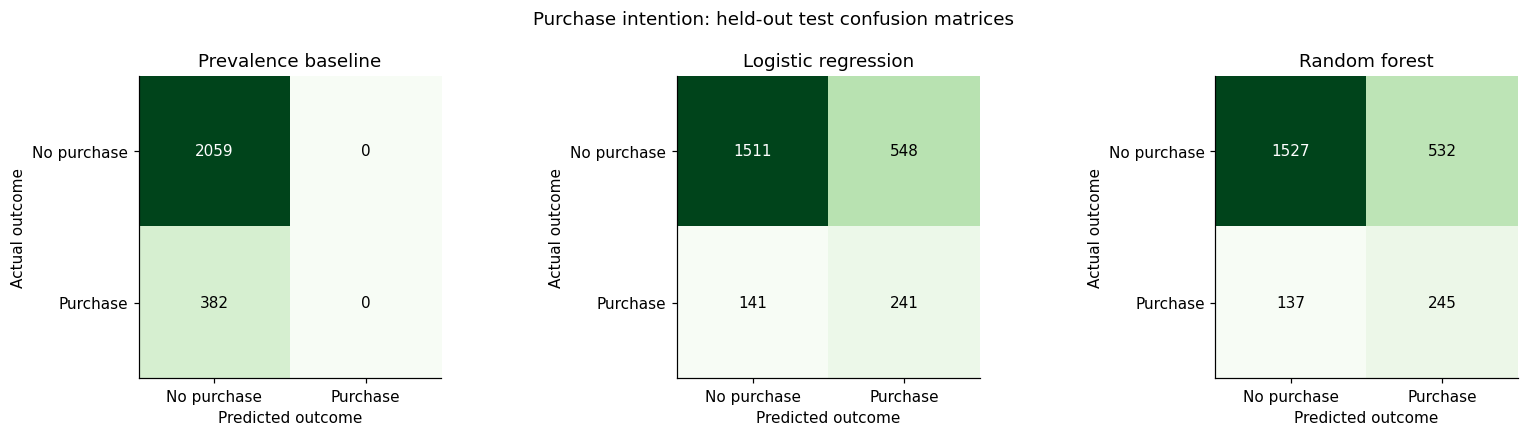

In [7]:
p = legacy_results["purchase"]
print("Split:", p["split"], "| selected:", p["selected"], "| threshold:", p["threshold"])
display(pd.DataFrame(p["validation"]))
classification_table = pd.DataFrame(p["test"]).drop(columns=["confusionMatrix", "rocCurve", "prCurve"])
display(classification_table)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, model in zip(axes, p["test"]):
    cm = np.array(model["confusionMatrix"])
    ax.imshow(cm, cmap="Greens")
    for (i,j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center", color="white" if value>cm.max()/2 else "black")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["No purchase", "Purchase"],
           yticklabels=["No purchase", "Purchase"], xlabel="Predicted outcome", ylabel="Actual outcome", title=model["model"])
fig.suptitle("Purchase intention: held-out test confusion matrices")
plt.tight_layout(); plt.show()

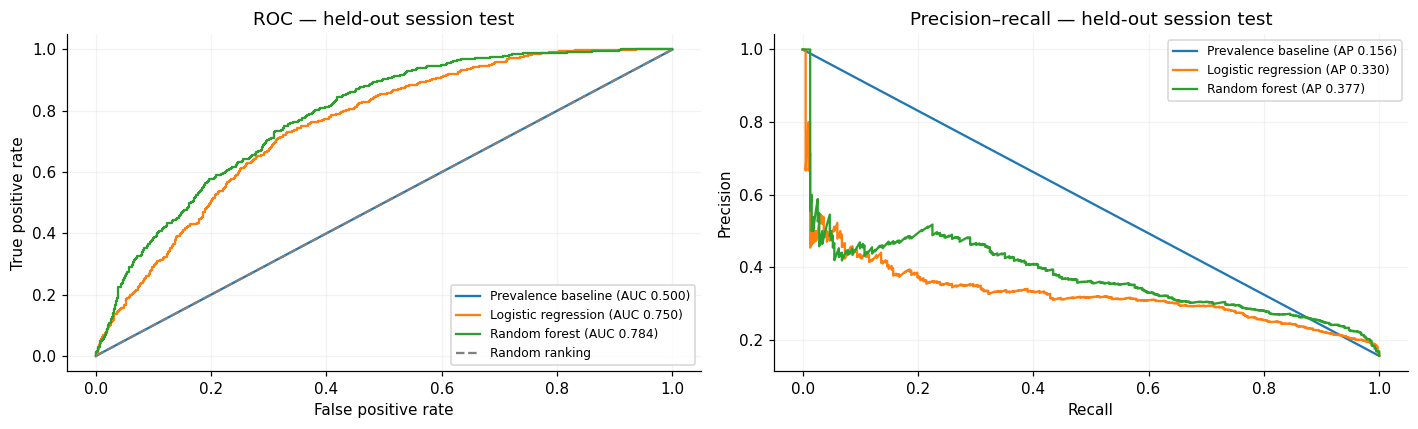

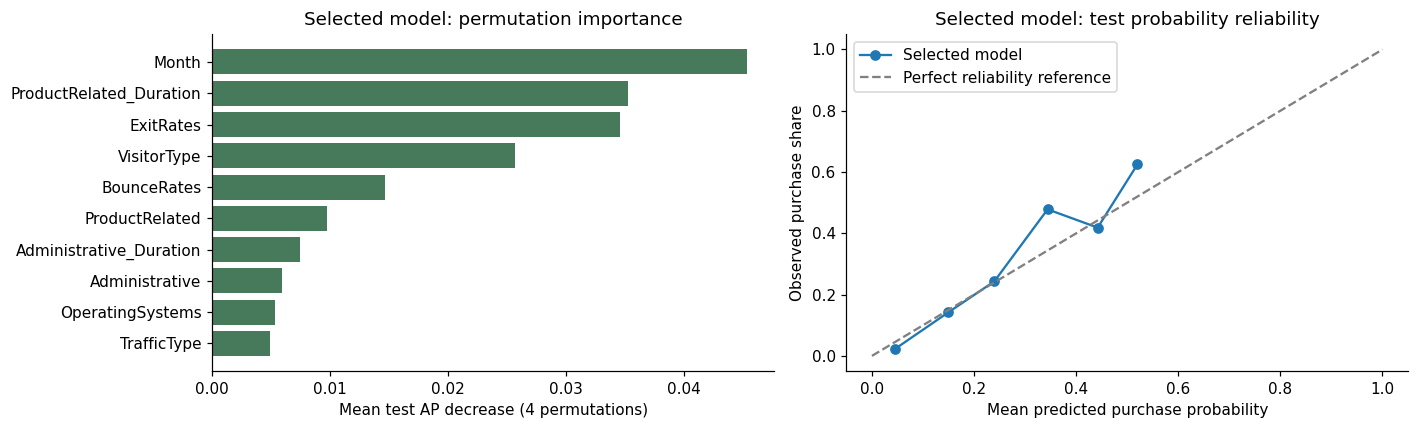

Session-complete benchmark, not a real-time or causal conversion promise. No timestamps for temporal validation. Random split cannot measure future-period drift. Browser simulator uses evaluated logistic regression, even if random forest wins.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model in p["test"]:
    axes[0].plot(model["rocCurve"]["fpr"], model["rocCurve"]["tpr"], label=model["model"] + f" (AUC {model['rocAUC']:.3f})")
    axes[1].plot(model["prCurve"]["recall"], model["prCurve"]["precision"], label=model["model"] + f" (AP {model['averagePrecision']:.3f})")
axes[0].plot([0,1],[0,1],"--",color="grey",label="Random ranking")
axes[0].set(title="ROC — held-out session test", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision–recall — held-out session test", xlabel="Recall", ylabel="Precision")
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=.15)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(13,4))
importance = pd.DataFrame(p["importance"]).head(10).sort_values("averagePrecisionDrop")
axes[0].barh(importance.feature, importance.averagePrecisionDrop, color="#47795b")
axes[0].set(title="Selected model: permutation importance", xlabel="Mean test AP decrease (4 permutations)")
cal = pd.DataFrame(p["calibration"])
axes[1].plot(cal.predicted,cal.observed,"o-",label="Selected model")
axes[1].plot([0,1],[0,1],"--",color="grey",label="Perfect reliability reference")
axes[1].set(title="Selected model: test probability reliability",xlabel="Mean predicted purchase probability",ylabel="Observed purchase share")
axes[1].legend();plt.tight_layout();plt.show()
print(p["limitation"])

## 7. RFM and wholesale clustering — model selection, profiles and PCA

Group numbers are arbitrary identifiers. Silhouette is not percentage accuracy. PCA shows a projection rather than a separate predictive model.

### Retail RFM

Selected k: 2 | cross-seed ARI: 0.9945509598940148


,k,silhouette,daviesBouldin
0,2,0.435912,0.873145
1,3,0.344422,1.036628
2,4,0.364734,0.940537
3,5,0.342294,0.958051
4,6,0.334980,0.960213


,cluster,Recency,Frequency,Monetary,customers
0,0,298.49,2.10,613.08,3566
1,1,50.30,12.75,6569.45,2312


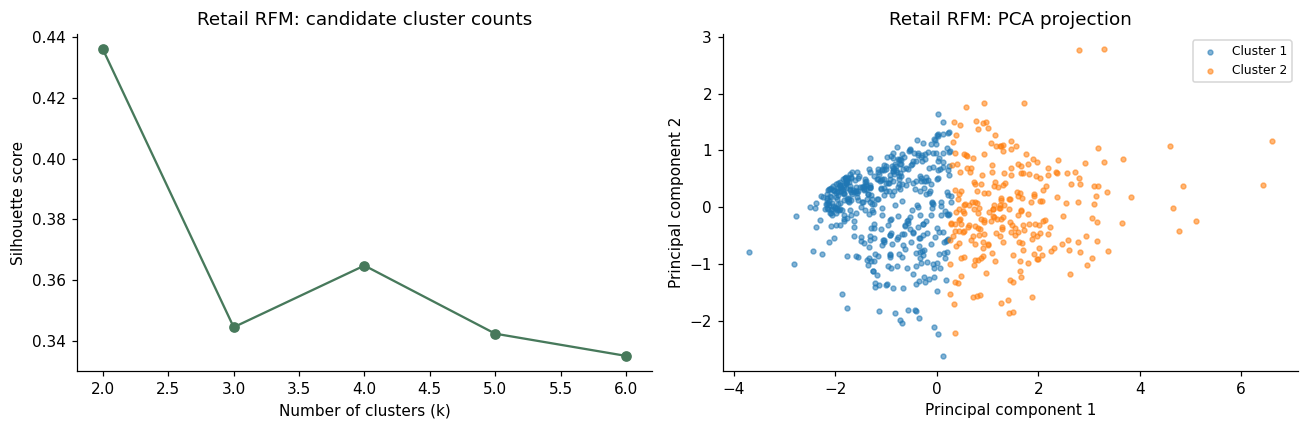

PCA variance fractions: [0.7638805358596282, 0.18714735735556132]
Internal descriptive validation on the same population; no ground-truth segments or evidence of campaign uplift.


### Wholesale spending

Selected k: 2 | cross-seed ARI: 1.0


,k,silhouette,daviesBouldin
0,2,0.290328,1.351502
1,3,0.259416,1.340563
2,4,0.188495,1.540772
3,5,0.191585,1.484279
4,6,0.200887,1.432346


,cluster,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,customers
0,0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04,252
1,1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43,188


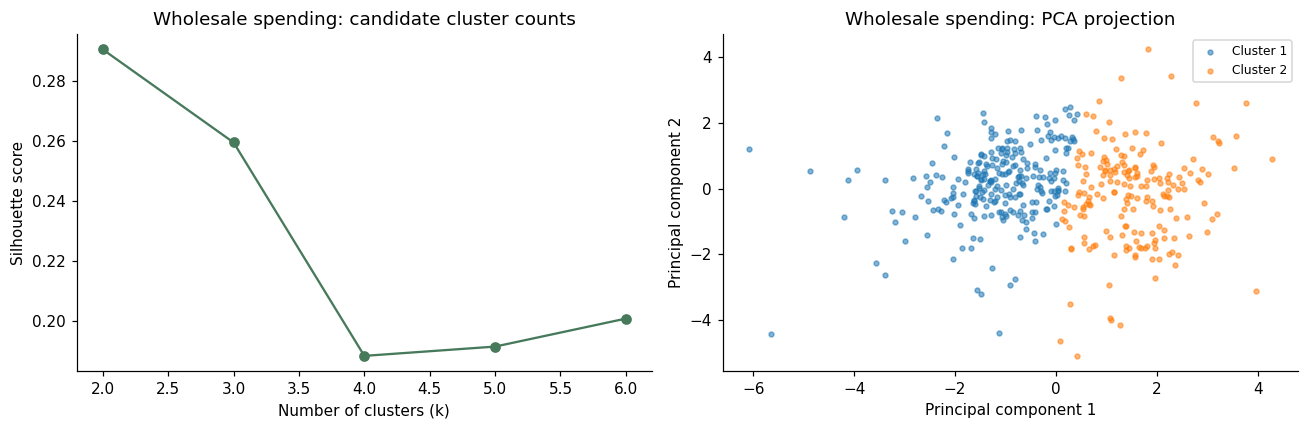

PCA variance fractions: [0.4407775178570069, 0.27194917148586895]
Internal descriptive validation on the same population; no ground-truth segments or evidence of campaign uplift.


In [9]:
for name, section in [("Retail RFM", legacy_results["segments"]), ("Wholesale spending", legacy_results["wholesale"])]:
    display(Markdown("### " + name))
    print("Selected k:", section["selectedK"], "| cross-seed ARI:", section["stabilityARI"])
    display(pd.DataFrame(section["candidates"]))
    display(pd.DataFrame(section["profiles"]))
    candidates = pd.DataFrame(section["candidates"])
    points = pd.DataFrame(section["points"])
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    axes[0].plot(candidates.k,candidates.silhouette,"o-",color="#47795b")
    axes[0].set(title=name+": candidate cluster counts",xlabel="Number of clusters (k)",ylabel="Silhouette score")
    for label, group in points.groupby("cluster"):
        axes[1].scatter(group.x,group.y,s=10,alpha=.55,label=f"Cluster {label+1}")
    axes[1].set(title=name+": PCA projection",xlabel="Principal component 1",ylabel="Principal component 2")
    axes[1].legend(fontsize=8)
    plt.tight_layout();plt.show()
    print("PCA variance fractions:", section["pcaExplainedVariance"])
    print(section["limitation"])

## 8. Basket rules and retention

Exact two-itemset counting produces support, confidence and lift; it is not a causal cross-sell uplift test. Cohorts are left-censored; blank future cells are unobserved periods, not zero retention. The 90-day inactivity flag is a rule, not a supervised churn model.

,antecedent,consequent,support,confidence,lift,baskets
0,HERB MARKER CHIVES,HERB MARKER PARSLEY,0.005090,0.927273,149.246221,204
1,HERB MARKER PARSLEY,HERB MARKER CHIVES,0.005090,0.819277,149.246221,204
2,HERB MARKER THYME,HERB MARKER ROSEMARY,0.005789,0.931727,148.177854,232
3,HERB MARKER ROSEMARY,HERB MARKER THYME,0.005789,0.920635,148.177854,232
4,HERB MARKER THYME,HERB MARKER PARSLEY,0.005589,0.899598,144.791987,224
...,...,...,...,...,...,...
75,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BATHROOM,0.008783,0.624113,62.220387,352
76,SET OF 6 TEA TIME BAKING CASES,SET OF 6 SNACK LOAF BAKING CASES,0.005165,0.547619,61.996973,207
77,SET OF 6 SNACK LOAF BAKING CASES,SET OF 6 TEA TIME BAKING CASES,0.005165,0.584746,61.996973,207
78,SET OF 3 WOODEN HEART DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.005440,0.489888,61.546166,218


Exact frequent 2-itemset counting across invoice baskets. Binary presence per invoice. Minimum support 0.5% (at least 20 invoices), confidence >=20%, lift >1. Rules ranked by lift; top 80 published.
Descriptive co-occurrence on full history. No held-out cross-sell uplift, multi-item antecedents, or causal recommendation claims.


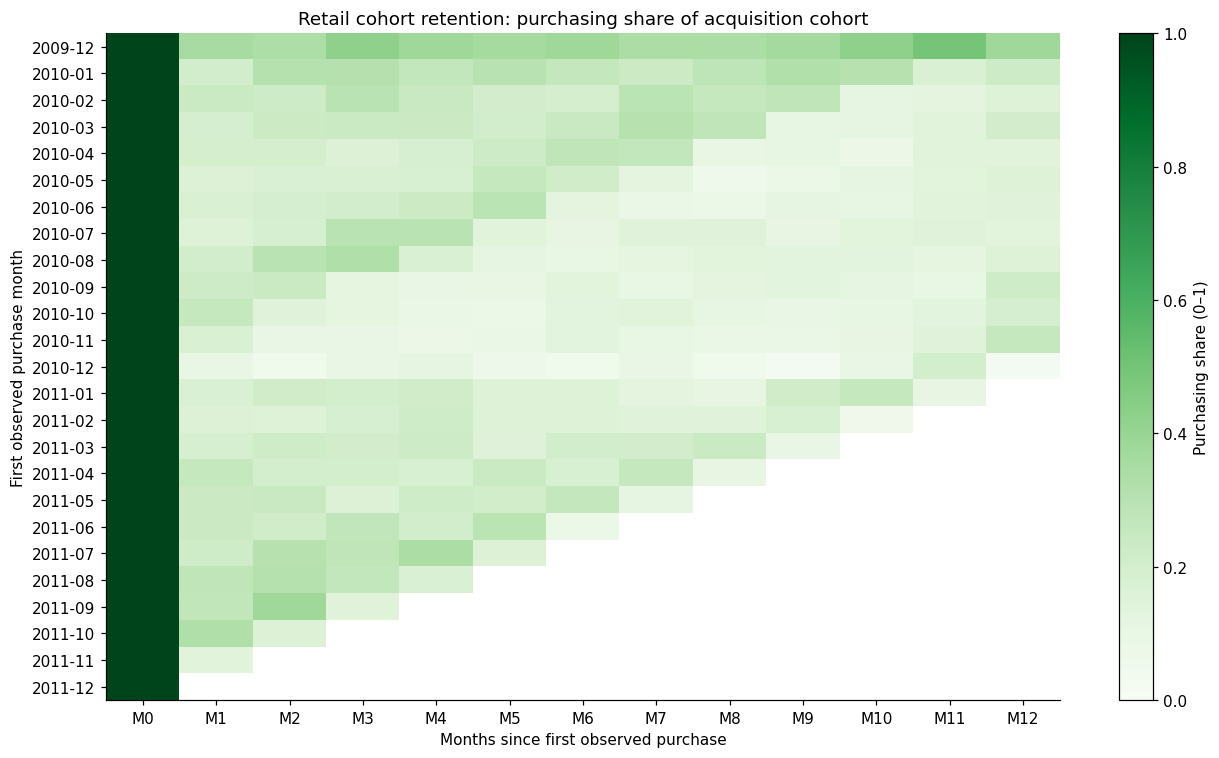

In [10]:
display(pd.DataFrame(legacy_results["basket"]["rules"]))
print(legacy_results["basket"]["method"])
print(legacy_results["basket"]["limitation"])
cohorts = legacy_results["cohorts"]
cohort_matrix = pd.DataFrame([c["retention"] for c in cohorts], index=[c["cohort"] for c in cohorts])
fig, ax = plt.subplots(figsize=(12,7))
im=ax.imshow(cohort_matrix.to_numpy(dtype=float),aspect="auto",vmin=0,vmax=1,cmap="Greens")
ax.set(yticks=range(len(cohorts)),yticklabels=cohort_matrix.index,
       xticks=range(cohort_matrix.shape[1]),xticklabels=[f"M{i}" for i in range(cohort_matrix.shape[1])],
       title="Retail cohort retention: purchasing share of acquisition cohort",xlabel="Months since first observed purchase",ylabel="First observed purchase month")
fig.colorbar(im,ax=ax,label="Purchasing share (0–1)")
plt.tight_layout();plt.show()

## 9. Version 1 aggregate revenue forecasting baselines

These are overall GBP sales baselines, not product-country unit forecasts. Validation chooses between them; the final fold is held out. Aggregate backtest figures include validation windows and are labeled accordingly.

,model,mae,rmse,wape,final_test_mae
0,Last week,15604.581768,23326.206260,0.381140,15169.099643
1,Weekday mean (8 weeks),13571.686386,22997.861159,0.331487,16404.368464


Last week


,trainEnd,testStart,testEnd,mae
0,2011-08-19,2011-08-20,2011-09-16,14847.028929
1,2011-09-16,2011-09-17,2011-10-14,18010.222429
2,2011-10-14,2011-10-15,2011-11-11,14391.976071
3,2011-11-11,2011-11-12,2011-12-09,15169.099643


Weekday mean (8 weeks)


,trainEnd,testStart,testEnd,mae
0,2011-08-19,2011-08-20,2011-09-16,9619.546964
1,2011-09-16,2011-09-17,2011-10-14,15465.325946
2,2011-10-14,2011-10-15,2011-11-11,12797.504170
3,2011-11-11,2011-11-12,2011-12-09,16404.368464


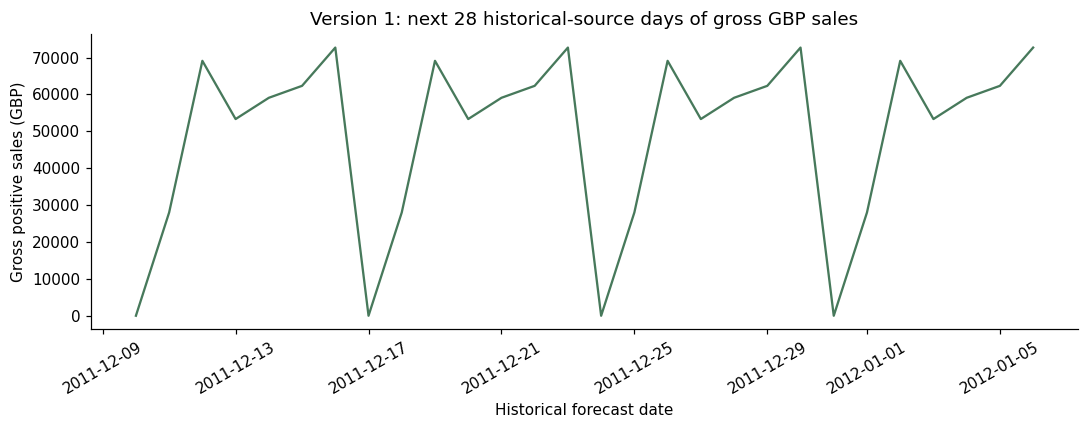

Four expanding-window 28-day origins. First three origins select by MAE; fourth is the reused chronological test benchmark, previously inspected during development. Aggregate metrics include all four and are labeled backtest metrics. Final forecast refits the selected rule on all history.
Historical gross-sales planning baseline; the final source day may be partial. Zero-filled dates assume no recorded sales. No causal, promotion, holiday, or prediction-interval model. Forecast follows the historical dataset, not today.


In [11]:
old_forecast = legacy_results["forecast"]
display(pd.DataFrame([{**{k:v for k,v in m.items() if k!="folds"}, "final_test_mae":m["folds"][-1]["mae"]} for m in old_forecast["metrics"]]))
for model in old_forecast["metrics"]:
    print(model["model"]);display(pd.DataFrame(model["folds"]))
future = pd.DataFrame(old_forecast["future"])
plt.plot(pd.to_datetime(future.date),future.revenue,color="#47795b")
plt.title("Version 1: next 28 historical-source days of gross GBP sales")
plt.xlabel("Historical forecast date");plt.ylabel("Gross positive sales (GBP)")
plt.xticks(rotation=30);plt.tight_layout();plt.show()
print(old_forecast["protocol"])
print(old_forecast["limitation"])

## 10. Full implementation: current product–market models

The following cell defines the complete current pipeline: merchandise cleaning, canonical identity, daily product-country matrices, three deterministic forecasting baselines, log-unit/Poisson gradient boosting, calibration, forward-only evaluation, type-guarded TF–IDF/price analogue matching, and withheld catalogue-entry cohorts.

**Demand protocol:** training labels finish before validation; two 28-day validation windows select the challenger by absolute unit error; one calibration window fits an empirical residual band. The later reused historical test is a diagnostic, not an untouched external test. A disclosed deployment guard retains the incumbent if the challenger worsens known-benchmark WAPE or RMSE. Seasonal stress runs select from their own past validation windows. No universal “accuracy” is calculated from WAPE.

**Country protocol:** three historical cohorts select neighbour count; a fourth is the final test. Each target is new to the recorded catalogue, and its sales outcomes are absent from analogue training. Prelaunch availability of the description/price is assumed. A first recorded sale is not proof of a true launch, and never-sold products are absent.

In [12]:
"""Build merchandise-only decision artifacts and forward-only benchmarks.

No outcomes from an unseen product are used in its analogue prediction.
The analogue benchmark is retrospective, not evidence of launch causality.
"""
import argparse, hashlib, json
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

NON_PRODUCTS={'ADJUST','ADJUST2','AMAZONFEE','B','BANK CHARGES','C2','CRUK','D','DOT','M','PADS','POST','S','TEST001','TEST002'}
STOP='a an the and or of for with in on to from by at is it this that set pack assorted'.split()
TYPES=[['mug','mugs','cup','cups'],['bag','bags','tote','totes'],['plate','plates','platter'],['bowl','bowls'],['bottle','bottles'],['candle','candles','tealight','tealights'],['cushion','cushions','pillow'],['necklace','necklaces'],['clock','clocks'],['box','boxes','tin','tins'],['card','cards'],['notebook','notebooks','journal'],['holder','holders'],['vase','vases'],['basket','baskets'],['lamp','lamps'],['toy','toys'],['ornament','ornaments']]
HORIZON=28

def safe(x):
    if isinstance(x,dict): return {str(k):safe(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)): return [safe(v) for v in x]
    if isinstance(x,np.ndarray): return safe(x.tolist())
    if isinstance(x,np.generic): return safe(x.item())
    if isinstance(x,float) and not np.isfinite(x): return None
    return x

def feature_matrix(units,origin,prices,first,orders=None,rich=False):
    last28=units[:,origin-28:origin].sum(1)
    prev28=units[:,origin-56:origin-28].sum(1)
    last84=units[:,origin-84:origin].sum(1)
    recent7=units[:,origin-7:origin].sum(1)
    active=(units[:,origin-84:origin]>0).sum(1)
    base=np.column_stack([np.log1p(last28),np.log1p(prev28),np.log1p(last84),np.log1p(recent7),active,np.maximum(0,origin-first),np.log1p(prices),np.full(len(prices),(origin%365)/365)])
    if not rich: return base
    history=units[:,origin-84:origin]; last_sale=np.where((history>0).any(1),np.argmax((history>0)[:,::-1],axis=1),84)
    # All aggregates end strictly before the prediction origin, including annual lag.
    annual=units[:,origin-365:origin-337].sum(1) if origin>=365 else np.zeros(len(prices))
    recent_orders=orders[:,origin-28:origin].sum(1); old_orders=orders[:,origin-84:origin-28].sum(1)
    seasonal=2*np.pi*origin/365.25
    return np.column_stack([base,np.log1p(units[:,origin-84:origin-56].sum(1)),np.log1p(history.max(1)),np.log1p(history.std(1)),last_sale,
        np.log((last28+1)/(prev28+1)),np.log1p(recent_orders),np.log1p(old_orders),np.log1p(last28/(recent_orders+1)),np.log1p(annual),
        np.full(len(prices),origin>=365),np.full(len(prices),np.sin(seasonal)),np.full(len(prices),np.cos(seasonal))])

def baseline_predictions(u,o):
    a=u[:,o-28:o].sum(1); b=u[:,o-56:o-28].sum(1)
    return {'Last 28 days':a,'84-day daily mean':u[:,o-84:o].sum(1)/3,'Damped trend':a*np.clip(np.sqrt((a+1)/(b+1)),.5,1.5)}

def metrics(actual,pred):
    error=np.abs(actual-pred)
    return {'mae':float(error.mean()),'wape':float(error.sum()/actual.sum()) if actual.sum()>0 else None,'rmse':float(np.sqrt(((actual-pred)**2).mean())),'rows':len(actual)}

def demand_benchmark(units,orders,prices,countries=None,stress=True):
    n,days=units.shape; first=np.argmax(units>0,axis=1); evaluation=list(range(days-112,days,28))
    train_origins=list(range(112,evaluation[0]-27,28)); xx=[]; yy=[]; rich_x=[]
    def eligible(o): return (first<=o-84)&(orders[:,o-84:o].sum(1)>=10)
    for o in train_origins:
        mask=eligible(o); xx.append(feature_matrix(units,o,prices,first)[mask]); rich_x.append(feature_matrix(units,o,prices,first,orders,True)[mask]); yy.append(units[mask,o:o+28].sum(1))
    x=np.concatenate(xx); y=np.concatenate(yy); xr=np.concatenate(rich_x)
    models={
        'Gradient boosting (log units)':HistGradientBoostingRegressor(max_iter=160,max_leaf_nodes=15,l2_regularization=5,random_state=42),
        'Gradient boosting (Poisson)':HistGradientBoostingRegressor(loss='poisson',max_iter=160,max_leaf_nodes=15,l2_regularization=10,random_state=42),
        'History boosting (absolute error)':HistGradientBoostingRegressor(loss='absolute_error',max_iter=240,max_leaf_nodes=15,l2_regularization=10,random_state=42),
        'History boosting (log units)':HistGradientBoostingRegressor(max_iter=240,max_leaf_nodes=15,l2_regularization=10,random_state=42),
        'History boosting (Poisson)':HistGradientBoostingRegressor(loss='poisson',max_iter=240,max_leaf_nodes=15,l2_regularization=20,random_state=42),
        'History extra trees':ExtraTreesRegressor(n_estimators=160,min_samples_leaf=8,max_features=.8,n_jobs=2,random_state=42)}
    for name,model in models.items(): model.fit(xr if name.startswith('History') else x,np.log1p(y) if 'log units' in name else y)
    results={name:[] for name in list(baseline_predictions(units,evaluation[0]))+list(models)}; folds=[]
    for o in evaluation:
        mask=eligible(o); actual=units[mask,o:o+28].sum(1); pred=baseline_predictions(units,o)
        for name,model in models.items():
            values=model.predict(feature_matrix(units,o,prices,first,orders,name.startswith('History'))); pred[name]=np.maximum(0,np.expm1(values) if 'log units' in name else values)
        for name in results: results[name].append((actual,pred[name][mask]))
        folds.append({'originIndex':o,'rows':int(mask.sum()),'role':['validation','validation','calibration','test'][len(folds)]})
    validation_winner=min(results,key=lambda name:sum(np.abs(a-p).sum() for a,p in results[name][:2]))
    selected=validation_winner
    release={'incumbent':'Gradient boosting (log units)','promoted':False,'reason':'Seasonal stress run: selection uses its earlier validation windows only.'}
    if stress:
        # This is a release regression guard on an already inspected benchmark,
        # explicitly NOT a claim that deployment selection has an untouched test.
        challenger=metrics(*results[validation_winner][-1]); incumbent=metrics(*results[release['incumbent']][-1])
        passed=challenger['wape']<=incumbent['wape'] and challenger['rmse']<=incumbent['rmse']
        if not passed: selected=release['incumbent']
        release.update(promoted=bool(passed and selected!=release['incumbent']),reason='Validation winner promoted only if reused benchmark WAPE and RMSE do not regress against incumbent. Challenger failed; incumbent retained.' if not passed else 'Validation winner passes reused-benchmark non-regression guard. Independent future validation is still required.')
    cal_a,cal_p=results[selected][2]; residual=(cal_a-cal_p)/(cal_p+1)
    qlo,qhi=np.quantile(residual,[.1,.9]); test_a,test_p=results[selected][3]
    low=np.maximum(0,test_p+qlo*(test_p+1)); high=np.maximum(0,test_p+qhi*(test_p+1))
    final=baseline_predictions(units,days)
    for name,m in models.items():
        v=m.predict(feature_matrix(units,days,prices,first,orders,name.startswith('History'))); final[name]=np.maximum(0,np.expm1(v) if 'log units' in name else v)
    forecast=final[selected]; supported=eligible(days)
    summary=[]
    for name in results:
        va=np.concatenate([r[0] for r in results[name][:2]]); vp=np.concatenate([r[1] for r in results[name][:2]])
        summary.append({'model':name,'validation':metrics(va,vp),'test':metrics(*results[name][3])})
    o=evaluation[-1]; mask=eligible(o); recent=units[mask,o-28:o].sum(1); activity=(units[mask,o-84:o]>0).sum(1)
    baseline=results['Last 28 days'][-1][1]; cases=[]
    slices=[('No subsequent sales',test_a==0),('Subsequent positive sales',test_a>0),('Low recent volume (≤50 units)',recent<=50),('Medium recent volume (51–250)',(recent>50)&(recent<=250)),('High recent volume (>250)',recent>250),('Intermittent (≤12 active days / 84)',activity<=12),('Frequent (>12 active days / 84)',activity>12)]
    if countries is not None:
        uk=np.asarray(countries)[mask]=='United Kingdom'; slices.extend([('United Kingdom',uk),('Other recorded countries',~uk)])
    for label,subset in slices:
        if subset.any(): cases.append({'case':label,'selected':metrics(test_a[subset],test_p[subset]),'baseline':metrics(test_a[subset],baseline[subset]),'bandCoverage':float(((test_a[subset]>=low[subset])&(test_a[subset]<=high[subset])).mean())})
    window_metrics=[{'role':f['role'],'originIndex':f['originIndex'],'selected':metrics(*results[selected][i]),'baseline':metrics(*results['Last 28 days'][i])} for i,f in enumerate(folds)]
    temporal=[]
    if stress:
        for end in [days-168,days-112,days-56]:
            audit,*_=demand_benchmark(units[:,:end],orders[:,:end],prices,countries,False)
            winner=next(r for r in audit['candidates'] if r['model']==audit['selected'])
            base=next(r for r in audit['candidates'] if r['model']=='Last 28 days')
            temporal.append({'endIndex':end-1,'selectedModel':audit['selected'],'selected':winner['test'],'baseline':base['test'],'bandCoverage':audit['coverage'],'trainLatestLabelIndex':audit['trainLatestLabelIndex'],'testOriginIndex':audit['folds'][-1]['originIndex']})
    return {'selected':selected,'validationWinner':validation_winner,'releaseDecision':release,'candidates':summary,'folds':folds,'cases':cases,'windowMetrics':window_metrics,'temporalStress':temporal,'trainRows':len(y),'trainLatestLabelIndex':train_origins[-1]+27,'coverage':float(((test_a>=low)&(test_a<=high)).mean()),'intervalNominal':.8,'calibrationRows':len(cal_a),'testPoints':[{'actual':float(a),'predicted':float(p)} for a,p in zip(test_a[:200],test_p[:200])],
        'protocol':'Nine fixed candidates. Two chronological 28-day validation windows select the challenger by total absolute unit error. Third window calibrates a pooled residual band. Fourth is a REUSED historical test benchmark, previously inspected during project development; it is not an untouched external test. A separate deployment regression guard retains the incumbent if challenger benchmark WAPE or RMSE worsens. This release decision uses inspected benchmark results and is not pure validation-only selection. Training labels finish before validation. Eligibility: ≥84 days history and ≥10 preceding-84-day orders. Rich features add lagged orders, inter-sale gaps, volatility, trend and annual sales. All inputs end before origin.',
        'limitation':'One retailer, recorded sales rather than unconstrained demand; stockouts, distribution and promotions are unknown. Residual bands are pooled empirical bands, not guaranteed future coverage.'},forecast,np.maximum(0,forecast+qlo*(forecast+1)),np.maximum(0,forecast+qhi*(forecast+1)),supported

def analogues(vectorizer,matrix,descriptions,prices,target_desc,target_price,k=8,exclude=None):
    query=vectorizer.transform([target_desc]); cosine=(matrix@query.T).toarray().ravel()
    score=cosine*np.exp(-np.abs(np.log(np.maximum(prices,.01)/max(target_price,.01))))
    import re
    tokens=set(re.findall(r'\b[a-z0-9]{2,}\b',target_desc.lower()))
    families=[set(group) for group in TYPES if tokens.intersection(group)]
    if families:
        for i,desc in enumerate(descriptions):
            other=set(re.findall(r'\b[a-z0-9]{2,}\b',str(desc).lower()))
            if not any(other.intersection(group) for group in families): score[i]=0
    if exclude is not None: score[exclude]=0
    ix=np.argsort(-score)[:k]; ix=ix[(cosine[ix]>=.15)&(score[ix]>.05)]
    return ix,score[ix],cosine[ix]

def cold_start_benchmark(sales,dates):
    # First appearance is not proof of a true launch; absent/failed products are missing.
    origins=[pd.Timestamp('2010-06-01'),pd.Timestamp('2010-10-01'),pd.Timestamp('2011-03-01'),pd.Timestamp('2011-07-01')]
    first=sales.groupby('StockCode').InvoiceDate.min(); candidate_results={k:[] for k in [5,8,12]}; baseline_results=[]; folds=[]
    for fold,o in enumerate(origins):
        before=sales[sales.InvoiceDate<o]; recent=before[before.InvoiceDate>=o-pd.Timedelta(days=84)]
        counts=recent.groupby('StockCode').Invoice.nunique(); ids=counts[counts>=10].index
        ids=ids[first.reindex(ids)<=o-pd.Timedelta(days=84)]
        meta=before[before.StockCode.isin(ids)].sort_values('InvoiceDate').groupby('StockCode').agg(Description=('Description','last'),price=('Price','median'))
        ids=meta.index.tolist(); desc=meta.Description.fillna('').astype(str).tolist(); prices=meta.price.to_numpy()
        if len(ids)<20: continue
        vec=TfidfVectorizer(stop_words=STOP,token_pattern=r'(?u)\b[a-z0-9]{2,}\b',lowercase=True); matrix=vec.fit_transform(desc)
        eligible_recent=recent[recent.StockCode.isin(ids)]
        country=eligible_recent.groupby(['StockCode','Country']).Quantity.sum().unstack(fill_value=0).reindex(ids,fill_value=0)/3
        country_orders=eligible_recent.groupby(['StockCode','Country']).Invoice.nunique().unstack(fill_value=0).reindex(index=ids,columns=country.columns,fill_value=0)
        globals_=recent.groupby('Country').Quantity.sum().sort_values(ascending=False); baseline_country=globals_.index[0]
        target_ids=first[(first>=o)&(first<o+pd.Timedelta(days=28))].index
        tests=sales[sales.StockCode.isin(target_ids)&(sales.InvoiceDate<o+pd.Timedelta(days=56))].sort_values('InvoiceDate')
        fold_count=0
        for code,group in tests.groupby('StockCode',sort=True):
            group=group[group.InvoiceDate<group.InvoiceDate.min()+pd.Timedelta(days=28)]
            row=group.iloc[0]; actual=group.groupby('Country').Quantity.sum(); actual_best=actual.idxmax(); target_price=float(row.Price)
            base_units=float(country.sum(axis=1).median()); base_actual=float(actual.sum())
            baseline_results.append({'fold':fold,'hit':int(baseline_country==actual_best),'error':abs(base_actual-base_units),'actual':base_actual})
            for k in candidate_results:
                ix,weights,_=analogues(vec,matrix,desc,prices,str(row.Description),target_price,k)
                if len(ix)<3: candidate_results[k].append({'fold':fold,'supported':False,'actual':base_actual}); continue
                rates=country.iloc[ix].to_numpy(); recent_orders=country_orders.iloc[ix].to_numpy(); active=recent_orders>0
                eligible=(active.sum(axis=0)>=3)&(recent_orders.sum(axis=0)>=10)
                if not eligible.any(): candidate_results[k].append({'fold':fold,'supported':False,'actual':base_actual}); continue
                weighted=(rates*weights[:,None]).sum(axis=0)/np.maximum((active*weights[:,None]).sum(axis=0),1e-12)
                weighted[~eligible]=0
                best=country.columns[int(np.argmax(weighted))]; total=float(weighted.sum())
                candidate_results[k].append({'fold':fold,'supported':True,'hit':int(best==actual_best),'error':abs(base_actual-total),'actual':base_actual,'baselineHit':int(baseline_country==actual_best),'baselineError':abs(base_actual-base_units),'code':str(code)})
            fold_count+=1
        folds.append({'cutoff':str(o.date()),'lastHistoryDate':str(before.InvoiceDate.max().date()),'role':'test' if fold==3 else 'validation','newProducts':fold_count})
    # Select coverage-aware country hit rate on validation, never the last fold.
    def objective(rows):
        rows=[r for r in rows if r['fold']<3]
        return sum(r.get('hit',0) for r in rows)/max(len(rows),1)
    selected=max(candidate_results,key=lambda k:objective(candidate_results[k])); stats=[]
    for k,rows in candidate_results.items():
        for role in ['validation','test']:
            subset=[r for r in rows if (r['fold']==3)==(role=='test')]; supported=[r for r in subset if r['supported']]
            stats.append({'neighbors':k,'role':role,'total':len(subset),'supported':len(supported),'coverage':len(supported)/max(len(subset),1),'topCountryHitRate':sum(r['hit'] for r in supported)/max(len(supported),1),'baselineHitRate':sum(r['baselineHit'] for r in supported)/max(len(supported),1),'unitMAE':sum(r['error'] for r in supported)/max(len(supported),1),'baselineUnitMAE':sum(r['baselineError'] for r in supported)/max(len(supported),1)})
    selected_test=next(r for r in stats if r['neighbors']==selected and r['role']=='test')
    validated=selected_test['supported']>=20 and selected_test['topCountryHitRate']>selected_test['baselineHitRate']
    return {'selectedNeighbors':selected,'results':stats,'folds':folds,'beatsCountryBaseline':validated,
        'protocol':'Historical catalogue-entry simulation. At each cutoff, compare products first observed in the following 28 days with established products known before cutoff. Use only supplied description and first observed price as query metadata. Outcomes cover the first 28 recorded days per target. Three earlier cohorts select neighbor count; July 2011 cohort is final test. Unit estimates use preceding 84-day rates scaled to 28 days. As in the app, each supported country requires three active analogues and ten orders; average only active analogues. Unit MAE compares the sum over supported countries with target total recorded units.',
        'limitation':'First recorded sale is not a verified launch. Products with no sales never enter this dataset. Metadata must represent what was known before launch. No advertising, availability, distribution, competition or market-size features exist. This is not a launch-success probability or a causal expansion forecast.'}

def build_market_report(root,out):
    require_verified(root,['retail'])
    path=root/'transactions/online_retail_II.xlsx'; print('Reading source workbook for product-market build...',flush=True)
    frame=pd.concat(pd.read_excel(path,sheet_name=None).values(),ignore_index=True); raw=len(frame); duplicates=int(frame.duplicated().sum()); frame=frame.drop_duplicates()
    frame.InvoiceDate=pd.to_datetime(frame.InvoiceDate,errors='coerce'); frame.StockCode=frame.StockCode.astype(str).str.strip(); frame.Description=frame.Description.astype('string').str.strip()
    merch=~frame.StockCode.str.upper().isin(NON_PRODUCTS)&~frame.Description.str.upper().fillna('').str.contains('POSTAGE|DOTCOM|BANK CHARGE|AMAZON FEE|MANUAL|CARRIAGE|ADJUSTMENT',regex=True)
    returns=frame[merch & (frame.Quantity.lt(0)|frame.Invoice.astype(str).str.upper().str.startswith('C')) & frame.Price.gt(0)].copy()
    sales=frame[merch & frame.Quantity.gt(0)&frame.Price.gt(0)&frame.InvoiceDate.notna()&~frame.Invoice.astype(str).str.upper().str.startswith('C')].copy()
    sales['Revenue']=sales.Quantity*sales.Price; sales['date']=sales.InvoiceDate.dt.floor('D'); sales.Country=sales.Country.fillna('Unknown')
    meta=sales.sort_values('InvoiceDate').groupby('StockCode').agg(description=('Description','last'),price=('Price','median'),first=('InvoiceDate','min'),last=('InvoiceDate','max'),units=('Quantity','sum'),revenue=('Revenue','sum'),orders=('Invoice','nunique')).reset_index()
    meta.description=meta.description.fillna('Unnamed product'); products=meta.StockCode.tolist(); product_idx={c:i for i,c in enumerate(products)}
    dates=pd.date_range(sales.date.min(),sales.date.max()); day_idx={v:i for i,v in enumerate(dates)}
    # Initial observed price is available at every eligible historical origin.
    # A full-history median here would leak future price information into training.
    pairs=sales.sort_values('InvoiceDate').groupby(['StockCode','Country']).agg(units=('Quantity','sum'),revenue=('Revenue','sum'),orders=('Invoice','nunique'),customers=('Customer ID','nunique'),price=('Price','first'),first=('date','min')).reset_index()
    pair_keys=list(zip(pairs.StockCode,pairs.Country)); pair_idx={key:i for i,key in enumerate(pair_keys)}
    units=np.zeros((len(pairs),len(dates))); orders=np.zeros_like(units)
    grouped=sales.groupby(['StockCode','Country','date']).agg(units=('Quantity','sum'),orders=('Invoice','nunique'))
    for (code,country,day),r in grouped.iterrows():
        i=pair_idx[(code,country)]; j=day_idx[day]; units[i,j]=r['units']; orders[i,j]=r['orders']
    print(f'Evaluating nine demand candidates across {len(pairs)} product-country series...',flush=True)
    demand,pred,lo,hi,support=demand_benchmark(units,orders,pairs.price.to_numpy(),pairs.Country.to_numpy())
    for case in demand['temporalStress']:
        case['testStart']=str(dates[case['testOriginIndex']].date()); case['testEnd']=str(dates[case['endIndex']].date())
    for f in demand['folds']:
        o=f['originIndex']; f['historyEnd']=str(dates[o-1].date()); f['forecastStart']=str(dates[o].date()); f['forecastEnd']=str(dates[o+27].date())
    print('Evaluating genuinely withheld catalogue-entry products...',flush=True)
    cold=cold_start_benchmark(sales,dates)
    vec=TfidfVectorizer(stop_words=STOP,token_pattern=r'(?u)\b[a-z0-9]{2,}\b',lowercase=True); matrix=vec.fit_transform(meta.description.astype(str))
    vocabulary=vec.vocabulary_; sparse=[]
    for i in range(len(products)):
        row=matrix.getrow(i); sparse.append([[int(j),round(float(v),7)] for j,v in zip(row.indices,row.data)])
    ret=returns.assign(return_units=returns.Quantity.abs()).groupby(['StockCode','Country']).return_units.sum().to_dict()
    monthly=sales.groupby(['StockCode','Country',sales.InvoiceDate.dt.strftime('%Y-%m')]).agg(units=('Quantity','sum'),revenue=('Revenue','sum')).reset_index()
    month_map={}
    for _,r in monthly.iterrows(): month_map.setdefault((r.StockCode,r.Country),[]).append([r.InvoiceDate,round(r.units,2),round(r.revenue,2)])
    entries=[]
    for i,r in pairs.iterrows():
        return_units=float(ret.get((r.StockCode,r.Country),0)); recent=float(units[i,-84:].sum()/3)
        entries.append({'product':product_idx[r.StockCode],'country':r.Country,'units':float(r.units),'revenue':round(r.revenue,2),'orders':int(r.orders),'customers':int(r.customers),'returnRate':return_units/(r.units+return_units),'recent28':round(recent,2),'recentOrders':int(orders[i,-84:].sum()),'forecast':round(float(pred[i]),2) if support[i] else None,'low':round(float(lo[i]),2) if support[i] else None,'high':round(float(hi[i]),2) if support[i] else None,'monthly':month_map.get((r.StockCode,r.Country),[])})
    # Frequent pairs restricted to genuine merchandise; top co-occurrences per product.
    from collections import Counter
    from itertools import combinations
    baskets=sales.groupby('Invoice').StockCode.agg(lambda x:sorted(set(x))); singles=Counter(x for b in baskets for x in b); keep={x for x,n in singles.items() if n>=30}; counts=Counter(pair for b in baskets for pair in combinations([x for x in b if x in keep],2)); associations={}
    for (a,b),count in counts.items():
        if count<20: continue
        for left,right in [(a,b),(b,a)]:
            confidence=count/singles[left]; lift=confidence/(singles[right]/len(baskets))
            if confidence>=.1 and lift>1: associations.setdefault(str(product_idx[left]),[]).append({'product':product_idx[right],'orders':count,'confidence':round(confidence,4),'lift':round(lift,3)})
    associations={k:sorted(v,key=lambda r:-r['orders'])[:6] for k,v in associations.items()}
    parity=[]
    recent_product_orders=sales[sales.date>=dates[-1]-pd.Timedelta(days=83)].groupby('StockCode').Invoice.nunique().reindex(meta.StockCode,fill_value=0).to_numpy()
    exclude_final=((dates[-1]-meta['first']).dt.days.to_numpy()<84)|(recent_product_orders<10)
    for text,price in [('ceramic floral mug',4.5),('red heart bag',2.0)]:
        ix,weights,cos=analogues(vec,matrix,meta.description.tolist(),meta.price.to_numpy(),text,price,cold['selectedNeighbors'],exclude=exclude_final)
        parity.append({'description':text,'price':price,'indices':ix.tolist(),'scores':weights.tolist()})
    report={'version':2,'generatedAt':datetime.now(timezone.utc).isoformat(),'sourceSHA256':hashlib.sha256(path.read_bytes()).hexdigest(),'pipelineSHA256':MARKET_SCRIPT_SHA256,'parityCases':parity,'period':{'start':str(dates[0].date()),'end':str(dates[-1].date()),'forecastStart':str((dates[-1]+pd.Timedelta(days=1)).date()),'forecastEnd':str((dates[-1]+pd.Timedelta(days=28)).date())},'audit':{'rawRows':raw,'duplicatesRemoved':duplicates,'merchandiseSalesRows':len(sales),'excludedNonMerchandiseRows':int((~merch).sum()),'missingCustomerSalesRows':int(sales['Customer ID'].isna().sum()),'merchandiseRevenue':float(sales.Revenue.sum())},
        'products':[{'code':r.StockCode,'description':r.description,'price':round(r.price,4),'orders':int(r.orders),'units':float(r.units),'revenue':round(r.revenue,2),'first':str(r['first'].date()),'last':str(r['last'].date()),'vector':sparse[i]} for i,r in meta.iterrows()],
        'countries':sorted(pairs.Country.unique().tolist()),'markets':entries,'textModel':{'vocabulary':vocabulary,'idf':vec.idf_.tolist(),'stopWords':STOP,'typeFamilies':TYPES,'minCosine':.15,'minScore':.05},'demand':demand,'coldStart':cold,'associations':associations,
        'boundaries':['Historical UK retailer observations, not current global market research.','Unseen countries are not scored. No city, competitor, promotion, inventory or distribution data.','New-product outputs are analogue scenarios under comparable exposure, not promised launch demand.','Revenue scenarios equal estimated units × entered unit price; no elasticity or profit model.','Evidence counts are not statistical confidence. No arbitrary 100-point opportunity score.']}
    out.mkdir(parents=True,exist_ok=True); (out/'market.json').write_text(json.dumps(safe(report),allow_nan=False,separators=(',',':')),encoding='utf8'); print(f'Wrote {out / "market.json"}. Selected demand method: {demand["selected"]}. Analogue country baseline beaten: {cold["beatsCountryBaseline"]}',flush=True)



In [13]:
build_market_report(DATA_ROOT, OUTPUT_ROOT / "current")
current = json.loads((OUTPUT_ROOT / "current" / "market.json").read_text(encoding="utf8"))
print("Built merchandise catalogue:", len(current["products"]), "products /", len(current["markets"]), "product-country pairs")
display(pd.DataFrame(list(current["audit"].items()), columns=["Audit", "Result"]))

Reading source workbook for product-market build...


Evaluating nine demand candidates across 28275 product-country series...


Evaluating genuinely withheld catalogue-entry products...


Wrote D:\AML\SmartRetailing\artifacts\colab-run\current\market.json. Selected demand method: Gradient boosting (log units). Analogue country baseline beaten: False


Built merchandise catalogue: 4886 products / 28275 product-country pairs


,Audit,Result
0,rawRows,1067371.00
1,duplicatesRemoved,34335.00
2,merchandiseSalesRows,1003117.00
3,excludedNonMerchandiseRows,6111.00
4,missingCustomerSalesRows,226715.00
5,merchandiseRevenue,19640692.64


## 11. Current demand forecasting — every candidate and error measure

MAE and RMSE are units per product-country pair per 28 days; WAPE is total absolute error divided by total actual units. A model can improve MAE while worsening RMSE: neither metric should be hidden. Selection is by validation absolute error, not the most flattering final-test score.

Validation winner: History boosting (absolute error) | Deployed: Gradient boosting (log units)
{'incumbent': 'Gradient boosting (log units)', 'promoted': False, 'reason': 'Validation winner promoted only if reused benchmark WAPE and RMSE do not regress against incumbent. Challenger failed; incumbent retained.'}


,model,partition,mae,wape,rmse,rows
0,Last 28 days,validation,108.463618,0.559648,260.167069,3477
1,Last 28 days,test,120.234937,0.455368,286.977572,1975
2,84-day daily mean,validation,104.870290,0.541107,243.531882,3477
3,84-day daily mean,test,131.327257,0.497378,351.280190,1975
4,Damped trend,validation,132.528117,0.683815,328.408697,3477
5,Damped trend,test,142.199183,0.538554,348.248560,1975
6,Gradient boosting (log units),validation,100.237339,0.517202,241.890349,3477
7,Gradient boosting (log units),test,118.327352,0.448143,357.335376,1975
8,Gradient boosting (Poisson),validation,105.585676,0.544798,245.863577,3477
9,Gradient boosting (Poisson),test,132.762515,0.502814,394.655516,1975


,originIndex,rows,role,historyEnd,forecastStart,forecastEnd
0,627,1660,validation,2011-08-19,2011-08-20,2011-09-16
1,655,1817,validation,2011-09-16,2011-09-17,2011-10-14
2,683,1861,calibration,2011-10-14,2011-10-15,2011-11-11
3,711,1975,test,2011-11-11,2011-11-12,2011-12-09


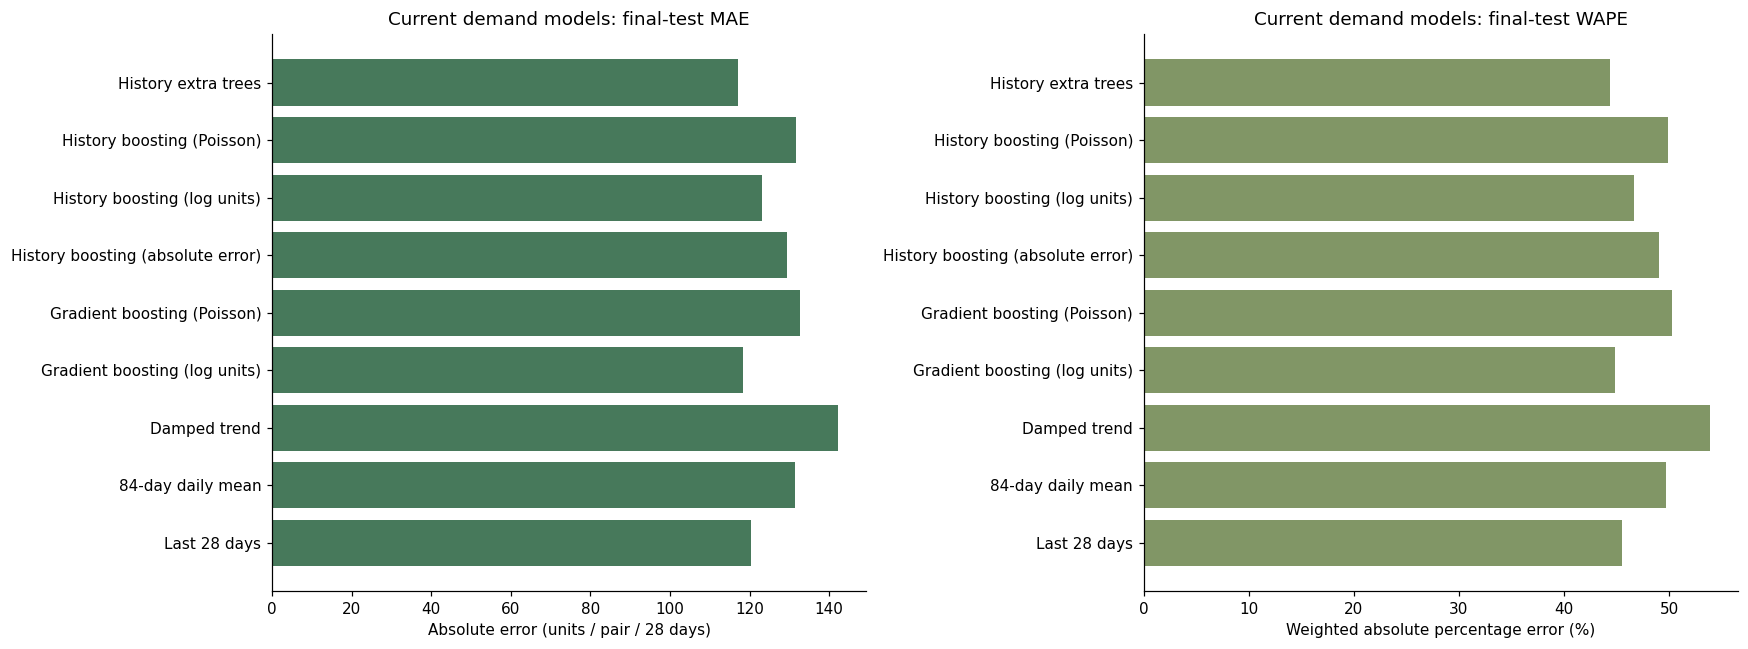

Nine fixed candidates. Two chronological 28-day validation windows select the challenger by total absolute unit error. Third window calibrates a pooled residual band. Fourth is a REUSED historical test benchmark, previously inspected during project development; it is not an untouched external test. A separate deployment regression guard retains the incumbent if challenger benchmark WAPE or RMSE worsens. This release decision uses inspected benchmark results and is not pure validation-only selection. Training labels finish before validation. Eligibility: ≥84 days history and ≥10 preceding-84-day orders. Rich features add lagged orders, inter-sale gaps, volatility, trend and annual sales. All inputs end before origin.


In [14]:
demand = current["demand"]
forecast_rows=[]
for candidate in demand["candidates"]:
    for partition in ["validation","test"]:
        forecast_rows.append({"model":candidate["model"],"partition":partition,**candidate[partition]})
forecast_table=pd.DataFrame(forecast_rows)
print("Validation winner:",demand["validationWinner"],"| Deployed:",demand["selected"])
print(demand["releaseDecision"])
display(forecast_table)
display(pd.DataFrame(demand["folds"]))
fig,axes=plt.subplots(1,2,figsize=(16,6))
test_table=forecast_table[forecast_table.partition=="test"]
axes[0].barh(test_table.model,test_table.mae,color="#47795b")
axes[0].set(title="Current demand models: final-test MAE",xlabel="Absolute error (units / pair / 28 days)")
axes[1].barh(test_table.model,test_table.wape*100,color="#819666")
axes[1].set(title="Current demand models: final-test WAPE",xlabel="Weighted absolute percentage error (%)")
plt.tight_layout();plt.show()
print(demand["protocol"])

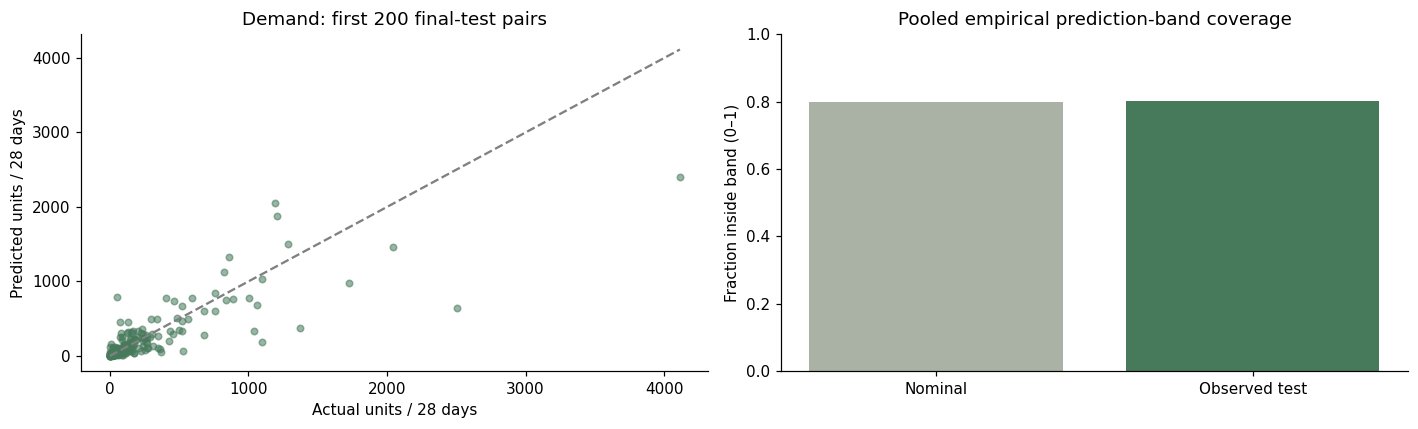

Calibration rows: 1861 | empirical final-test coverage: 0.8020253164556962
One retailer, recorded sales rather than unconstrained demand; stockouts, distribution and promotions are unknown. Residual bands are pooled empirical bands, not guaranteed future coverage.


In [15]:
points=pd.DataFrame(demand["testPoints"])
fig,axes=plt.subplots(1,2,figsize=(13,4))
maximum=max(points.actual.max(),points.predicted.max())
axes[0].scatter(points.actual,points.predicted,alpha=.55,s=18,color="#47795b")
axes[0].plot([0,maximum],[0,maximum],"--",color="grey")
axes[0].set(title="Demand: first 200 final-test pairs",xlabel="Actual units / 28 days",ylabel="Predicted units / 28 days")
axes[1].bar(["Nominal","Observed test"],[demand["intervalNominal"],demand["coverage"]],color=["#a9b2a4","#47795b"])
axes[1].set(ylim=(0,1),title="Pooled empirical prediction-band coverage",ylabel="Fraction inside band (0–1)")
plt.tight_layout();plt.show()
print("Calibration rows:",demand["calibrationRows"],"| empirical final-test coverage:",demand["coverage"])
print(demand["limitation"])

## 12. New-product country and unit benchmarks — results including failure

All neighbour-count comparisons are shown. The country baseline is evaluated on the **same supported test cases**. Abstention coverage is displayed to prevent high accuracy from hiding unsupported queries. The UI permits only pilot comparisons when the country baseline is not beaten. Manual analogue overrides are scenario choices with no independent accuracy claim.

,neighbors,role,total,supported,coverage,topCountryHitRate,baselineHitRate,unitMAE,baselineUnitMAE
0,5,validation,223,199,0.892377,0.889447,0.889447,174.210752,131.546064
1,5,test,28,26,0.928571,0.846154,0.846154,474.649459,610.256410
2,8,validation,223,203,0.910314,0.886700,0.891626,169.895869,130.338259
3,8,test,28,26,0.928571,0.846154,0.846154,434.121235,610.256410
4,12,validation,223,203,0.910314,0.886700,0.891626,165.441973,130.338259
5,12,test,28,27,0.964286,0.777778,0.814815,433.059471,590.111111


,cutoff,lastHistoryDate,role,newProducts
0,2010-06-01,2010-05-30,validation,75
1,2010-10-01,2010-09-30,validation,109
2,2011-03-01,2011-02-28,validation,39
3,2011-07-01,2011-06-30,test,28


Validation-selected neighbours: 8
Country baseline beaten: False


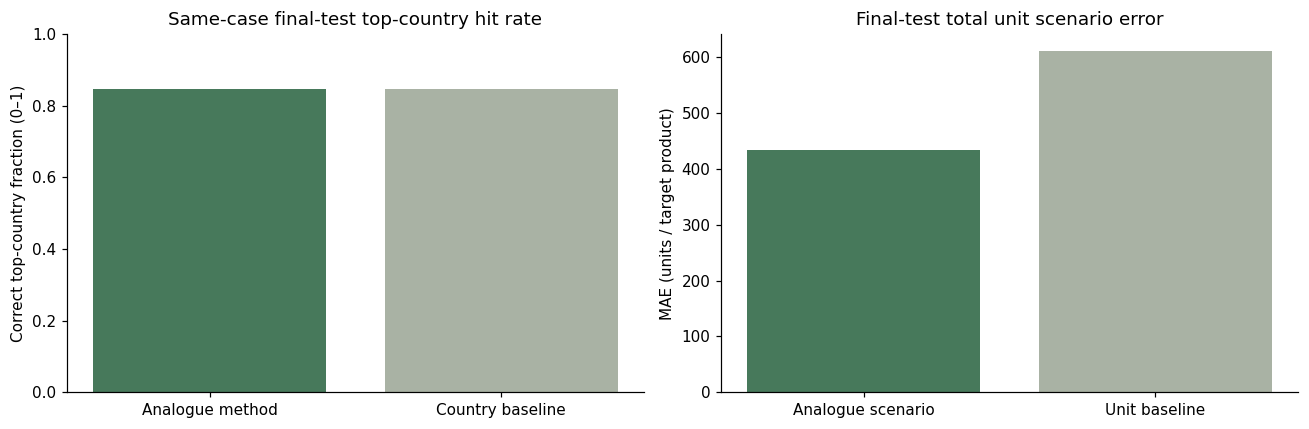

Historical catalogue-entry simulation. At each cutoff, compare products first observed in the following 28 days with established products known before cutoff. Use only supplied description and first observed price as query metadata. Outcomes cover the first 28 recorded days per target. Three earlier cohorts select neighbor count; July 2011 cohort is final test. Unit estimates use preceding 84-day rates scaled to 28 days. As in the app, each supported country requires three active analogues and ten orders; average only active analogues. Unit MAE compares the sum over supported countries with target total recorded units.
First recorded sale is not a verified launch. Products with no sales never enter this dataset. Metadata must represent what was known before launch. No advertising, availability, distribution, competition or market-size features exist. This is not a launch-success probability or a causal expansion forecast.


In [16]:
cold=current["coldStart"]
cold_table=pd.DataFrame(cold["results"])
display(cold_table)
display(pd.DataFrame(cold["folds"]))
selected_cold=cold_table[(cold_table.role=="test")&(cold_table.neighbors==cold["selectedNeighbors"])].iloc[0]
print("Validation-selected neighbours:",cold["selectedNeighbors"])
print("Country baseline beaten:",cold["beatsCountryBaseline"])
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(["Analogue method","Country baseline"],[selected_cold.topCountryHitRate,selected_cold.baselineHitRate],color=["#47795b","#a9b2a4"])
axes[0].set(ylim=(0,1),title="Same-case final-test top-country hit rate",ylabel="Correct top-country fraction (0–1)")
axes[1].bar(["Analogue scenario","Unit baseline"],[selected_cold.unitMAE,selected_cold.baselineUnitMAE],color=["#47795b","#a9b2a4"])
axes[1].set(title="Final-test total unit scenario error",ylabel="MAE (units / target product)")
plt.tight_layout();plt.show()
print(cold["protocol"])
print(cold["limitation"])

## 13. Inspect a new-product scenario yourself

Edit the product description and planned price. These are **scenario inputs**, not an actual company launch claim. Review the proposed comparables and edit `CHOSEN_PRODUCT_CODES` to remove accessories or products that are not substitutes. A recognized product-type guard reduces obvious word-overlap errors, but does not establish semantic or commercial equivalence.

Country scenarios need ≥3 active analogues and ≥10 orders in the trailing 84 days. No unseen country is manufactured. The range is the min/max analogue rate, not a confidence interval. Revenue is units × entered price, with no price elasticity or profit model.

In [17]:
NEW_PRODUCT_DESCRIPTION="ceramic coffee mug"
PLANNED_UNIT_PRICE_GBP=2.50
FEASIBLE_COUNTRIES=None  # None = observed markets; or e.g. ["France","Germany"]
CHOSEN_PRODUCT_CODES=None  # replace with a list after reviewing candidate names
products=current["products"]
text_model=current["textModel"]
def notebook_matches(description,price):
    import re
    tokens=re.findall(r"\b[a-z0-9]{2,}\b",description.lower())
    tokens=[w for w in tokens if w not in text_model["stopWords"] and w in text_model["vocabulary"]]
    from collections import Counter
    query={text_model["vocabulary"][w]:n*text_model["idf"][text_model["vocabulary"][w]] for w,n in Counter(tokens).items()}
    norm=np.sqrt(sum(v*v for v in query.values())) or 1
    query={j:v/norm for j,v in query.items()}
    families=[set(g) for g in text_model["typeFamilies"] if set(tokens).intersection(g)]
    recent_counts=Counter()
    for row in current["markets"]:recent_counts[row["product"]]+=row["recentOrders"]
    cutoff=pd.Timestamp(current["period"]["end"])-pd.Timedelta(days=84)
    found=[]
    for i,product in enumerate(products):
        if pd.Timestamp(product["first"])>cutoff or recent_counts[i]<10:continue
        if product["description"].lower()==description.lower():continue
        words=set(re.findall(r"\b[a-z0-9]{2,}\b",product["description"].lower()))
        if families and not any(words.intersection(g) for g in families):continue
        cosine=sum(query.get(j,0)*v for j,v in product["vector"])
        price_factor=np.exp(-abs(np.log(max(.01,product["price"])/max(.01,price))))
        score=cosine*price_factor
        if cosine>=.15 and score>.05:
            found.append({"index":i,"code":product["code"],"description":product["description"],"referencePrice":product["price"],"textSimilarity":cosine,"priceCloseness":price_factor,"weight":score})
    return sorted(found,key=lambda r:-r["weight"])[:cold["selectedNeighbors"]]
matches=notebook_matches(NEW_PRODUCT_DESCRIPTION,PLANNED_UNIT_PRICE_GBP)
display(pd.DataFrame(matches))
print("Inspect these names. Selection does not establish prospective accuracy.")

,index,code,description,referencePrice,textSimilarity,priceCloseness,weight
0,1526,22304,COFFEE MUG BLUE PAISLEY DESIGN,2.55,0.576824,0.980392,0.565514
1,1525,22303,COFFEE MUG APPLES DESIGN,2.55,0.574388,0.980392,0.563126
2,1524,22302,COFFEE MUG PEARS DESIGN,2.55,0.549113,0.980392,0.538347
3,1523,22301,COFFEE MUG CAT + BIRD DESIGN,2.55,0.533428,0.980392,0.522969
4,1522,22300,COFFEE MUG DOG + BALL DESIGN,2.55,0.514690,0.980392,0.504598
5,2163,22970,LONDON BUS COFFEE MUG,2.55,0.487646,0.980392,0.478084
6,2164,22971,QUEENS GUARD COFFEE MUG,2.55,0.445041,0.980392,0.436314
7,1297,22059,CERAMIC STRAWBERRY DESIGN MUG,1.49,0.535261,0.596000,0.319015


Inspect these names. Selection does not establish prospective accuracy.


In [18]:
chosen=matches if CHOSEN_PRODUCT_CODES is None else [r for r in matches if r["code"] in CHOSEN_PRODUCT_CODES]
scenario_rows=[]
if len(chosen)<3:
    print("INSUFFICIENT EVIDENCE: fewer than three comparable products.")
else:
    lookup={m["index"]:m for m in chosen}
    for country in current["countries"]:
        if FEASIBLE_COUNTRIES is not None and country not in FEASIBLE_COUNTRIES:continue
        if country=="Unknown":continue
        rows=[r for r in current["markets"] if r["country"]==country and r["product"] in lookup and r["recentOrders"]>=1]
        if len(rows)<3 or sum(r["recentOrders"] for r in rows)<10:continue
        weights=np.array([lookup[r["product"]]["weight"] for r in rows])
        rates=np.array([r["recent28"] for r in rows])
        units=float(np.average(rates,weights=weights))
        scenario_rows.append({"country":country,"scenarioUnits28d":units,"revenueAtEnteredPriceGBP":units*PLANNED_UNIT_PRICE_GBP,
            "analogueSpreadLow":float(rates.min()),"analogueSpreadHigh":float(rates.max()),"activeAnalogues":len(rows),"recentOrders":sum(r["recentOrders"] for r in rows)})
scenario_table=pd.DataFrame(scenario_rows)
if len(scenario_table):
    scenario_table=scenario_table.sort_values("scenarioUnits28d",ascending=False)
    display(scenario_table)
    if not cold["beatsCountryBaseline"]:
        print("NO VALIDATED LAUNCH-FIRST WINNER: the automatic country method did not beat its baseline. These are pilot comparisons.")
else:
    print("No eligible country has sufficient active analogue evidence.")
print("Ranges are analogue spreads, not statistical confidence intervals. Scenarios assume comparable distribution and exposure.")

,country,scenarioUnits28d,revenueAtEnteredPriceGBP,analogueSpreadLow,analogueSpreadHigh,activeAnalogues,recentOrders
2,United Kingdom,222.259183,555.647958,116.33,290.67,8,400
0,France,15.520565,38.801412,2.00,23.00,6,29
1,Germany,14.294358,35.735894,10.00,18.00,3,14


NO VALIDATED LAUNCH-FIRST WINNER: the automatic country method did not beat its baseline. These are pilot comparisons.
Ranges are analogue spreads, not statistical confidence intervals. Scenarios assume comparable distribution and exposure.


## 14. Source authenticity and difficult forecasting cases

Only exact official UCI copies feed calculations. No synthetic or augmented training rows are generated. Case slices can overlap. The final-period benchmark was inspected in previous project versions, so it cannot be claimed as a pristine external test. Additional seasonal stress runs retrain and select candidates independently using only earlier validation windows. They describe historical robustness, not future guarantees.

In [19]:
display(pd.DataFrame(SOURCE_AUDIT["sources"])[["file","status","sha256"]])
case_rows=[{"case":r["case"],**r["selected"],"baselineMAE":r["baseline"]["mae"],"baselineWAPE":r["baseline"]["wape"],"bandCoverage":r["bandCoverage"]} for r in demand["cases"]]
display(pd.DataFrame(case_rows))
display(pd.DataFrame([{"testStart":r["testStart"],"testEnd":r["testEnd"],"model":r["selectedModel"],**r["selected"],"baselineWAPE":r["baseline"]["wape"],"bandCoverage":r["bandCoverage"]} for r in demand["temporalStress"]]))
print(demand["protocol"])

,file,status,sha256
0,transactions/online_retail_II.xlsx,verified-exact,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4a...
1,digital/online_shoppers_intention.csv,verified-exact,b3055ee355f59134d851d32641183cb4a8b45def7124d2...
2,Wholesale customers data.csv,verified-exact,c3d018c643565b85cee733c4a2ac76dd76e080e857cb23...
3,marketing_campaign.csv,excluded-unverified,cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948...
4,store/store_sales_data (2).csv,excluded-unverified,df1dd4a0d6bd486d34499e87b249e875f2a03bc407f5ff...
5,geo/geolocations-indian-cities.csv,excluded-unverified,9e112742dfda58666fe32a8ec494fa21e604e534c850a1...
6,geo/Pincode_Dataset.csv,excluded-unverified,9ea783f743804131ce8b369a35565f40ce81228788134c...


,case,mae,wape,rmse,rows,baselineMAE,baselineWAPE,bandCoverage
0,No subsequent sales,36.454273,NaN,74.071955,81,75.629630,NaN,0.222222
1,Subsequent positive sales,121.828788,0.442481,364.574732,1894,122.142555,0.443621,0.826822
2,Low recent volume (≤50 units),35.697410,0.680798,84.935063,727,37.448418,0.714192,0.707015
3,Medium recent volume (51–250),78.971581,0.495195,141.247021,744,85.470430,0.535946,0.842742
4,High recent volume (>250),295.614379,0.408519,678.608869,504,290.970238,0.402101,0.878968
5,Intermittent (≤12 active days / 84),37.024959,0.749930,94.917724,299,50.020067,1.013142,0.662207
6,Frequent (>12 active days / 84),132.831777,0.439352,385.825158,1676,132.761337,0.439119,0.826969
7,United Kingdom,121.727408,0.445867,364.655715,1887,123.101219,0.450899,0.802862
8,Other recorded countries,45.419326,0.634227,119.819228,88,58.772727,0.820692,0.784091


,testStart,testEnd,model,mae,wape,rmse,rows,baselineWAPE,bandCoverage
0,2011-05-28,2011-06-24,History boosting (absolute error),67.724572,0.511362,153.555132,1538,0.674651,0.842653
1,2011-07-23,2011-08-19,History boosting (absolute error),78.771301,0.486319,210.812787,1643,0.540252,0.785149
2,2011-09-17,2011-10-14,History boosting (absolute error),117.757430,0.528247,286.167872,1817,0.563738,0.800771


Nine fixed candidates. Two chronological 28-day validation windows select the challenger by total absolute unit error. Third window calibrates a pooled residual band. Fourth is a REUSED historical test benchmark, previously inspected during project development; it is not an untouched external test. A separate deployment regression guard retains the incumbent if challenger benchmark WAPE or RMSE worsens. This release decision uses inspected benchmark results and is not pure validation-only selection. Training labels finish before validation. Eligibility: ≥84 days history and ≥10 preceding-84-day orders. Rich features add lagged orders, inter-sale gaps, volatility, trend and annual sales. All inputs end before origin.


## 15. Verification and comparison with the saved project run

These checks test arithmetic, data boundaries and model-selection discipline. They do not prove commercial uplift or future accuracy. Numerical values can vary across Python/library/platform versions; differences are reported rather than silently replaced with reference values.

In [20]:
assert len({p["code"] for p in current["products"]})==len(current["products"])
assert len({(r["product"],r["country"]) for r in current["markets"]})==len(current["markets"])
assert abs(sum(r["revenue"] for r in current["markets"])-current["audit"]["merchandiseRevenue"])<1
assert demand["trainLatestLabelIndex"]<demand["folds"][0]["originIndex"]
assert [r["role"] for r in demand["folds"]]==["validation","validation","calibration","test"]
for a,b in zip(demand["folds"],demand["folds"][1:]):assert a["forecastEnd"]<b["forecastStart"]
expected=min(demand["candidates"],key=lambda m:m["validation"]["mae"])["model"]
assert demand["validationWinner"]==expected
for model in p["test"]:assert sum(map(sum,model["confusionMatrix"]))==p["split"]["test"]
assert sum(p["split"].values())==p["rows"]
assert cold["beatsCountryBaseline"]==bool(selected_cold.supported>=20 and selected_cold.topCountryHitRate>selected_cold.baselineHitRate)
reference=pd.DataFrame([{ "model":r["model"],"referenceTestMAE":r["test"]["mae"],"referenceTestWAPE":r["test"]["wape"]} for r in REFERENCE_RESULTS["demand"]])
observed=pd.DataFrame([{ "model":r["model"],"rerunTestMAE":r["test"]["mae"],"rerunTestWAPE":r["test"]["wape"]} for r in demand["candidates"]])
comparison=reference.merge(observed,on="model")
comparison["maeDifference"]=comparison.rerunTestMAE-comparison.referenceTestMAE
display(comparison)
print("All structural checks passed. Same original workbook:",SAME_WORKBOOK)
print("Reference environment:",REFERENCE_RESULTS["legacyEnvironment"])

,model,referenceTestMAE,referenceTestWAPE,rerunTestMAE,rerunTestWAPE,maeDifference
0,Last 28 days,120.234937,0.455368,120.234937,0.455368,0.0
1,84-day daily mean,131.327257,0.497378,131.327257,0.497378,0.0
2,Damped trend,142.199183,0.538554,142.199183,0.538554,0.0
3,Gradient boosting (log units),118.327352,0.448143,118.327352,0.448143,0.0
4,Gradient boosting (Poisson),132.762515,0.502814,132.762515,0.502814,0.0
5,History boosting (absolute error),129.474630,0.490362,129.474630,0.490362,0.0
6,History boosting (log units),123.112497,0.466266,123.112497,0.466266,0.0
7,History boosting (Poisson),131.693654,0.498766,131.693654,0.498766,0.0
8,History extra trees,117.044644,0.443285,117.044644,0.443285,0.0


All structural checks passed. Same original workbook: True
Reference environment: {'python': '3.14.2', 'pandas': '3.0.2', 'sklearn': '1.8.0'}


## 16. Export results

The ZIP contains regenerated reports and scenario/metric tables, not raw datasets. Save the notebook from Colab separately if you want the new cell outputs preserved. Colab filesystem paths are temporary unless copied to your Drive.

**Credits:** Online Retail II, Daqing Chen, UCI, DOI https://doi.org/10.24432/C5CG6D (CC BY 4.0). Online Shoppers Purchasing Intention and Wholesale Customers are independent UCI datasets. Supplemental files are excluded; all three accepted source files exactly match official UCI downloads with CC BY 4.0 attribution. Read the project's V2 methodology for the full data and evaluation contract.

In [21]:
(OUTPUT_ROOT/"source_audit.json").write_text(json.dumps(SOURCE_AUDIT,indent=2),encoding="utf8")
classification_table.to_csv(OUTPUT_ROOT/"classification_metrics.csv",index=False)
forecast_table.to_csv(OUTPUT_ROOT/"demand_forecast_metrics.csv",index=False)
cold_table.to_csv(OUTPUT_ROOT/"new_product_benchmark.csv",index=False)
if len(scenario_table):scenario_table.to_csv(OUTPUT_ROOT/"new_product_scenario.csv",index=False)
(OUTPUT_ROOT/"run_metadata.json").write_text(json.dumps({"projectCommit":PROJECT_COMMIT,"legacyScriptSHA256":LEGACY_SCRIPT_SHA256,
    "marketScriptSHA256":MARKET_SCRIPT_SHA256,"sameWorkbook":SAME_WORKBOOK,"sourceSHA256":actual_sha,
    "environment":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"sklearn":sklearn.__version__}},indent=2),encoding="utf8")
archive=OUTPUT_ROOT.parent/"SmartRetail_Model_Results.zip"
with zipfile.ZipFile(archive,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for file in OUTPUT_ROOT.rglob("*"):
        if file.is_file():z.write(file,file.relative_to(OUTPUT_ROOT))
print("Saved:",archive,"| bytes:",archive.stat().st_size)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))

Saved: D:\AML\SmartRetailing\artifacts\SmartRetail_Model_Results.zip | bytes: 1642712
